In [2]:
#Data Import

import pandas as pd
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# LOAD DATA

FILE_PATH = r"D:\SME Distress Project\Financial SME Data.xlsx"

df = pd.read_excel(FILE_PATH)

print("=" * 100)
print("DATA LOADED")
print("=" * 100)

print(f"\nShape: {df.shape[0]:,} rows x {df.shape[1]} columns")

print("\nColumn list:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:3d}. {col}")

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values (top 10):")
print(df.isna().sum().sort_values(ascending=False).head(10))

DATA LOADED

Shape: 6,061 rows x 29 columns

Column list:
  1. Company Name
  2. year
  3. Return on equity ratio
  4. Net profit margin
  5. PBDITA % of total income
  6. PBT % of total income
  7. PAT % of total income
  8. Retained earnings
  9. Debt to equity ratio
 10. DSCR
 11. Creditors turnover ratio
 12. Debtors turnover ratio
 13. PBIT
 14. Total liabilities
 15. Total assets
 16. Inventory to Total assets ratio
 17. Current asset to Total assets ratio
 18. CFO to Total assets ratio
 19. CFO to Total liabilities ratio
 20. CFO to Debt ratio
 21. Income to Total assets ratio
 22. Cash ratio
 23. Debt to Total assets ratio
 24. Net worth
 25. Net worth to Total assets ratio
 26. Working capital
 27. Quick ratio
 28. Current ratio
 29. TOL/TNW

First 5 rows:
      Company Name  year  Return on equity ratio  Net profit margin  \
0  20 Microns Ltd.  2016               12.843201           2.808765   
1  20 Microns Ltd.  2017               12.914763           3.477517   
2  20 Micro

In [5]:
# Data Quality Check 

# FULL MISSING CHECK + PANEL STRUCTURE + DUPLICATE COLUMN CHECK

print("=" * 100)
print("FULL MISSING VALUE CHECK (ALL COLUMNS)")
print("=" * 100)

missing_full = df.isna().sum()
missing_full = missing_full[missing_full > 0]

print("\n" + "=" * 100)
print("COMPANY / YEAR PANEL STRUCTURE")
print("=" * 100)

COMPANY_COL = "Company Name"
YEAR_COL = "year"

print(f"\nUnique companies: {df[COMPANY_COL].nunique():,}")
print(f"Unique years    : {df[YEAR_COL].nunique()}")
print(f"\nYears present   : {sorted(df[YEAR_COL].unique().tolist())}")

print("\nObservations per year:")
print(df.groupby(YEAR_COL).size())

# Duplicate company-year observations
dupe_key = df.duplicated(
    subset=[COMPANY_COL, YEAR_COL],
    keep=False
)

print(f"\nDuplicate (Company, Year) rows: {dupe_key.sum()}")

if dupe_key.sum() > 0:
    print(
        df.loc[
            dupe_key,
            [COMPANY_COL, YEAR_COL]
        ].sort_values(
            [COMPANY_COL, YEAR_COL]
        ).head(20)
    )
else:
    print("No duplicate company-year observations found.")

print("\n" + "=" * 100)
print("DUPLICATE COLUMN VERIFICATION")
print("=" * 100)

col_a = "Current asset/ Total assets"
col_b = "Current asset/ Total assets.1"

if col_a in df.columns and col_b in df.columns:

    identical = df[col_a].equals(df[col_b])

    print(f"\nAre the two columns identical? {identical}")

    if not identical:
        diff = df[col_a] - df[col_b]

        print("\nDifference Statistics:")
        print(diff.describe())

else:
    print("\nThe specified duplicate columns are not present.")
    print("No duplicate-column comparison performed.")

#FINAL VALIDATION

assert df[COMPANY_COL].notna().all()
assert df[YEAR_COL].notna().all()

print("\nCOMPLETED SUCCESSFULLY")

FULL MISSING VALUE CHECK (ALL COLUMNS)

COMPANY / YEAR PANEL STRUCTURE

Unique companies: 551
Unique years    : 11

Years present   : [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

Observations per year:
year
2016    551
2017    551
2018    551
2019    551
2020    551
2021    551
2022    551
2023    551
2024    551
2025    551
2026    551
dtype: int64

Duplicate (Company, Year) rows: 0
No duplicate company-year observations found.

DUPLICATE COLUMN VERIFICATION

The specified duplicate columns are not present.
No duplicate-column comparison performed.

COMPLETED SUCCESSFULLY


In [7]:
# CLEAN DATA + CALCULATE ALTMAN Z'' SCORE

print("=" * 100)
print("DATA CLEANING")
print("=" * 100)

print(f"\nCurrent dataset shape: {df.shape}")

print("\n" + "=" * 100)
print("ALTMAN Z'' COMPONENT CONSTRUCTION")
print("=" * 100)

# Calculate Altman Z'' components

df["Zdp_X1"] = df["Working capital"] / df["Total assets"]

df["Zdp_X2"] = df["Retained earnings"] / df["Total assets"]

df["Zdp_X3"] = df["PBIT"] / df["Total assets"]

df["Zdp_X4"] = df["Net worth"] / df["Total liabilities"]

ZDP_COMPONENTS = [
    "Zdp_X1",
    "Zdp_X2",
    "Zdp_X3",
    "Zdp_X4"
]

# Component quality audit

audit_rows = []

for col in ZDP_COMPONENTS:

    audit_rows.append({
        "Variable": col,
        "Missing": df[col].isna().sum(),
        "Infinite": np.isinf(df[col]).sum(),
        "Min": df[col].min(),
        "Max": df[col].max(),
        "Mean": df[col].mean()
    })

print("\nComponent Quality Audit:")

print(
    pd.DataFrame(audit_rows).to_string(index=False)
)

# Check invalid numerical values

if not np.isfinite(df[ZDP_COMPONENTS].to_numpy()).all():
    raise ValueError(
        "Non-finite values detected in Altman components. "
        "Investigate zero denominators or invalid financial data."
    )

print("\n" + "=" * 100)
print("ALTMAN Z'' SCORE CALCULATION")
print("=" * 100)

df["Altman_Zdp"] = (
      6.56 * df["Zdp_X1"]
    + 3.26 * df["Zdp_X2"]
    + 6.72 * df["Zdp_X3"]
    + 1.05 * df["Zdp_X4"]
)

print("\nAltman Z'' Descriptive Statistics:")

print(df["Altman_Zdp"].describe())

print("\n" + "=" * 100)
print("THREE-ZONE FINANCIAL DISTRESS CLASSIFICATION")
print("=" * 100)

df["Altman_Zdp_Zone"] = np.select(
    [
        df["Altman_Zdp"] < 1.10,
        df["Altman_Zdp"] <= 2.60
    ],
    [
        "Distress",
        "Grey Zone"
    ],
    default="Safe"
)

# Binary classification target

df["Altman_Distress"] = (
    df["Altman_Zdp"] < 1.10
).astype(int)

# Zone distribution

zone_summary = df["Altman_Zdp_Zone"].value_counts()

zone_pct = (
    zone_summary / len(df) * 100
).round(2)

print("\nZone Distribution:")

print(
    pd.DataFrame({
        "Count": zone_summary,
        "Percentage": zone_pct
    })
)

# Binary distress distribution

print("\nBinary Distress Distribution:")

print(
    df["Altman_Distress"].value_counts()
)

print(
    f"\nDistress Rate: "
    f"{df['Altman_Distress'].mean() * 100:.2f}%"
)

print("\nCOMPLETED SUCCESSFULLY")

DATA CLEANING

Current dataset shape: (6061, 36)

ALTMAN Z'' COMPONENT CONSTRUCTION

Component Quality Audit:
Variable  Missing  Infinite       Min       Max     Mean
  Zdp_X1        0         0 -0.509750  0.915699 0.126448
  Zdp_X2        0         0 -0.359377  2.841618 0.045236
  Zdp_X3        0         0 -0.386255  3.928512 0.104387
  Zdp_X4        0         0  0.009827 29.051111 1.583644

ALTMAN Z'' SCORE CALCULATION

Altman Z'' Descriptive Statistics:
count    6061.000000
mean        3.341274
std         2.963707
min        -4.348688
25%         1.499256
50%         2.753750
75%         4.522300
max        59.112148
Name: Altman_Zdp, dtype: float64

THREE-ZONE FINANCIAL DISTRESS CLASSIFICATION

Zone Distribution:
                 Count  Percentage
Altman_Zdp_Zone                   
Safe              3191       52.65
Grey Zone         1768       29.17
Distress          1102       18.18

Binary Distress Distribution:
Altman_Distress
0    4959
1    1102
Name: count, dtype: int64

Dis

In [10]:
# ONE-YEAR-AHEAD DISTRESS TARGET

COMPANY_COL = "Company Name"
YEAR_COL = "year"

print("=" * 100)
print("BUILD PREDICTOR -> TARGET (t -> t+1) DATASET")
print("=" * 100)

# Validate company-year uniqueness
assert not df.duplicated(
    subset=[COMPANY_COL, YEAR_COL]
).any(), "Duplicate company-year records detected."

# Predictor-year dataset
predictor_df = df[
    [COMPANY_COL, YEAR_COL, "Altman_Zdp", "Altman_Distress"]
].copy()

predictor_df = predictor_df.rename(columns={
    "year": "Predictor_Year",
    "Altman_Zdp": "Predictor_Altman_Zdp",
    "Altman_Distress": "Predictor_Distress"
})

# Target-year dataset
target_df = df[
    [COMPANY_COL, YEAR_COL, "Altman_Zdp", "Altman_Distress"]
].copy()

target_df = target_df.rename(columns={
    "year": "Target_Year",
    "Altman_Zdp": "Target_Altman_Zdp",
    "Altman_Distress": "Target_Distress"
})

# Establish one-year-ahead prediction relationship
predictor_df["Target_Year"] = (
    predictor_df["Predictor_Year"] + 1
)

# Merge predictor and target observations
model_target = predictor_df.merge(
    target_df,
    on=[COMPANY_COL, "Target_Year"],
    how="inner",
    validate="one_to_one"
)

print(
    f"\nRows before merge: {len(predictor_df):,}"
)

print(
    f"Rows after merge: {len(model_target):,}"
)

# TEMPORAL ALIGNMENT CHECK

print("\n" + "=" * 100)
print("TEMPORAL ALIGNMENT CHECK")
print("=" * 100)

model_target["Year_Difference"] = (
    model_target["Target_Year"]
    - model_target["Predictor_Year"]
)

print("\nYear Difference Distribution:")
print(model_target["Year_Difference"].value_counts())

assert (
    model_target["Year_Difference"] == 1
).all()

assert (
    model_target["Predictor_Year"] + 1
    == model_target["Target_Year"]
).all()

# TARGET CLASS DISTRIBUTION

print("\n" + "=" * 100)
print("TARGET CLASS DISTRIBUTION")
print("=" * 100)

target_counts = (
    model_target["Target_Distress"]
    .value_counts()
    .sort_index()
)

target_percentage = (
    model_target["Target_Distress"]
    .value_counts(normalize=True)
    .sort_index() * 100
).round(2)

print("\nTarget Distress Distribution:")

print(pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentage
}))

print(
    f"\nTarget Distress Rate: "
    f"{model_target['Target_Distress'].mean() * 100:.2f}%"
)

# DISTRESS BY TARGET YEAR

print("\n" + "=" * 100)
print("DISTRESS BY TARGET YEAR")
print("=" * 100)

year_summary = model_target.groupby(
    "Target_Year"
).agg(
    Companies=(COMPANY_COL, "nunique"),
    Distressed=("Target_Distress", "sum"),
    Total=("Target_Distress", "size")
)

year_summary["Distress_Rate_%"] = (
    year_summary["Distressed"]
    / year_summary["Total"] * 100
).round(2)

print(year_summary)

# FINAL TEMPORAL DATASET VALIDATION

print("\n" + "=" * 100)
print("FINAL TEMPORAL DATASET VALIDATION")
print("=" * 100)

print("Unique companies:", model_target[COMPANY_COL].nunique())

print(
    "Predictor years:",
    sorted(model_target["Predictor_Year"].unique())
)

print(
    "Target years:",
    sorted(model_target["Target_Year"].unique())
)

print("Final modelling observations:", len(model_target))

print("\nCOMPLETED SUCCESSFULLY")

BUILD PREDICTOR -> TARGET (t -> t+1) DATASET

Rows before merge: 6,061
Rows after merge: 5,510

TEMPORAL ALIGNMENT CHECK

Year Difference Distribution:
Year_Difference
1    5510
Name: count, dtype: int64

TARGET CLASS DISTRIBUTION

Target Distress Distribution:
                 Count  Percentage
Target_Distress                   
0                 4550       82.58
1                  960       17.42

Target Distress Rate: 17.42%

DISTRESS BY TARGET YEAR
             Companies  Distressed  Total  Distress_Rate_%
Target_Year                                               
2017               551         133    551            24.14
2018               551         120    551            21.78
2019               551         112    551            20.33
2020               551         122    551            22.14
2021               551          93    551            16.88
2022               551          75    551            13.61
2023               551          72    551            13.07
2024        

In [12]:
# BUILD FULL MODELING DATASET WITH PREDICTORS

print("=" * 100)
print("ATTACH PREDICTOR VARIABLES (YEAR t) TO TARGET (YEAR t+1)")
print("=" * 100)

# Exclude identifiers, Altman-derived variables and their raw inputs

EXCLUDE_COLS = [
    COMPANY_COL,
    YEAR_COL,

    # Altman Z'' components
    "Zdp_X1",
    "Zdp_X2",
    "Zdp_X3",
    "Zdp_X4",
    "Altman_Zdp",
    "Altman_Zdp_Zone",
    "Altman_Distress",

    # Raw variables used to calculate Altman Z''
    "Working capital",
    "Retained earnings",
    "PBIT",
    "Total assets",
    "Net worth",
    "Total liabilities"
]

PREDICTOR_COLS = [
    c for c in df.columns
    if c not in EXCLUDE_COLS
]

print(f"\nNumber of predictor columns: {len(PREDICTOR_COLS)}")

for i, col in enumerate(PREDICTOR_COLS, 1):
    print(f"{i:2d}. {col}")

# Construct predictor dataset
features_df = df[
    [COMPANY_COL, YEAR_COL] + PREDICTOR_COLS
].copy()

features_df = features_df.rename(
    columns={YEAR_COL: "Predictor_Year"}
)

# Verify predictor uniqueness
assert not features_df.duplicated(
    subset=[COMPANY_COL, "Predictor_Year"]
).any()

# Merge predictors with temporal target dataset
model_df = model_target.merge(
    features_df,
    on=[COMPANY_COL, "Predictor_Year"],
    how="left",
    validate="one_to_one"
)

assert len(model_df) == len(model_target)

print(f"\nFinal modeling dataset shape: {model_df.shape}")

print("\n" + "=" * 100)
print("MISSING VALUE CHECK ON PREDICTORS")
print("=" * 100)

missing_check = model_df[PREDICTOR_COLS].isna().sum()

missing_check = missing_check[missing_check > 0]

if missing_check.empty:
    print("\nNo missing predictor values.")
else:
    print("\nMissing predictor values:")
    print(missing_check)

print("\n" + "=" * 100)
print("TARGET LEAKAGE AUDIT")
print("=" * 100)

PROHIBITED_PREDICTORS = [
    "Zdp_X1",
    "Zdp_X2",
    "Zdp_X3",
    "Zdp_X4",
    "Altman_Zdp",
    "Altman_Zdp_Zone",
    "Altman_Distress",
    "Working capital",
    "Retained earnings",
    "PBIT",
    "Total assets",
    "Net worth",
    "Total liabilities",
    "Company Name",
    "year"
]

leakage_variables = [
    col for col in PREDICTOR_COLS
    if col in PROHIBITED_PREDICTORS
]

assert len(leakage_variables) == 0

print("Altman-derived variables excluded: YES")
print("Raw Altman components excluded: YES")
print("Company identifier excluded: YES")
print("Year identifier excluded: YES")
print("Future target information excluded: YES")
print("Leakage audit: PASSED")

print("\n" + "=" * 100)
print("TEMPORAL DATASET PARTITIONING")
print("=" * 100)

SPLITS = {
    "TRAIN": (2016, 2020),
    "VALIDATION": (2021, 2022),
    "TEST": (2023, 2024),
    "FINAL_OOT": (2025, 2025)
}

split_rows = []

for split_name, (start, end) in SPLITS.items():

    mask = model_df["Predictor_Year"].between(start, end)

    subset = model_df.loc[mask]

    split_rows.append({
        "Split": split_name,
        "Predictor_Years": f"{start}-{end}",
        "Target_Years": f"{start + 1}-{end + 1}",
        "Observations": len(subset),
        "Companies": subset[COMPANY_COL].nunique(),
        "Distress_Count": subset["Target_Distress"].sum(),
        "Non_Distress_Count": (
            len(subset) - subset["Target_Distress"].sum()
        ),
        "Distress_Rate_%": round(
            subset["Target_Distress"].mean() * 100, 2
        )
    })

split_summary = pd.DataFrame(split_rows)

print("\nTemporal Split Summary:")

print(split_summary.to_string(index=False))

# Validate partition sizes
expected_sizes = {
    "TRAIN": 2755,
    "VALIDATION": 1102,
    "TEST": 1102,
    "FINAL_OOT": 551
}

for split_name, expected in expected_sizes.items():

    actual = split_summary.loc[
        split_summary["Split"] == split_name,
        "Observations"
    ].iloc[0]

    assert actual == expected, (
        f"{split_name} size mismatch: "
        f"Expected {expected}, found {actual}"
    )

assert split_summary["Observations"].sum() == 5510

print("\nAll temporal partitions validated successfully.")

print("\nCOMPLETED SUCCESSFULLY")

ATTACH PREDICTOR VARIABLES (YEAR t) TO TARGET (YEAR t+1)

Number of predictor columns: 21
 1. Return on equity ratio
 2. Net profit margin
 3. PBDITA % of total income
 4. PBT % of total income
 5. PAT % of total income
 6. Debt to equity ratio
 7. DSCR
 8. Creditors turnover ratio
 9. Debtors turnover ratio
10. Inventory to Total assets ratio
11. Current asset to Total assets ratio
12. CFO to Total assets ratio
13. CFO to Total liabilities ratio
14. CFO to Debt ratio
15. Income to Total assets ratio
16. Cash ratio
17. Debt to Total assets ratio
18. Net worth to Total assets ratio
19. Quick ratio
20. Current ratio
21. TOL/TNW

Final modeling dataset shape: (5510, 29)

MISSING VALUE CHECK ON PREDICTORS

No missing predictor values.

TARGET LEAKAGE AUDIT
Altman-derived variables excluded: YES
Raw Altman components excluded: YES
Company identifier excluded: YES
Year identifier excluded: YES
Future target information excluded: YES
Leakage audit: PASSED

TEMPORAL DATASET PARTITIONING

Tempo

In [13]:
# MULTICOLLINEARITY AUDIT (TRAIN DATA ONLY)

from statsmodels.stats.outliers_influence import variance_inflation_factor

print("=" * 100)
print("CORRELATION + VIaF (TRAINING DATA ONLY)")
print("=" * 100)

# Training dataset: Predictor years 2016–2020
train_df = model_df[
    model_df["Predictor_Year"].between(2016, 2020)
].copy()

print(f"\nTraining observations: {len(train_df):,}")
print(f"Number of predictors: {len(PREDICTOR_COLS)}")

X_train_corr = train_df[PREDICTOR_COLS].astype(float)

# ------------------------------------------------------------
# PEARSON CORRELATION MATRIX
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("PEARSON CORRELATION ANALYSIS")
print("=" * 100)

corr_matrix = X_train_corr.corr(method="pearson")

pairs = []

for i in range(len(PREDICTOR_COLS)):

    for j in range(i + 1, len(PREDICTOR_COLS)):

        v1 = PREDICTOR_COLS[i]
        v2 = PREDICTOR_COLS[j]

        r = corr_matrix.loc[v1, v2]

        pairs.append({
            "Var_1": v1,
            "Var_2": v2,
            "Pearson_r": r,
            "Abs_r": abs(r)
        })

corr_pairs_df = pd.DataFrame(pairs).sort_values(
    "Abs_r",
    ascending=False
).reset_index(drop=True)

print("\nTop 15 Most Correlated Predictor Pairs:")

print(
    corr_pairs_df.head(15).round(4).to_string(index=False)
)

# Correlation threshold assessment

print("\nCorrelation Threshold Assessment:")

for threshold in [0.70, 0.80, 0.90, 0.95]:

    count = (
        corr_pairs_df["Abs_r"] >= threshold
    ).sum()

    print(f"|r| >= {threshold:.2f}: {count} pairs")

# ------------------------------------------------------------
# VARIANCE INFLATION FACTOR
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("VARIANCE INFLATION FACTOR (VIF)")
print("=" * 100)

vif_rows = []

X_vif = X_train_corr.to_numpy()

for i, col in enumerate(PREDICTOR_COLS):

    try:

        vif_val = variance_inflation_factor(
            X_vif,
            i
        )

    except Exception:

        vif_val = np.nan

    vif_rows.append({
        "Variable": col,
        "VIF": vif_val
    })

vif_df = pd.DataFrame(vif_rows).sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

print("\nVIF by Predictor:")

print(vif_df.round(4).to_string(index=False))

# VIF threshold assessment

print("\nVIF THRESHOLD ASSESSMENT")

print(
    f"\nPredictors with VIF > 10: "
    f"{(vif_df['VIF'] > 10).sum()}"
)

print(
    f"Predictors with VIF > 5 : "
    f"{(vif_df['VIF'] > 5).sum()}"
)

# ------------------------------------------------------------
# MULTICOLLINEARITY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("MULTICOLLINEARITY SUMMARY")
print("=" * 100)

print("Total predictors:", len(PREDICTOR_COLS))

print(
    "Highly correlated pairs (|r| >= 0.80):",
    (corr_pairs_df["Abs_r"] >= 0.80).sum()
)

print(
    "Predictors with VIF > 5:",
    (vif_df["VIF"] > 5).sum()
)

print(
    "Predictors with VIF > 10:",
    (vif_df["VIF"] > 10).sum()
)

print("\nCOMPLETED SUCCESSFULLY")

CORRELATION + VIaF (TRAINING DATA ONLY)

Training observations: 2,755
Number of predictors: 21

PEARSON CORRELATION ANALYSIS

Top 15 Most Correlated Predictor Pairs:
                          Var_1                               Var_2  Pearson_r  Abs_r
          PBT % of total income               PAT % of total income     0.9978 0.9978
              Net profit margin               PAT % of total income     0.9910 0.9910
              Net profit margin               PBT % of total income     0.9866 0.9866
                    Quick ratio                             TOL/TNW     0.9638 0.9638
           Debt to equity ratio                             TOL/TNW     0.8876 0.8876
           Debt to equity ratio                         Quick ratio     0.8247 0.8247
      CFO to Total assets ratio      CFO to Total liabilities ratio     0.7958 0.7958
       PBDITA % of total income               PBT % of total income     0.7943 0.7943
       PBDITA % of total income               PAT % of total

In [14]:
# ============================================================
# FULL, REDUCED AND STRICT FEATURE SELECTION
# TRAINING DATA ONLY FOR VIF AND CORRELATION
# ============================================================

import pandas as pd
import numpy as np

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

print("\n" + "=" * 100)
print("FULL, REDUCED AND STRICT FEATURE SELECTION")
print("=" * 100)


# ------------------------------------------------------------
# TRAINING DATA
# ------------------------------------------------------------

train_df = model_df[
    model_df["Predictor_Year"].between(2016, 2020)
].copy()

print("\nTraining observations:", len(train_df))
print("Training companies:", train_df["Company Name"].nunique())

print(
    "Training years:",
    sorted(train_df["Predictor_Year"].unique())
)


# ------------------------------------------------------------
# FULL MODEL
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL FEATURE SET")
print("=" * 100)

FULL_FEATURES = PREDICTOR_COLS.copy()

print("FULL feature count:", len(FULL_FEATURES))

for i, col in enumerate(FULL_FEATURES, 1):
    print(f"{i:02d}. {col}")


# ------------------------------------------------------------
# REDUCED MODEL
# Remove four redundant predictors
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("REDUCED FEATURE SET")
print("=" * 100)

DROP_FOR_REDUCED = [
    "PBT % of total income",
    "PAT % of total income",
    "Quick ratio",
    "Current asset to Total assets ratio"
]

REDUCED_FEATURES = [
    col for col in FULL_FEATURES
    if col not in DROP_FOR_REDUCED
]

print("\nRemoved predictors from FULL:")

for col in DROP_FOR_REDUCED:
    print("-", col)

print("\nREDUCED feature count:", len(REDUCED_FEATURES))

print("\nREDUCED feature list:")

for i, col in enumerate(REDUCED_FEATURES, 1):
    print(f"{i:02d}. {col}")


# ------------------------------------------------------------
# STRICT MODEL
# Remove four additional redundant predictors
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("STRICT FEATURE SET")
print("=" * 100)

DROP_FOR_STRICT = [
    "Debt to equity ratio",
    "CFO to Total assets ratio",
    "PBDITA % of total income",
    "Net worth to Total assets ratio"
]

STRICT_FEATURES = [
    col for col in REDUCED_FEATURES
    if col not in DROP_FOR_STRICT
]

print("\nRemoved predictors from REDUCED:")

for col in DROP_FOR_STRICT:
    print("-", col)

print("\nSTRICT feature count:", len(STRICT_FEATURES))

print("\nSTRICT feature list:")

for i, col in enumerate(STRICT_FEATURES, 1):
    print(f"{i:02d}. {col}")


# ------------------------------------------------------------
# FEATURE COUNT VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FEATURE COUNT VALIDATION")
print("=" * 100)

assert len(FULL_FEATURES) == 21
assert len(REDUCED_FEATURES) == 17
assert len(STRICT_FEATURES) == 13

assert set(REDUCED_FEATURES).issubset(set(FULL_FEATURES))
assert set(STRICT_FEATURES).issubset(set(REDUCED_FEATURES))

feature_summary = pd.DataFrame({
    "Specification": ["FULL", "REDUCED", "STRICT"],
    "Predictor_Count": [
        len(FULL_FEATURES),
        len(REDUCED_FEATURES),
        len(STRICT_FEATURES)
    ]
})

print(feature_summary.to_string(index=False))


# ------------------------------------------------------------
# VALIDATE ACTUAL COLUMN NAMES AND DATA
# ------------------------------------------------------------

for model_name, features in {
    "FULL": FULL_FEATURES,
    "REDUCED": REDUCED_FEATURES,
    "STRICT": STRICT_FEATURES
}.items():

    missing = [
        col for col in features
        if col not in train_df.columns
    ]

    if missing:
        raise ValueError(
            f"{model_name}: Missing predictors: {missing}"
        )

X_check = train_df[FULL_FEATURES].apply(
    pd.to_numeric,
    errors="coerce"
)

if X_check.isna().any().any():
    raise ValueError("Missing or non-numeric training predictors detected.")

if not np.isfinite(X_check.to_numpy()).all():
    raise ValueError("Infinite values detected in training predictors.")

print("\nTraining predictor validation: PASSED")


# ============================================================
# VIF AND PEARSON CORRELATION VALIDATION
# ALL THREE SPECIFICATIONS
# ============================================================

# ------------------------------------------------------------
# VIF CALCULATION FUNCTION
# ------------------------------------------------------------

def calculate_vif(data, features):

    X = data[features].astype(float)

    # Include intercept in VIF calculation
    X_const = add_constant(
        X,
        has_constant="add"
    )

    rows = []

    for i, col in enumerate(features, start=1):

        try:
            value = variance_inflation_factor(
                X_const.to_numpy(dtype=float),
                i
            )
        except Exception:
            value = np.nan

        rows.append({
            "Variable": col,
            "VIF": value
        })

    return pd.DataFrame(rows).sort_values(
        "VIF",
        ascending=False
    ).reset_index(drop=True)


# ------------------------------------------------------------
# PEARSON CORRELATION PAIR FUNCTION
# ------------------------------------------------------------

def calculate_correlation_pairs(data, features):

    corr = data[features].astype(float).corr(
        method="pearson"
    )

    rows = []

    for i in range(len(features)):

        for j in range(i + 1, len(features)):

            var1 = features[i]
            var2 = features[j]

            r = corr.loc[var1, var2]

            rows.append({
                "Var_1": var1,
                "Var_2": var2,
                "Pearson_r": r,
                "Abs_r": abs(r)
            })

    pairs = pd.DataFrame(rows).sort_values(
        "Abs_r",
        ascending=False
    ).reset_index(drop=True)

    return corr, pairs


# ------------------------------------------------------------
# REGISTER ALL SPECIFICATIONS
# ------------------------------------------------------------

FEATURE_SETS = {
    "FULL": FULL_FEATURES,
    "REDUCED": REDUCED_FEATURES,
    "STRICT": STRICT_FEATURES
}

VIF_RESULTS = {}
CORRELATION_RESULTS = {}
CORRELATION_PAIR_RESULTS = {}
MULTICOLLINEARITY_SUMMARY = []


# ------------------------------------------------------------
# RUN DIAGNOSTICS FOR ALL THREE MODELS
# ------------------------------------------------------------

for model_name, features in FEATURE_SETS.items():

    print("\n" + "=" * 100)
    print(f"{model_name} MODEL — MULTICOLLINEARITY DIAGNOSTICS")
    print("=" * 100)

    # VIF
    vif_df = calculate_vif(
        train_df,
        features
    )

    VIF_RESULTS[model_name] = vif_df

    print("\nVIF RESULTS:")

    print(
        vif_df.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

    vif_gt5 = (vif_df["VIF"] > 5).sum()
    vif_gt10 = (vif_df["VIF"] > 10).sum()

    print("\nVIF SUMMARY")
    print("VIF > 5:", vif_gt5)
    print("VIF > 10:", vif_gt10)
    print("Maximum VIF:", round(vif_df["VIF"].max(), 4))

    # Pearson correlation
    corr, pairs = calculate_correlation_pairs(
        train_df,
        features
    )

    CORRELATION_RESULTS[model_name] = corr
    CORRELATION_PAIR_RESULTS[model_name] = pairs

    print("\nTOP 10 PEARSON CORRELATION PAIRS:")

    print(
        pairs.head(10).to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

    high_corr = pairs[pairs["Abs_r"] >= 0.70]

    print("\nCorrelation threshold summary:")

    for threshold in [0.70, 0.80, 0.90, 0.95]:

        count = (
            pairs["Abs_r"] >= threshold
        ).sum()

        print(f"|r| >= {threshold:.2f}: {count} pairs")

    MULTICOLLINEARITY_SUMMARY.append({
        "Specification": model_name,
        "Predictors": len(features),
        "Training_Observations": len(train_df),
        "VIF_GT_5": vif_gt5,
        "VIF_GT_10": vif_gt10,
        "Maximum_VIF": vif_df["VIF"].max(),
        "Pairs_r_070": (pairs["Abs_r"] >= 0.70).sum(),
        "Pairs_r_080": (pairs["Abs_r"] >= 0.80).sum(),
        "Pairs_r_090": (pairs["Abs_r"] >= 0.90).sum()
    })


# ------------------------------------------------------------
# FINAL COMPARISON TABLE
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("CONSOLIDATED MULTICOLLINEARITY SUMMARY")
print("=" * 100)

multicollinearity_summary_df = pd.DataFrame(
    MULTICOLLINEARITY_SUMMARY
)

print(
    multicollinearity_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ------------------------------------------------------------
# FINAL FEATURE SPECIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FINAL APPROVED FEATURE SPECIFICATIONS")
print("=" * 100)

for model_name, features in FEATURE_SETS.items():

    print(f"\n{model_name}: {len(features)} predictors")

    for i, col in enumerate(features, 1):
        print(f"{i:02d}. {col}")


print("\n" + "=" * 100)
print("FEATURE SELECTION AND MULTICOLLINEARITY ANALYSIS COMPLETED")
print("=" * 100)

print("\nFinal specifications:")
print("FULL   :", len(FULL_FEATURES))
print("REDUCED:", len(REDUCED_FEATURES))
print("STRICT :", len(STRICT_FEATURES))


FULL, REDUCED AND STRICT FEATURE SELECTION

Training observations: 2755
Training companies: 551
Training years: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)]

FULL FEATURE SET
FULL feature count: 21
01. Return on equity ratio
02. Net profit margin
03. PBDITA % of total income
04. PBT % of total income
05. PAT % of total income
06. Debt to equity ratio
07. DSCR
08. Creditors turnover ratio
09. Debtors turnover ratio
10. Inventory to Total assets ratio
11. Current asset to Total assets ratio
12. CFO to Total assets ratio
13. CFO to Total liabilities ratio
14. CFO to Debt ratio
15. Income to Total assets ratio
16. Cash ratio
17. Debt to Total assets ratio
18. Net worth to Total assets ratio
19. Quick ratio
20. Current ratio
21. TOL/TNW

REDUCED FEATURE SET

Removed predictors from FULL:
- PBT % of total income
- PAT % of total income
- Quick ratio
- Current asset to Total assets ratio

REDUCED feature count: 17

REDUCED feature list:
01. Return on equit

In [16]:
# ============================================================
# WINSORIZATION OF FINANCIAL PREDICTORS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 100)
print("WINSORIZATION OF FINANCIAL PREDICTORS")
print("=" * 100)

# ------------------------------------------------------------
# DEFINE ALL PREDICTORS
# ------------------------------------------------------------

ALL_FEATURES = list(dict.fromkeys(
    FULL_FEATURES + REDUCED_FEATURES + STRICT_FEATURES
))

print("Total unique predictors:", len(ALL_FEATURES))

# ------------------------------------------------------------
# IDENTIFY TRAINING DATA
# ------------------------------------------------------------

train_mask = model_df["Predictor_Year"].between(2016, 2020)

train_original = model_df.loc[train_mask, ALL_FEATURES].copy()

print("Training observations:", len(train_original))

# ------------------------------------------------------------
# CALCULATE TRAINING-ONLY WINSORIZATION LIMITS
# ------------------------------------------------------------

LOWER_PERCENTILE = 0.01
UPPER_PERCENTILE = 0.99

winsor_limits = pd.DataFrame(index=ALL_FEATURES)

winsor_limits["Lower_Limit"] = train_original.quantile(
    LOWER_PERCENTILE
)

winsor_limits["Upper_Limit"] = train_original.quantile(
    UPPER_PERCENTILE
)

print("\nWINSORIZATION LIMITS")
display(winsor_limits.round(4))

# ------------------------------------------------------------
# CREATE A SEPARATE WINSORIZED DATASET
# ------------------------------------------------------------

model_df_winsorized = model_df.copy()

for feature in ALL_FEATURES:

    lower = winsor_limits.loc[feature, "Lower_Limit"]
    upper = winsor_limits.loc[feature, "Upper_Limit"]

    model_df_winsorized[feature] = (
        model_df_winsorized[feature]
        .clip(lower=lower, upper=upper)
    )

# ------------------------------------------------------------
# VERIFY WINSORIZATION
# ------------------------------------------------------------

winsor_check = []

for feature in ALL_FEATURES:

    original = model_df.loc[train_mask, feature]
    transformed = model_df_winsorized.loc[train_mask, feature]

    winsor_check.append({
        "Feature": feature,
        "Original_Min": original.min(),
        "Winsorized_Min": transformed.min(),
        "Original_Max": original.max(),
        "Winsorized_Max": transformed.max(),
        "Values_Changed": (original != transformed).sum()
    })

winsor_check_df = pd.DataFrame(winsor_check)

print("\nWINSORIZATION VERIFICATION")
display(winsor_check_df.round(4))

# ------------------------------------------------------------
# CHECK DATA INTEGRITY
# ------------------------------------------------------------

assert model_df_winsorized.shape == model_df.shape

assert (
    model_df_winsorized["Target_Distress"]
    .equals(model_df["Target_Distress"])
)

assert (
    model_df_winsorized["Predictor_Year"]
    .equals(model_df["Predictor_Year"])
)

assert not model_df_winsorized[ALL_FEATURES].isna().any().any()

print("\nWinsorization completed successfully.")
print("Original dataset preserved.")
print("Winsorized dataset: model_df_winsorized")
print("Percentile limits: 1st and 99th")
print("Percentile calculation: TRAIN only (2016–2020)")
print("Validation, test and OOT: Training limits applied")

WINSORIZATION OF FINANCIAL PREDICTORS
Total unique predictors: 21
Training observations: 2755

WINSORIZATION LIMITS


,Lower_Limit,Upper_Limit
Return on equity ratio,-38.8162,54.7687
Net profit margin,-18.2412,29.3683
PBDITA % of total income,-3.2487,62.8099
PBT % of total income,-20.8580,39.4377
PAT % of total income,-17.0827,30.8752
Debt to equity ratio,0.0009,6.2161
DSCR,-0.0901,200.6636
Creditors turnover ratio,0.7682,78.2396
Debtors turnover ratio,0.8853,536.2453
Inventory to Total assets ratio,0.0009,0.6229



WINSORIZATION VERIFICATION


,Feature,Original_Min,Winsorized_Min,Original_Max,Winsorized_Max,Values_Changed
0,Return on equity ratio,-157.7967,-38.8162,194.5214,54.7687,56
1,Net profit margin,-2376.7528,-18.2412,51.7132,29.3683,56
2,PBDITA % of total income,-514.8438,-3.2487,89.7361,62.8099,56
3,PBT % of total income,-1852.8646,-20.8580,74.8568,39.4377,56
4,PAT % of total income,-1647.9167,-17.0827,67.7289,30.8752,56
5,Debt to equity ratio,0.0001,0.0009,81.3656,6.2161,56
6,DSCR,-111.4545,-0.0901,3411.8952,200.6636,56
7,Creditors turnover ratio,0.0221,0.7682,318.2203,78.2396,56
8,Debtors turnover ratio,-0.0044,0.8853,8727.0833,536.2453,56
9,Inventory to Total assets ratio,0.0000,0.0009,0.9216,0.6229,56



Winsorization completed successfully.
Original dataset preserved.
Winsorized dataset: model_df_winsorized
Percentile limits: 1st and 99th
Percentile calculation: TRAIN only (2016–2020)
Validation, test and OOT: Training limits applied


In [17]:
# ============================================================
# FINAL WINSORIZED DATA VALIDATION
# ============================================================

print("=" * 100)
print("FINAL WINSORIZED DATA VALIDATION")
print("=" * 100)

FEATURE_SETS = {
    "FULL": FULL_FEATURES,
    "REDUCED": REDUCED_FEATURES,
    "STRICT": STRICT_FEATURES
}

for name, features in FEATURE_SETS.items():

    print(f"\n{name} MODEL")
    print("Predictor count:", len(features))

    missing = [
        col for col in features
        if col not in model_df_winsorized.columns
    ]

    print("Missing predictors:", missing)

    assert len(missing) == 0
    assert model_df_winsorized[features].notna().all().all()

# Verify target distribution remains unchanged

assert (
    model_df["Target_Distress"].value_counts().sort_index()
    .equals(
        model_df_winsorized["Target_Distress"]
        .value_counts().sort_index()
    )
)

# Verify temporal partitions

for name, (start, end) in {
    "TRAIN": (2016, 2020),
    "VALIDATION": (2021, 2022),
    "TEST": (2023, 2024),
    "FINAL_OOT": (2025, 2025)
}.items():

    count = model_df_winsorized["Predictor_Year"].between(
        start, end
    ).sum()

    print(f"{name}: {count} observations")

print("\nFINAL VALIDATION: PASSED")

FINAL WINSORIZED DATA VALIDATION

FULL MODEL
Predictor count: 21
Missing predictors: []

REDUCED MODEL
Predictor count: 17
Missing predictors: []

STRICT MODEL
Predictor count: 13
Missing predictors: []
TRAIN: 2755 observations
VALIDATION: 1102 observations
TEST: 1102 observations
FINAL_OOT: 551 observations

FINAL VALIDATION: PASSED


In [18]:
# ============================================================
# SEPARATE PREPROCESSING PIPELINES
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# FEATURE SPECIFICATIONS
# ------------------------------------------------------------

FEATURE_SETS = {
    "FULL": FULL_FEATURES,
    "REDUCED": REDUCED_FEATURES,
    "STRICT": STRICT_FEATURES
}

# ------------------------------------------------------------
# TEMPORAL SPLITS — ORIGINAL DATA
# ------------------------------------------------------------

def get_original_split(start, end):

    mask = model_df["Predictor_Year"].between(start, end)

    return model_df.loc[mask].copy()


splits_raw = {
    "train": get_original_split(2016, 2020),
    "val": get_original_split(2021, 2022),
    "test": get_original_split(2023, 2024),
    "oot": get_original_split(2025, 2025)
}

# ------------------------------------------------------------
# TEMPORAL SPLITS — WINSORIZED DATA
# ------------------------------------------------------------

def get_winsorized_split(start, end):

    mask = model_df_winsorized["Predictor_Year"].between(
        start, end
    )

    return model_df_winsorized.loc[mask].copy()


splits_winsorized = {
    "train": get_winsorized_split(2016, 2020),
    "val": get_winsorized_split(2021, 2022),
    "test": get_winsorized_split(2023, 2024),
    "oot": get_winsorized_split(2025, 2025)
}

# ------------------------------------------------------------
# BUILD LIGHTGBM AND DECISION TREE ARRAYS
# NON-WINSORIZED
# ------------------------------------------------------------

MODEL_DATA_RAW = {}

for model_name, features in FEATURE_SETS.items():

    data = {}

    for split_name, subset in splits_raw.items():

        data[f"X_{split_name}"] = subset[features].astype(float)

        data[f"y_{split_name}"] = (
            subset["Target_Distress"].astype(int)
        )

    MODEL_DATA_RAW[model_name] = data


# ------------------------------------------------------------
# BUILD LOGISTIC REGRESSION ARRAYS
# WINSORIZED
# ------------------------------------------------------------

MODEL_DATA_WINSORIZED = {}

for model_name, features in FEATURE_SETS.items():

    data = {}

    for split_name, subset in splits_winsorized.items():

        data[f"X_{split_name}"] = (
            subset[features].astype(float)
        )

        data[f"y_{split_name}"] = (
            subset["Target_Distress"].astype(int)
        )

    MODEL_DATA_WINSORIZED[model_name] = data


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

EXPECTED_COUNTS = {
    "train": 2755,
    "val": 1102,
    "test": 1102,
    "oot": 551
}

for dataset_name, dataset in {
    "RAW": MODEL_DATA_RAW,
    "WINSORIZED": MODEL_DATA_WINSORIZED
}.items():

    print("\n", "=" * 80)
    print(dataset_name, "DATA VALIDATION")
    print("=" * 80)

    for model_name, data in dataset.items():

        print(f"\n{model_name}: {len(FEATURE_SETS[model_name])} predictors")

        for split_name, expected in EXPECTED_COUNTS.items():

            X = data[f"X_{split_name}"]
            y = data[f"y_{split_name}"]

            assert X.shape == (
                expected,
                len(FEATURE_SETS[model_name])
            )

            assert len(y) == expected
            assert np.isfinite(X.to_numpy()).all()

            print(
                f"{split_name.upper():8s}: "
                f"{X.shape}, "
                f"Distress rate={y.mean()*100:.2f}%"
            )

print("\nSEPARATE PREPROCESSING PIPELINES: VALIDATED")


RAW DATA VALIDATION

FULL: 21 predictors
TRAIN   : (2755, 21), Distress rate=21.05%
VAL     : (1102, 21), Distress rate=13.34%
TEST    : (1102, 21), Distress rate=14.16%
OOT     : (551, 21), Distress rate=13.97%

REDUCED: 17 predictors
TRAIN   : (2755, 17), Distress rate=21.05%
VAL     : (1102, 17), Distress rate=13.34%
TEST    : (1102, 17), Distress rate=14.16%
OOT     : (551, 17), Distress rate=13.97%

STRICT: 13 predictors
TRAIN   : (2755, 13), Distress rate=21.05%
VAL     : (1102, 13), Distress rate=13.34%
TEST    : (1102, 13), Distress rate=14.16%
OOT     : (551, 13), Distress rate=13.97%

WINSORIZED DATA VALIDATION

FULL: 21 predictors
TRAIN   : (2755, 21), Distress rate=21.05%
VAL     : (1102, 21), Distress rate=13.34%
TEST    : (1102, 21), Distress rate=14.16%
OOT     : (551, 21), Distress rate=13.97%

REDUCED: 17 predictors
TRAIN   : (2755, 17), Distress rate=21.05%
VAL     : (1102, 17), Distress rate=13.34%
TEST    : (1102, 17), Distress rate=14.16%
OOT     : (551, 17), Dist

In [21]:
# ============================================================
# LOGISTIC REGRESSION MODEL DEVELOPMENT
# WINSORIZED DATA + STANDARD SCALING
# FULL, REDUCED AND STRICT
# ============================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

from sklearn.exceptions import ConvergenceWarning

print("=" * 100)
print("LOGISTIC REGRESSION MODEL DEVELOPMENT")
print("=" * 100)


# ------------------------------------------------------------
# INITIALIZE MODEL STORAGE
# ------------------------------------------------------------

LOGISTIC_MODELS = {}

LOGISTIC_SCALERS = {}

LOGISTIC_PREDICTIONS = {}

LOGISTIC_RESULTS = []


# ------------------------------------------------------------
# DEFINE LOGISTIC REGRESSION CONFIGURATION
# ------------------------------------------------------------

LOGISTIC_PARAMS = {
    "penalty": "l2",
    "C": 1.0,
    "solver": "lbfgs",
    "class_weight": "balanced",
    "max_iter": 5000,
    "random_state": 42
}

print("\nLOGISTIC REGRESSION PARAMETERS")

for key, value in LOGISTIC_PARAMS.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# TRAIN FULL, REDUCED AND STRICT MODELS
# ------------------------------------------------------------

for model_name in ["FULL", "REDUCED", "STRICT"]:

    print("\n" + "-" * 90)
    print(f"TRAINING LOGISTIC REGRESSION — {model_name}")
    print("-" * 90)

    data = MODEL_DATA_WINSORIZED[model_name]

    X_train = data["X_train"]
    y_train = data["y_train"]

    X_val = data["X_val"]
    y_val = data["y_val"]

    # --------------------------------------------------------
    # Create pipeline
    # Scaling is fitted only on training data.
    # --------------------------------------------------------

    logistic_pipeline = Pipeline([
        ("scaler", StandardScaler()),

        ("logistic", LogisticRegression(
            **LOGISTIC_PARAMS
        ))
    ])

    # --------------------------------------------------------
    # Fit model
    # --------------------------------------------------------

    with warnings.catch_warnings(record=True) as caught:

        warnings.simplefilter("always")

        logistic_pipeline.fit(
            X_train,
            y_train
        )

    convergence_warnings = [
        str(w.message)
        for w in caught
        if issubclass(w.category, ConvergenceWarning)
    ]

    # --------------------------------------------------------
    # Store fitted model and scaler
    # --------------------------------------------------------

    LOGISTIC_MODELS[model_name] = logistic_pipeline

    LOGISTIC_SCALERS[model_name] = (
        logistic_pipeline.named_steps["scaler"]
    )

    # --------------------------------------------------------
    # Validation predictions
    # --------------------------------------------------------

    val_probability = logistic_pipeline.predict_proba(
        X_val
    )[:, 1]

    LOGISTIC_PREDICTIONS[
        f"{model_name}_val"
    ] = val_probability

    # --------------------------------------------------------
    # Validation performance
    # Threshold-independent metrics
    # --------------------------------------------------------

    val_roc_auc = roc_auc_score(
        y_val,
        val_probability
    )

    val_pr_auc = average_precision_score(
        y_val,
        val_probability
    )

    val_brier = brier_score_loss(
        y_val,
        val_probability
    )

    val_logloss = log_loss(
        y_val,
        val_probability,
        labels=[0, 1]
    )

    # --------------------------------------------------------
    # Training information
    # --------------------------------------------------------

    fitted_model = logistic_pipeline.named_steps["logistic"]

    iterations = int(fitted_model.n_iter_[0])

    LOGISTIC_RESULTS.append({

        "Model": model_name,

        "Predictors": len(FEATURE_SETS[model_name]),

        "Training_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Iterations": iterations,

        "ROC_AUC": val_roc_auc,

        "PR_AUC": val_pr_auc,

        "Brier_Score": val_brier,

        "Log_Loss": val_logloss,

        "Convergence_Warning": len(convergence_warnings) > 0

    })

    # --------------------------------------------------------
    # Display results
    # --------------------------------------------------------

    print("Predictors:", len(FEATURE_SETS[model_name]))

    print("Training observations:", len(X_train))

    print("Validation observations:", len(X_val))

    print("Iterations:", iterations)

    print(f"Validation ROC-AUC: {val_roc_auc:.4f}")

    print(f"Validation PR-AUC: {val_pr_auc:.4f}")

    print(f"Validation Brier Score: {val_brier:.4f}")

    print(f"Validation Log Loss: {val_logloss:.4f}")

    print(
        "Convergence warning:",
        len(convergence_warnings) > 0
    )

    if convergence_warnings:
        for warning_message in convergence_warnings:
            print("WARNING:", warning_message)


# ============================================================
# LOGISTIC REGRESSION SUMMARY
# ============================================================

LOGISTIC_RESULTS_DF = pd.DataFrame(
    LOGISTIC_RESULTS
)

print("\n" + "=" * 100)
print("LOGISTIC REGRESSION VALIDATION SUMMARY")
print("=" * 100)

display(
    LOGISTIC_RESULTS_DF.round(4)
)


# ============================================================
# VERIFY TRAINING-ONLY SCALING
# ============================================================

print("\n" + "=" * 100)
print("STANDARDIZATION VALIDATION")
print("=" * 100)

for model_name in ["FULL", "REDUCED", "STRICT"]:

    scaler = LOGISTIC_SCALERS[model_name]

    expected_features = len(
        FEATURE_SETS[model_name]
    )

    assert len(scaler.mean_) == expected_features

    assert np.isfinite(scaler.mean_).all()

    assert np.isfinite(scaler.scale_).all()

    print(
        f"{model_name}: "
        f"{expected_features} features standardized — PASSED"
    )


# ============================================================
# FINAL VALIDATION
# ============================================================

assert len(LOGISTIC_MODELS) == 3

assert len(LOGISTIC_PREDICTIONS) == 3

assert all(
    np.isfinite(pred).all()
    for pred in LOGISTIC_PREDICTIONS.values()
)

print("\nLOGISTIC REGRESSION TRAINING COMPLETED SUCCESSFULLY.")

print("\nAvailable models:")

for name in LOGISTIC_MODELS:
    print(name)

LOGISTIC REGRESSION MODEL DEVELOPMENT

LOGISTIC REGRESSION PARAMETERS
penalty: l2
C: 1.0
solver: lbfgs
class_weight: balanced
max_iter: 5000
random_state: 42

------------------------------------------------------------------------------------------
TRAINING LOGISTIC REGRESSION — FULL
------------------------------------------------------------------------------------------
Predictors: 21
Training observations: 2755
Validation observations: 1102
Iterations: 36
Validation ROC-AUC: 0.9207
Validation PR-AUC: 0.6314
Validation Brier Score: 0.0992
Validation Log Loss: 0.3242
Convergence warning: False

------------------------------------------------------------------------------------------
TRAINING LOGISTIC REGRESSION — REDUCED
------------------------------------------------------------------------------------------
Predictors: 17
Training observations: 2755
Validation observations: 1102
Iterations: 32
Validation ROC-AUC: 0.9200
Validation PR-AUC: 0.6264
Validation Brier Score: 0.0984
Va

,Model,Predictors,Training_Observations,Validation_Observations,Iterations,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Convergence_Warning
0,FULL,21,2755,1102,36,0.9207,0.6314,0.0992,0.3242,False
1,REDUCED,17,2755,1102,32,0.9200,0.6264,0.0984,0.3212,False
2,STRICT,13,2755,1102,22,0.9129,0.6165,0.1022,0.3380,False



STANDARDIZATION VALIDATION
FULL: 21 features standardized — PASSED
REDUCED: 17 features standardized — PASSED
STRICT: 13 features standardized — PASSED

LOGISTIC REGRESSION TRAINING COMPLETED SUCCESSFULLY.

Available models:
FULL
REDUCED
STRICT


In [22]:
# ============================================================
# DECISION TREE MODEL DEVELOPMENT
# ORIGINAL NON-WINSORIZED DATA
# FULL, REDUCED AND STRICT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

print("=" * 100)
print("DECISION TREE MODEL DEVELOPMENT")
print("ORIGINAL NON-WINSORIZED FINANCIAL PREDICTORS")
print("=" * 100)


# ------------------------------------------------------------
# INITIALIZE STORAGE
# ------------------------------------------------------------

DECISION_TREE_MODELS = {}

DECISION_TREE_PREDICTIONS = {}

DECISION_TREE_RESULTS = []


# ------------------------------------------------------------
# DEFINE HYPERPARAMETERS
# ------------------------------------------------------------

DT_PARAMS = {

    "criterion": "gini",

    "splitter": "best",

    "max_depth": 5,

    "min_samples_split": 30,

    "min_samples_leaf": 15,

    "class_weight": "balanced",

    "random_state": 42,

    "ccp_alpha": 0.0

}

print("\nDECISION TREE PARAMETERS")

for key, value in DT_PARAMS.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# TRAIN THREE DECISION TREE MODELS
# ------------------------------------------------------------

for model_name in ["FULL", "REDUCED", "STRICT"]:

    print("\n" + "-" * 90)

    print(
        f"TRAINING DECISION TREE — {model_name}"
    )

    print("-" * 90)

    data = MODEL_DATA_RAW[model_name]

    X_train = data["X_train"]
    y_train = data["y_train"]

    X_val = data["X_val"]
    y_val = data["y_val"]

    # --------------------------------------------------------
    # MODEL INITIALIZATION
    # --------------------------------------------------------

    model = DecisionTreeClassifier(
        **DT_PARAMS
    )

    # --------------------------------------------------------
    # MODEL FITTING
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train
    )

    DECISION_TREE_MODELS[model_name] = model

    # --------------------------------------------------------
    # VALIDATION PROBABILITIES
    # --------------------------------------------------------

    val_probability = model.predict_proba(
        X_val
    )[:, 1]

    DECISION_TREE_PREDICTIONS[
        f"{model_name}_val"
    ] = val_probability

    # --------------------------------------------------------
    # VALIDATION PERFORMANCE
    # --------------------------------------------------------

    val_roc = roc_auc_score(
        y_val,
        val_probability
    )

    val_pr = average_precision_score(
        y_val,
        val_probability
    )

    val_brier = brier_score_loss(
        y_val,
        val_probability
    )

    val_logloss = log_loss(
        y_val,
        val_probability,
        labels=[0, 1]
    )

    # --------------------------------------------------------
    # TREE COMPLEXITY
    # --------------------------------------------------------

    tree_depth = model.get_depth()

    leaf_nodes = model.get_n_leaves()

    total_nodes = model.tree_.node_count

    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    DECISION_TREE_RESULTS.append({

        "Model": model_name,

        "Predictors": len(FEATURE_SETS[model_name]),

        "Training_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Tree_Depth": tree_depth,

        "Leaf_Nodes": leaf_nodes,

        "Total_Nodes": total_nodes,

        "ROC_AUC": val_roc,

        "PR_AUC": val_pr,

        "Brier_Score": val_brier,

        "Log_Loss": val_logloss

    })

    # --------------------------------------------------------
    # DISPLAY RESULTS
    # --------------------------------------------------------

    print("Predictors:", len(FEATURE_SETS[model_name]))

    print("Tree depth:", tree_depth)

    print("Leaf nodes:", leaf_nodes)

    print("Total nodes:", total_nodes)

    print(f"Validation ROC-AUC: {val_roc:.4f}")

    print(f"Validation PR-AUC: {val_pr:.4f}")

    print(f"Validation Brier Score: {val_brier:.4f}")

    print(f"Validation Log Loss: {val_logloss:.4f}")


# ============================================================
# DECISION TREE VALIDATION SUMMARY
# ============================================================

DECISION_TREE_RESULTS_DF = pd.DataFrame(
    DECISION_TREE_RESULTS
)

print("\n" + "=" * 100)

print("DECISION TREE VALIDATION SUMMARY")

print("=" * 100)

display(
    DECISION_TREE_RESULTS_DF.round(4)
)


# ============================================================
# MODEL VALIDATION
# ============================================================

assert len(DECISION_TREE_MODELS) == 3

assert len(DECISION_TREE_PREDICTIONS) == 3

for model_name in ["FULL", "REDUCED", "STRICT"]:

    predictions = DECISION_TREE_PREDICTIONS[
        f"{model_name}_val"
    ]

    assert len(predictions) == 1102

    assert np.isfinite(predictions).all()

    assert np.all(
        (predictions >= 0) &
        (predictions <= 1)
    )

    print(
        f"{model_name}: "
        "Decision Tree validation predictions PASSED"
    )


print("\nDECISION TREE TRAINING COMPLETED SUCCESSFULLY.")

DECISION TREE MODEL DEVELOPMENT
ORIGINAL NON-WINSORIZED FINANCIAL PREDICTORS

DECISION TREE PARAMETERS
criterion: gini
splitter: best
max_depth: 5
min_samples_split: 30
min_samples_leaf: 15
class_weight: balanced
random_state: 42
ccp_alpha: 0.0

------------------------------------------------------------------------------------------
TRAINING DECISION TREE — FULL
------------------------------------------------------------------------------------------
Predictors: 21
Tree depth: 5
Leaf nodes: 26
Total nodes: 51
Validation ROC-AUC: 0.8929
Validation PR-AUC: 0.5730
Validation Brier Score: 0.1053
Validation Log Loss: 0.5093

------------------------------------------------------------------------------------------
TRAINING DECISION TREE — REDUCED
------------------------------------------------------------------------------------------
Predictors: 17
Tree depth: 5
Leaf nodes: 27
Total nodes: 53
Validation ROC-AUC: 0.8793
Validation PR-AUC: 0.5422
Validation Brier Score: 0.1051
Validation

,Model,Predictors,Training_Observations,Validation_Observations,Tree_Depth,Leaf_Nodes,Total_Nodes,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
0,FULL,21,2755,1102,5,26,51,0.8929,0.5730,0.1053,0.5093
1,REDUCED,17,2755,1102,5,27,53,0.8793,0.5422,0.1051,0.6324
2,STRICT,13,2755,1102,5,27,53,0.8735,0.5402,0.1056,0.6939


FULL: Decision Tree validation predictions PASSED
REDUCED: Decision Tree validation predictions PASSED
STRICT: Decision Tree validation predictions PASSED

DECISION TREE TRAINING COMPLETED SUCCESSFULLY.


In [23]:
# ============================================================
# LIGHTGBM MODEL DEVELOPMENT
# ORIGINAL NON-WINSORIZED DATA
# FULL, REDUCED AND STRICT
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

print("=" * 100)
print("LIGHTGBM MODEL DEVELOPMENT")
print("ORIGINAL NON-WINSORIZED FINANCIAL PREDICTORS")
print("=" * 100)


# ------------------------------------------------------------
# INITIALIZE MODEL STORAGE
# ------------------------------------------------------------

LIGHTGBM_MODELS = {}

LIGHTGBM_PREDICTIONS = {}

LIGHTGBM_RESULTS = []


# ------------------------------------------------------------
# TRAINING-ONLY CLASS WEIGHT
# ------------------------------------------------------------

y_train = MODEL_DATA_RAW["FULL"]["y_train"]

n0 = int((y_train == 0).sum())
n1 = int((y_train == 1).sum())

scale_pos_weight_lgb = n0 / n1

print("\nCLASS IMBALANCE HANDLING")

print("Non-distress cases:", n0)
print("Distress cases:", n1)

print(
    f"scale_pos_weight: "
    f"{scale_pos_weight_lgb:.4f}"
)


# ------------------------------------------------------------
# LIGHTGBM PARAMETERS
# ------------------------------------------------------------

LGB_PARAMS_RAW = {

    "objective": "binary",

    "metric": "binary_logloss",

    "learning_rate": 0.03,

    "num_leaves": 31,

    "min_data_in_leaf": 50,

    "feature_fraction": 0.80,

    "bagging_fraction": 0.80,

    "bagging_freq": 5,

    "scale_pos_weight": scale_pos_weight_lgb,

    "verbosity": -1,

    "seed": 42,

    "feature_fraction_seed": 42,

    "bagging_seed": 42,

    "data_random_seed": 42,

    "deterministic": True,

    "force_col_wise": True
}


print("\nLIGHTGBM PARAMETERS")

for key, value in LGB_PARAMS_RAW.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# TRAIN FULL, REDUCED AND STRICT MODELS
# ------------------------------------------------------------

for model_name in ["FULL", "REDUCED", "STRICT"]:

    print("\n" + "-" * 90)

    print(
        f"TRAINING NON-WINSORIZED LIGHTGBM — {model_name}"
    )

    print("-" * 90)

    data = MODEL_DATA_RAW[model_name]

    X_train = data["X_train"]
    y_train = data["y_train"]

    X_val = data["X_val"]
    y_val = data["y_val"]

    # Training dataset

    train_dataset = lgb.Dataset(
        X_train,
        label=y_train,
        free_raw_data=False
    )

    # Validation dataset

    validation_dataset = lgb.Dataset(
        X_val,
        label=y_val,
        reference=train_dataset,
        free_raw_data=False
    )

    # Train LightGBM

    model = lgb.train(

        params=LGB_PARAMS_RAW,

        train_set=train_dataset,

        num_boost_round=1000,

        valid_sets=[
            train_dataset,
            validation_dataset
        ],

        valid_names=[
            "train",
            "validation"
        ],

        callbacks=[

            lgb.early_stopping(
                stopping_rounds=50,
                first_metric_only=True,
                verbose=False
            ),

            lgb.log_evaluation(
                period=0
            )
        ]
    )

    # Store fitted model

    LIGHTGBM_MODELS[model_name] = model

    # --------------------------------------------------------
    # VALIDATION PREDICTIONS
    # --------------------------------------------------------

    best_iteration = (
        model.best_iteration
        if model.best_iteration > 0
        else model.num_trees()
    )

    val_probability = model.predict(
        X_val,
        num_iteration=best_iteration
    )

    LIGHTGBM_PREDICTIONS[
        f"{model_name}_val"
    ] = val_probability

    # --------------------------------------------------------
    # VALIDATION METRICS
    # --------------------------------------------------------

    val_roc = roc_auc_score(
        y_val,
        val_probability
    )

    val_pr = average_precision_score(
        y_val,
        val_probability
    )

    val_brier = brier_score_loss(
        y_val,
        val_probability
    )

    val_logloss = log_loss(
        y_val,
        val_probability,
        labels=[0, 1]
    )

    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    LIGHTGBM_RESULTS.append({

        "Model": model_name,

        "Predictors": len(FEATURE_SETS[model_name]),

        "Training_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Best_Iteration": best_iteration,

        "Total_Trees": model.num_trees(),

        "ROC_AUC": val_roc,

        "PR_AUC": val_pr,

        "Brier_Score": val_brier,

        "Log_Loss": val_logloss

    })

    # --------------------------------------------------------
    # DISPLAY RESULTS
    # --------------------------------------------------------

    print("Predictors:", len(FEATURE_SETS[model_name]))

    print("Best iteration:", best_iteration)

    print("Total trees:", model.num_trees())

    print(f"Validation ROC-AUC: {val_roc:.4f}")

    print(f"Validation PR-AUC: {val_pr:.4f}")

    print(f"Validation Brier Score: {val_brier:.4f}")

    print(f"Validation Log Loss: {val_logloss:.4f}")


# ============================================================
# LIGHTGBM VALIDATION SUMMARY
# ============================================================

LIGHTGBM_RESULTS_DF = pd.DataFrame(
    LIGHTGBM_RESULTS
)

print("\n" + "=" * 100)

print("LIGHTGBM VALIDATION PERFORMANCE")

print("=" * 100)

display(
    LIGHTGBM_RESULTS_DF.round(4)
)


# ============================================================
# MODEL VALIDATION
# ============================================================

assert len(LIGHTGBM_MODELS) == 3

assert len(LIGHTGBM_PREDICTIONS) == 3

for model_name in ["FULL", "REDUCED", "STRICT"]:

    predictions = LIGHTGBM_PREDICTIONS[
        f"{model_name}_val"
    ]

    assert len(predictions) == 1102

    assert np.isfinite(predictions).all()

    assert np.all(
        (predictions >= 0) &
        (predictions <= 1)
    )

    print(
        f"{model_name}: "
        "LightGBM validation predictions PASSED"
    )


print("\nLIGHTGBM TRAINING COMPLETED SUCCESSFULLY.")

LIGHTGBM MODEL DEVELOPMENT
ORIGINAL NON-WINSORIZED FINANCIAL PREDICTORS

CLASS IMBALANCE HANDLING
Non-distress cases: 2175
Distress cases: 580
scale_pos_weight: 3.7500

LIGHTGBM PARAMETERS
objective: binary
metric: binary_logloss
learning_rate: 0.03
num_leaves: 31
min_data_in_leaf: 50
feature_fraction: 0.8
bagging_fraction: 0.8
bagging_freq: 5
scale_pos_weight: 3.75
verbosity: -1
seed: 42
feature_fraction_seed: 42
bagging_seed: 42
data_random_seed: 42
deterministic: True
force_col_wise: True

------------------------------------------------------------------------------------------
TRAINING NON-WINSORIZED LIGHTGBM — FULL
------------------------------------------------------------------------------------------
Predictors: 21
Best iteration: 80
Total trees: 80
Validation ROC-AUC: 0.9184
Validation PR-AUC: 0.6533
Validation Brier Score: 0.0831
Validation Log Loss: 0.2698

------------------------------------------------------------------------------------------
TRAINING NON-WINSORIZED LI

,Model,Predictors,Training_Observations,Validation_Observations,Best_Iteration,Total_Trees,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
0,FULL,21,2755,1102,80,80,0.9184,0.6533,0.0831,0.2698
1,REDUCED,17,2755,1102,80,80,0.9223,0.6653,0.0819,0.2671
2,STRICT,13,2755,1102,80,80,0.9227,0.6589,0.0814,0.2657


FULL: LightGBM validation predictions PASSED
REDUCED: LightGBM validation predictions PASSED
STRICT: LightGBM validation predictions PASSED

LIGHTGBM TRAINING COMPLETED SUCCESSFULLY.


In [24]:
# ============================================================
# CONSOLIDATED MODEL PERFORMANCE
# THREE ALGORITHMS × THREE FEATURE SPECIFICATIONS
# ============================================================

import pandas as pd
import numpy as np

print("=" * 100)
print("CONSOLIDATED VALIDATION PERFORMANCE")
print("=" * 100)

# ------------------------------------------------------------
# COMBINE ALL RESULTS
# ------------------------------------------------------------

lr = LOGISTIC_RESULTS_DF.copy()
lr["Algorithm"] = "Logistic Regression"

lgbm = LIGHTGBM_RESULTS_DF.copy()
lgbm["Algorithm"] = "LightGBM"

dt = DECISION_TREE_RESULTS_DF.copy()
dt["Algorithm"] = "Decision Tree"

VALIDATION_COMPARISON = pd.concat(
    [lr, lgbm, dt],
    ignore_index=True,
    sort=False
)

# ------------------------------------------------------------
# SELECT COMMON METRICS
# ------------------------------------------------------------

METRICS = [
    "Algorithm",
    "Model",
    "Predictors",
    "ROC_AUC",
    "PR_AUC",
    "Brier_Score",
    "Log_Loss"
]

VALIDATION_COMPARISON = (
    VALIDATION_COMPARISON[METRICS]
    .sort_values(
        ["ROC_AUC", "PR_AUC"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

print("\nALL NINE MODELS")

display(VALIDATION_COMPARISON.round(4))

# ------------------------------------------------------------
# IDENTIFY BEST MODEL FOR EACH METRIC
# ------------------------------------------------------------

best_results = []

metric_directions = {
    "ROC_AUC": "max",
    "PR_AUC": "max",
    "Brier_Score": "min",
    "Log_Loss": "min"
}

for metric, direction in metric_directions.items():

    if direction == "max":
        idx = VALIDATION_COMPARISON[metric].idxmax()
    else:
        idx = VALIDATION_COMPARISON[metric].idxmin()

    row = VALIDATION_COMPARISON.loc[idx]

    best_results.append({

        "Metric": metric,
        "Best_Algorithm": row["Algorithm"],
        "Specification": row["Model"],
        "Predictors": row["Predictors"],
        "Best_Value": row[metric]

    })

BEST_MODEL_SUMMARY = pd.DataFrame(best_results)

print("\nBEST MODEL BY PERFORMANCE METRIC")

display(BEST_MODEL_SUMMARY.round(4))

# ------------------------------------------------------------
# ALGORITHM-WISE COMPARISON
# ------------------------------------------------------------

ALGORITHM_SUMMARY = (
    VALIDATION_COMPARISON
    .groupby("Algorithm")
    .agg(
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Mean_PR_AUC=("PR_AUC", "mean"),
        Mean_Brier=("Brier_Score", "mean"),
        Mean_LogLoss=("Log_Loss", "mean")
    )
    .reset_index()
)

print("\nALGORITHM-WISE AVERAGE PERFORMANCE")

display(ALGORITHM_SUMMARY.round(4))

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

VALIDATION_COMPARISON.to_csv(
    "Consolidated_Validation_Results.csv",
    index=False
)

BEST_MODEL_SUMMARY.to_csv(
    "Best_Model_Summary.csv",
    index=False
)

ALGORITHM_SUMMARY.to_csv(
    "Algorithm_Summary.csv",
    index=False
)

print("\nCOMPLETED SUCCESSFULLY.")

CONSOLIDATED VALIDATION PERFORMANCE

ALL NINE MODELS


,Algorithm,Model,Predictors,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
0,LightGBM,STRICT,13,0.9227,0.6589,0.0814,0.2657
1,LightGBM,REDUCED,17,0.9223,0.6653,0.0819,0.2671
2,Logistic Regression,FULL,21,0.9207,0.6314,0.0992,0.3242
3,Logistic Regression,REDUCED,17,0.9200,0.6264,0.0984,0.3212
4,LightGBM,FULL,21,0.9184,0.6533,0.0831,0.2698
5,Logistic Regression,STRICT,13,0.9129,0.6165,0.1022,0.3380
6,Decision Tree,FULL,21,0.8929,0.5730,0.1053,0.5093
7,Decision Tree,REDUCED,17,0.8793,0.5422,0.1051,0.6324
8,Decision Tree,STRICT,13,0.8735,0.5402,0.1056,0.6939



BEST MODEL BY PERFORMANCE METRIC


,Metric,Best_Algorithm,Specification,Predictors,Best_Value
0,ROC_AUC,LightGBM,STRICT,13,0.9227
1,PR_AUC,LightGBM,REDUCED,17,0.6653
2,Brier_Score,LightGBM,STRICT,13,0.0814
3,Log_Loss,LightGBM,STRICT,13,0.2657



ALGORITHM-WISE AVERAGE PERFORMANCE


,Algorithm,Mean_ROC_AUC,Mean_PR_AUC,Mean_Brier,Mean_LogLoss
0,Decision Tree,0.8819,0.5518,0.1053,0.6119
1,LightGBM,0.9211,0.6592,0.0821,0.2675
2,Logistic Regression,0.9179,0.6248,0.0999,0.3278



COMPLETED SUCCESSFULLY.


In [26]:
# Display existing DataFrames

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

df (6061, 36)
predictor_df (6061, 5)
target_df (6061, 4)
model_target (5510, 8)
year_summary (10, 4)
features_df (6061, 23)
model_df (5510, 29)
subset (551, 29)
split_summary (4, 8)
train_df (2755, 29)
X_train_corr (2755, 21)
corr_matrix (21, 21)
pairs (78, 4)
corr_pairs_df (210, 4)
vif_df (13, 2)
feature_summary (3, 2)
X_check (2755, 21)
corr (13, 13)
high_corr (0, 4)
multicollinearity_summary_df (3, 9)
train_original (2755, 21)
winsor_limits (21, 2)
model_df_winsorized (5510, 29)
winsor_check_df (21, 6)
X (551, 13)
X_train (2755, 13)
X_val (1102, 13)
LOGISTIC_RESULTS_DF (3, 10)
DECISION_TREE_RESULTS_DF (3, 11)
LIGHTGBM_RESULTS_DF (3, 10)
lr (3, 11)
lgbm (3, 11)
dt (3, 12)
VALIDATION_COMPARISON (9, 7)
BEST_MODEL_SUMMARY (4, 5)
ALGORITHM_SUMMARY (3, 5)


In [27]:
print("Available feature lists:")

for name, obj in globals().copy().items():
    if isinstance(obj, (list, tuple, pd.Index, np.ndarray)):
        if any(x in name.lower() for x in ["feature", "predictor"]):
            print(name, len(obj))

print("\nAvailable target-related objects:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.Series):
        print(name, obj.shape, obj.name)

Available feature lists:
PREDICTOR_COLS 21
PROHIBITED_PREDICTORS 15
FULL_FEATURES 21
REDUCED_FEATURES 17
STRICT_FEATURES 13
features 21
ALL_FEATURES 21

Available target-related objects:
missing_full (0,) None
dupe_key (6061,) None
zone_summary (3,) count
zone_pct (3,) count
target_counts (2,) count
target_percentage (2,) proportion
missing_check (0,) None
mask (5510,) Predictor_Year
train_mask (5510,) Predictor_Year
original (2755,) TOL/TNW
transformed (2755,) TOL/TNW
y (551,) Target_Distress
y_train (2755,) Target_Distress
y_val (1102,) Target_Distress
row (7,) 0


In [32]:
# ================================================================
# LIGHTGBM BEST ITERATION SELECTION
# VALIDATION-BASED EARLY STOPPING
# ================================================================

import lightgbm as lgb
import pandas as pd
import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

import warnings
warnings.filterwarnings("ignore")


# ================================================================
# TEMPORAL DATASETS
# ================================================================

train_data = model_df_winsorized[
    model_df_winsorized["Predictor_Year"].between(2016, 2020)
].copy()

val_data = model_df_winsorized[
    model_df_winsorized["Predictor_Year"].between(2021, 2022)
].copy()

TARGET = "Target_Distress"

y_train_opt = train_data[TARGET].astype(int)
y_val_opt = val_data[TARGET].astype(int)

print("Training observations:", len(train_data))
print("Validation observations:", len(val_data))

print("Training distress rate:", round(y_train_opt.mean(), 4))
print("Validation distress rate:", round(y_val_opt.mean(), 4))


# ================================================================
# MODEL CONFIGURATIONS
# ================================================================

MODEL_CONFIGS = {
    "FULL": FULL_FEATURES,
    "REDUCED": REDUCED_FEATURES,
    "STRICT": STRICT_FEATURES
}


# ================================================================
# LIGHTGBM PARAMETERS
# ================================================================

BASE_PARAMS = {

    "objective": "binary",
    "boosting_type": "gbdt",

    "learning_rate": 0.03,

    "num_leaves": 15,
    "max_depth": -1,

    "min_child_samples": 30,

    "subsample": 0.8,
    "subsample_freq": 1,

    "colsample_bytree": 0.8,

    "reg_alpha": 0.1,
    "reg_lambda": 1.0,

    "scale_pos_weight": 3.75,

    "random_state": 42,
    "verbosity": -1,
    "n_jobs": -1
}


# ================================================================
# BEST ITERATION OPTIMISATION
# ================================================================

OPTIMAL_MODELS = {}
OPTIMAL_PREDICTIONS = {}

OPTIMAL_RESULTS = []

for model_name, features in MODEL_CONFIGS.items():

    print("\n" + "=" * 100)
    print(f"BEST ITERATION SEARCH: {model_name}")
    print("=" * 100)

    X_train_model = train_data[features].copy()
    X_val_model = val_data[features].copy()

    model = lgb.LGBMClassifier(
        **BASE_PARAMS,
        n_estimators=2000
    )

    model.fit(

        X_train_model,
        y_train_opt,

        eval_set=[
            (X_val_model, y_val_opt)
        ],

        eval_metric="auc",

        callbacks=[

            lgb.early_stopping(
                stopping_rounds=100,
                first_metric_only=True,
                verbose=False
            ),

            lgb.log_evaluation(
                period=100
            )

        ]
    )

    # ------------------------------------------------------------
    # BEST ITERATION
    # ------------------------------------------------------------

    best_iteration = model.best_iteration_

    # ------------------------------------------------------------
    # VALIDATION PREDICTIONS
    # ------------------------------------------------------------

    val_prob = model.predict_proba(
        X_val_model,
        num_iteration=best_iteration
    )[:, 1]

    # ------------------------------------------------------------
    # STORE MODELS
    # ------------------------------------------------------------

    OPTIMAL_MODELS[model_name] = model

    OPTIMAL_PREDICTIONS[model_name] = val_prob

    # ------------------------------------------------------------
    # PERFORMANCE
    # ------------------------------------------------------------

    results = {

        "Model": model_name,

        "Predictors": len(features),

        "Best_Iteration": best_iteration,

        "ROC_AUC": roc_auc_score(
            y_val_opt, val_prob
        ),

        "PR_AUC": average_precision_score(
            y_val_opt, val_prob
        ),

        "Brier_Score": brier_score_loss(
            y_val_opt, val_prob
        ),

        "Log_Loss": log_loss(
            y_val_opt, val_prob
        )

    }

    OPTIMAL_RESULTS.append(results)

    print("\nBest iteration:", best_iteration)
    print("ROC-AUC:", round(results["ROC_AUC"], 4))
    print("PR-AUC:", round(results["PR_AUC"], 4))
    print("Brier Score:", round(results["Brier_Score"], 4))
    print("Log Loss:", round(results["Log_Loss"], 4))


# ================================================================
# CONSOLIDATED BEST ITERATION RESULTS
# ================================================================

BEST_ITERATION_RESULTS = pd.DataFrame(
    OPTIMAL_RESULTS
)

print("\n" + "=" * 110)
print("CONSOLIDATED LIGHTGBM BEST ITERATION RESULTS")
print("=" * 110)

display(BEST_ITERATION_RESULTS.round(4))


# ================================================================
# EXPORT RESULTS
# ================================================================

BEST_ITERATION_RESULTS.to_csv(
    "LIGHTGBM_BEST_ITERATION_VALIDATION.csv",
    index=False
)


# ================================================================
# DISPLAY FINAL SELECTED ITERATIONS
# ================================================================

print("\nFINAL OPTIMAL BOOSTING ITERATIONS")

for name in ["FULL", "REDUCED", "STRICT"]:

    print(
        f"{name}: "
        f"{OPTIMAL_MODELS[name].best_iteration_}"
    )


print("\nBEST ITERATION SELECTION COMPLETED.")

Training observations: 2755
Validation observations: 1102
Training distress rate: 0.2105
Validation distress rate: 0.1334

BEST ITERATION SEARCH: FULL
[100]	valid_0's auc: 0.92205	valid_0's binary_logloss: 0.273077

Best iteration: 87
ROC-AUC: 0.9231
PR-AUC: 0.683
Brier Score: 0.083
Log Loss: 0.2708

BEST ITERATION SEARCH: REDUCED
[100]	valid_0's auc: 0.922057	valid_0's binary_logloss: 0.272098

Best iteration: 70
ROC-AUC: 0.9229
PR-AUC: 0.6561
Brier Score: 0.0812
Log Loss: 0.2712

BEST ITERATION SEARCH: STRICT
[100]	valid_0's auc: 0.923275	valid_0's binary_logloss: 0.273528

Best iteration: 70
ROC-AUC: 0.9247
PR-AUC: 0.6859
Brier Score: 0.0813
Log Loss: 0.2717

CONSOLIDATED LIGHTGBM BEST ITERATION RESULTS


,Model,Predictors,Best_Iteration,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
0,FULL,21,87,0.9231,0.6830,0.0830,0.2708
1,REDUCED,17,70,0.9229,0.6561,0.0812,0.2712
2,STRICT,13,70,0.9247,0.6859,0.0813,0.2717



FINAL OPTIMAL BOOSTING ITERATIONS
FULL: 87
REDUCED: 70
STRICT: 70

BEST ITERATION SELECTION COMPLETED.


In [33]:
# ================================================================
# FINAL DEVELOPMENT MODEL TRAINING
# ================================================================

import lightgbm as lgb
import pandas as pd
import numpy as np
import joblib

# ------------------------------------------------
# 1. DEVELOPMENT DATA
# ------------------------------------------------

development_df = model_df_winsorized[
    model_df_winsorized["Predictor_Year"].between(2016, 2022)
].copy()

print("Development observations:", len(development_df))

# ------------------------------------------------
# 2. TARGET
# ------------------------------------------------

y_dev = development_df["Target_Distress"].astype(int)

# ------------------------------------------------
# 3. FROZEN MODEL CONFIGURATIONS
# ------------------------------------------------

FINAL_CONFIGS = {

    "FULL": {
        "features": FULL_FEATURES,
        "trees": 87
    },

    "REDUCED": {
        "features": REDUCED_FEATURES,
        "trees": 70
    },

    "STRICT": {
        "features": STRICT_FEATURES,
        "trees": 70
    }
}

# ------------------------------------------------
# 4. LIGHTGBM PARAMETERS
# ------------------------------------------------

PARAMS = {

    "objective": "binary",
    "boosting_type": "gbdt",

    "learning_rate": 0.03,

    "num_leaves": 15,
    "max_depth": -1,

    "min_child_samples": 30,

    "subsample": 0.8,
    "subsample_freq": 1,

    "colsample_bytree": 0.8,

    "reg_alpha": 0.1,
    "reg_lambda": 1.0,

    "scale_pos_weight": (
        (y_dev == 0).sum() / (y_dev == 1).sum()
    ),

    "random_state": 42,
    "verbosity": -1,
    "n_jobs": -1
}

print("Development class weight:", PARAMS["scale_pos_weight"])

# ------------------------------------------------
# 5. TRAIN FINAL MODELS
# ------------------------------------------------

FINAL_DEVELOPMENT_MODELS = {}

for name, config in FINAL_CONFIGS.items():

    features = config["features"]
    trees = config["trees"]

    X_dev = development_df[features].copy()

    model = lgb.LGBMClassifier(
        **PARAMS,
        n_estimators=trees
    )

    model.fit(
        X_dev,
        y_dev
    )

    FINAL_DEVELOPMENT_MODELS[name] = model

    joblib.dump(
        model,
        f"FINAL_DEVELOPMENT_LIGHTGBM_{name}.pkl"
    )

    print(
        f"{name}: {len(features)} predictors | "
        f"{trees} trees | "
        f"Training observations: {len(X_dev)}"
    )

print("\nFINAL DEVELOPMENT MODELS TRAINED SUCCESSFULLY.")

Development observations: 3857
Development class weight: 4.305364511691884
FULL: 21 predictors | 87 trees | Training observations: 3857
REDUCED: 17 predictors | 70 trees | Training observations: 3857
STRICT: 13 predictors | 70 trees | Training observations: 3857

FINAL DEVELOPMENT MODELS TRAINED SUCCESSFULLY.


In [38]:
# ================================================================
# FINAL OPERATIONAL THRESHOLD — ALL THREE MODELS
# ================================================================

FINAL_THRESHOLDS = {
    "FULL": 0.50,
    "REDUCED": 0.50,
    "STRICT": 0.50
}

print("FINAL OPERATIONAL THRESHOLDS")

for model, threshold in FINAL_THRESHOLDS.items():
    print(f"{model}: {threshold:.2f}")

FINAL OPERATIONAL THRESHOLDS
FULL: 0.50
REDUCED: 0.50
STRICT: 0.50


INDEPENDENT TEST DATA VERIFICATION
Test observations: 1102
Distress cases: 156
Non-distress cases: 946
Distress rate: 0.1416

EVALUATING: FULL
ROC-AUC: 0.9447
PR-AUC: 0.7301
Brier Score: 0.0697
Log Loss: 0.2317
Accuracy: 0.8956
Sensitivity: 0.7692
Specificity: 0.9165
Precision: 0.603
F1-score: 0.6761

EVALUATING: REDUCED
ROC-AUC: 0.9434
PR-AUC: 0.731
Brier Score: 0.0699
Log Loss: 0.238
Accuracy: 0.8984
Sensitivity: 0.7692
Specificity: 0.9197
Precision: 0.6122
F1-score: 0.6818

EVALUATING: STRICT
ROC-AUC: 0.943
PR-AUC: 0.7465
Brier Score: 0.0703
Log Loss: 0.2404
Accuracy: 0.8938
Sensitivity: 0.75
Specificity: 0.9175
Precision: 0.6
F1-score: 0.6667

CONSOLIDATED INDEPENDENT TEST PERFORMANCE


,Algorithm,Model,Predictors,Observations,Threshold,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Accuracy,Sensitivity,Specificity,Precision,F1_Score,TN,FP,FN,TP
0,LightGBM,FULL,21,1102,0.5,0.9447,0.7301,0.0697,0.2317,0.8956,0.7692,0.9165,0.6030,0.6761,867,79,36,120
1,LightGBM,REDUCED,17,1102,0.5,0.9434,0.7310,0.0699,0.2380,0.8984,0.7692,0.9197,0.6122,0.6818,870,76,36,120
2,LightGBM,STRICT,13,1102,0.5,0.9430,0.7465,0.0703,0.2404,0.8938,0.7500,0.9175,0.6000,0.6667,868,78,39,117


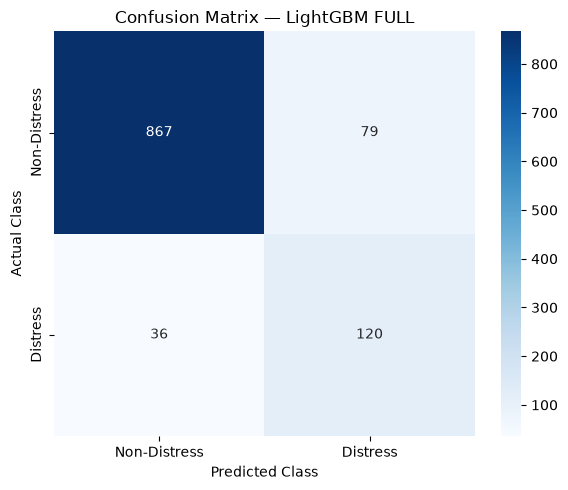

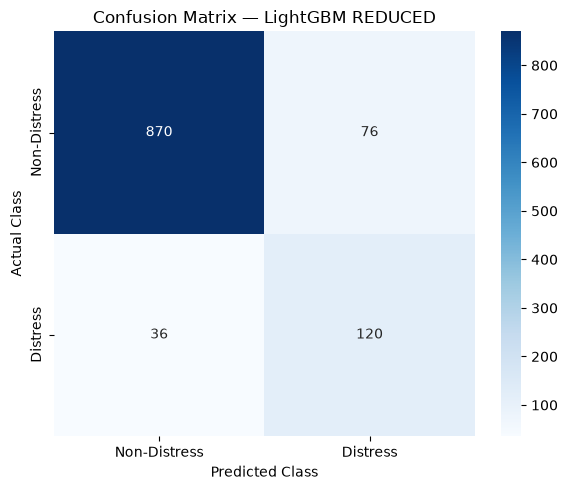

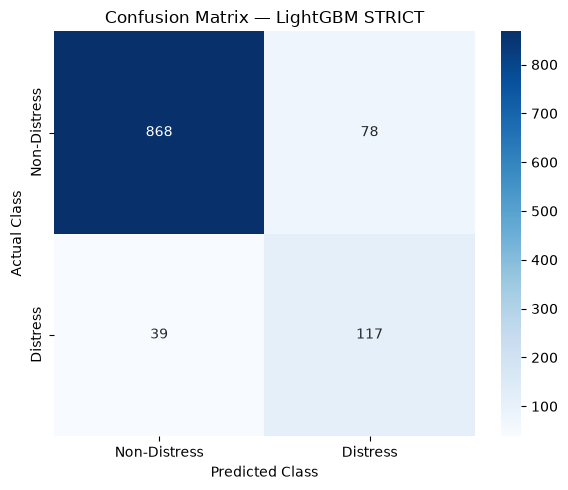


COMPLETED SUCCESSFULLY


In [39]:
# ================================================================
# INDEPENDENT TEST PERFORMANCE EVALUATION
# FINAL LIGHTGBM MODELS
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")


# ================================================================
# FINAL OPERATIONAL THRESHOLDS
# ================================================================

FINAL_THRESHOLDS = {
    "FULL": 0.50,
    "REDUCED": 0.50,
    "STRICT": 0.50
}


# ================================================================
# INDEPENDENT TEST DATA
# ================================================================

test_df = model_df_winsorized[
    model_df_winsorized["Predictor_Year"].between(2023, 2024)
].copy()

TARGET = "Target_Distress"

y_test = test_df[TARGET].astype(int)

print("=" * 100)
print("INDEPENDENT TEST DATA VERIFICATION")
print("=" * 100)

print("Test observations:", len(test_df))
print("Distress cases:", int(y_test.sum()))
print("Non-distress cases:", int((y_test == 0).sum()))
print("Distress rate:", round(y_test.mean(), 4))

assert len(test_df) == 1102


# ================================================================
# PERFORMANCE METRICS FUNCTION
# ================================================================

def calculate_performance(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {

        "ROC_AUC": roc_auc_score(
            y_true, probabilities
        ),

        "PR_AUC": average_precision_score(
            y_true, probabilities
        ),

        "Brier_Score": brier_score_loss(
            y_true, probabilities
        ),

        "Log_Loss": log_loss(
            y_true, probabilities
        ),

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Sensitivity": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "Specificity": tn / (tn + fp)
            if (tn + fp) > 0 else 0,

        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "F1_Score": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


# ================================================================
# EVALUATE FULL, REDUCED AND STRICT
# ================================================================

TEST_RESULTS = []

TEST_PREDICTIONS = {}

CONFUSION_MATRICES = {}

for model_name in ["FULL", "REDUCED", "STRICT"]:

    print("\n" + "=" * 90)
    print("EVALUATING:", model_name)
    print("=" * 90)

    features = FINAL_CONFIGS[model_name]["features"]

    model = FINAL_DEVELOPMENT_MODELS[model_name]

    threshold = FINAL_THRESHOLDS[model_name]

    X_test = test_df[features].copy()

    # Predicted probabilities

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    # Classification

    predictions = (
        probabilities >= threshold
    ).astype(int)

    TEST_PREDICTIONS[model_name] = probabilities

    # Performance

    metrics = calculate_performance(
        y_test,
        probabilities,
        threshold
    )

    results = {

        "Algorithm": "LightGBM",
        "Model": model_name,
        "Predictors": len(features),
        "Observations": len(test_df),
        "Threshold": threshold,

        **metrics

    }

    TEST_RESULTS.append(results)

    CONFUSION_MATRICES[model_name] = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    print("ROC-AUC:", round(metrics["ROC_AUC"], 4))
    print("PR-AUC:", round(metrics["PR_AUC"], 4))
    print("Brier Score:", round(metrics["Brier_Score"], 4))
    print("Log Loss:", round(metrics["Log_Loss"], 4))
    print("Accuracy:", round(metrics["Accuracy"], 4))
    print("Sensitivity:", round(metrics["Sensitivity"], 4))
    print("Specificity:", round(metrics["Specificity"], 4))
    print("Precision:", round(metrics["Precision"], 4))
    print("F1-score:", round(metrics["F1_Score"], 4))


# ================================================================
# CONSOLIDATED TEST PERFORMANCE
# ================================================================

TEST_RESULTS_DF = pd.DataFrame(TEST_RESULTS)

print("\n" + "=" * 120)
print("CONSOLIDATED INDEPENDENT TEST PERFORMANCE")
print("=" * 120)

display(
    TEST_RESULTS_DF.round(4)
)


# ================================================================
# CONFUSION MATRICES
# ================================================================

for model_name, matrix in CONFUSION_MATRICES.items():

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Distress", "Distress"],
        yticklabels=["Non-Distress", "Distress"]
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.title(
        f"Confusion Matrix — LightGBM {model_name}"
    )

    plt.tight_layout()

    plt.savefig(
        f"CONFUSION_MATRIX_{model_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ================================================================
# SAVE TEST PREDICTIONS
# ================================================================

TEST_PREDICTIONS_DF = pd.DataFrame({

    "Predictor_Year": test_df["Predictor_Year"].values,

    "Actual_Distress": y_test.values,

    "FULL_Probability": TEST_PREDICTIONS["FULL"],

    "REDUCED_Probability": TEST_PREDICTIONS["REDUCED"],

    "STRICT_Probability": TEST_PREDICTIONS["STRICT"]

})

for model_name in ["FULL", "REDUCED", "STRICT"]:

    TEST_PREDICTIONS_DF[
        f"{model_name}_Prediction"
    ] = (
        TEST_PREDICTIONS[model_name] >= 0.50
    ).astype(int)


# ================================================================
# EXPORT RESULTS
# ================================================================

TEST_RESULTS_DF.to_csv(
    "LIGHTGBM_INDEPENDENT_TEST_PERFORMANCE.csv",
    index=False
)

TEST_PREDICTIONS_DF.to_csv(
    "LIGHTGBM_TEST_PREDICTIONS.csv",
    index=False
)

print("\n" + "=" * 100)
print("COMPLETED SUCCESSFULLY")
print("=" * 100)

In [41]:
# ================================================================
# FINAL OUT-OF-TIME PERFORMANCE EVALUATION
# LIGHTGBM FULL / REDUCED / STRICT
# ================================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ================================================================
# FINAL OOT DATASET
# ================================================================

oot_df = model_df_winsorized[
    model_df_winsorized["Predictor_Year"] == 2025
].copy()

TARGET = "Target_Distress"

y_oot = oot_df[TARGET].astype(int)

print("=" * 100)
print("FINAL OUT-OF-TIME DATA VERIFICATION")
print("=" * 100)

print("Observations:", len(oot_df))
print("Distress cases:", int(y_oot.sum()))
print("Non-distress cases:", int((y_oot == 0).sum()))
print("Distress rate:", round(y_oot.mean(), 4))

assert len(oot_df) == 551

# ================================================================
# FIXED OPERATIONAL THRESHOLDS
# ================================================================

FINAL_THRESHOLDS = {
    "FULL": 0.50,
    "REDUCED": 0.50,
    "STRICT": 0.50
}

# ================================================================
# OOT MODEL EVALUATION
# ================================================================

OOT_RESULTS = []
OOT_PREDICTIONS = {}

for model_name in ["FULL", "REDUCED", "STRICT"]:

    print("\n" + "=" * 90)
    print("FINAL OOT EVALUATION:", model_name)
    print("=" * 90)

    features = FINAL_CONFIGS[model_name]["features"]

    model = FINAL_DEVELOPMENT_MODELS[model_name]

    X_oot = oot_df[features].copy()

    probabilities = model.predict_proba(
        X_oot
    )[:, 1]

    threshold = FINAL_THRESHOLDS[model_name]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    OOT_PREDICTIONS[model_name] = probabilities

    # Confusion matrix

    tn, fp, fn, tp = confusion_matrix(
        y_oot,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Performance metrics

    results = {

        "Algorithm": "LightGBM",
        "Model": model_name,

        "Predictors": len(features),
        "Observations": len(oot_df),

        "Threshold": threshold,

        "ROC_AUC": roc_auc_score(
            y_oot, probabilities
        ),

        "PR_AUC": average_precision_score(
            y_oot, probabilities
        ),

        "Brier_Score": brier_score_loss(
            y_oot, probabilities
        ),

        "Log_Loss": log_loss(
            y_oot, probabilities
        ),

        "Accuracy": accuracy_score(
            y_oot, predictions
        ),

        "Sensitivity": recall_score(
            y_oot, predictions,
            zero_division=0
        ),

        "Specificity": tn / (tn + fp),

        "Precision": precision_score(
            y_oot, predictions,
            zero_division=0
        ),

        "F1_Score": f1_score(
            y_oot, predictions,
            zero_division=0
        ),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    OOT_RESULTS.append(results)

    print("ROC-AUC:", round(results["ROC_AUC"], 4))
    print("PR-AUC:", round(results["PR_AUC"], 4))
    print("Brier:", round(results["Brier_Score"], 4))
    print("Log Loss:", round(results["Log_Loss"], 4))
    print("Accuracy:", round(results["Accuracy"], 4))
    print("Sensitivity:", round(results["Sensitivity"], 4))
    print("Specificity:", round(results["Specificity"], 4))
    print("Precision:", round(results["Precision"], 4))
    print("F1-score:", round(results["F1_Score"], 4))

    print("TN:", tn, "FP:", fp)
    print("FN:", fn, "TP:", tp)


# ================================================================
# CONSOLIDATED OOT RESULTS
# ================================================================

OOT_RESULTS_DF = pd.DataFrame(OOT_RESULTS)

print("\n" + "=" * 120)
print("CONSOLIDATED FINAL OOT PERFORMANCE")
print("=" * 120)

display(OOT_RESULTS_DF.round(4))


# ================================================================
# SAVE OOT RESULTS
# ================================================================

OOT_RESULTS_DF.to_csv(
    "LIGHTGBM_FINAL_OOT_PERFORMANCE.csv",
    index=False
)

# ================================================================
# SAVE OOT PREDICTIONS
# ================================================================

OOT_PREDICTIONS_DF = pd.DataFrame({

    "Predictor_Year": oot_df["Predictor_Year"].values,

    "Actual_Distress": y_oot.values,

    "FULL_Probability": OOT_PREDICTIONS["FULL"],

    "REDUCED_Probability": OOT_PREDICTIONS["REDUCED"],

    "STRICT_Probability": OOT_PREDICTIONS["STRICT"]

})

for name in ["FULL", "REDUCED", "STRICT"]:

    OOT_PREDICTIONS_DF[
        f"{name}_Prediction"
    ] = (
        OOT_PREDICTIONS[name] >= 0.50
    ).astype(int)

OOT_PREDICTIONS_DF.to_csv(
    "LIGHTGBM_FINAL_OOT_PREDICTIONS.csv",
    index=False
)

print("\nCOMPLETED SUCCESSFULLY.")

FINAL OUT-OF-TIME DATA VERIFICATION
Observations: 551
Distress cases: 77
Non-distress cases: 474
Distress rate: 0.1397

FINAL OOT EVALUATION: FULL
ROC-AUC: 0.9357
PR-AUC: 0.7733
Brier: 0.071
Log Loss: 0.2373
Accuracy: 0.8966
Sensitivity: 0.7922
Specificity: 0.9135
Precision: 0.598
F1-score: 0.6816
TN: 433 FP: 41
FN: 16 TP: 61

FINAL OOT EVALUATION: REDUCED
ROC-AUC: 0.9359
PR-AUC: 0.7664
Brier: 0.0712
Log Loss: 0.2426
Accuracy: 0.8929
Sensitivity: 0.7922
Specificity: 0.9093
Precision: 0.5865
F1-score: 0.674
TN: 431 FP: 43
FN: 16 TP: 61

FINAL OOT EVALUATION: STRICT
ROC-AUC: 0.937
PR-AUC: 0.7748
Brier: 0.0707
Log Loss: 0.2423
Accuracy: 0.8966
Sensitivity: 0.7792
Specificity: 0.9156
Precision: 0.6
F1-score: 0.678
TN: 434 FP: 40
FN: 17 TP: 60

CONSOLIDATED FINAL OOT PERFORMANCE


,Algorithm,Model,Predictors,Observations,Threshold,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Accuracy,Sensitivity,Specificity,Precision,F1_Score,TN,FP,FN,TP
0,LightGBM,FULL,21,551,0.5,0.9357,0.7733,0.0710,0.2373,0.8966,0.7922,0.9135,0.5980,0.6816,433,41,16,61
1,LightGBM,REDUCED,17,551,0.5,0.9359,0.7664,0.0712,0.2426,0.8929,0.7922,0.9093,0.5865,0.6740,431,43,16,61
2,LightGBM,STRICT,13,551,0.5,0.9370,0.7748,0.0707,0.2423,0.8966,0.7792,0.9156,0.6000,0.6780,434,40,17,60



COMPLETED SUCCESSFULLY.


In [42]:
# ==========================================================================================
# PAIRED FIRM-LEVEL BOOTSTRAP
# FINAL OOT EVALUATION: FULL vs REDUCED vs STRICT
# 2,000 REPLICATIONS
# ==========================================================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

from itertools import combinations

# ------------------------------------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------------------------------------

N_BOOTSTRAP = 2000
RANDOM_STATE = 42
THRESHOLD = 0.50

FIRM_COL = "Company Name"
TARGET_COL = "Target_Distress"

MODEL_NAMES = ["FULL", "REDUCED", "STRICT"]

rng = np.random.default_rng(RANDOM_STATE)

# ------------------------------------------------------------------------------------------
# PREPARE FINAL OOT DATA
# ------------------------------------------------------------------------------------------

oot_boot = oot_df.copy().reset_index(drop=True)

required_columns = [FIRM_COL, TARGET_COL]

missing_columns = [
    col for col in required_columns
    if col not in oot_boot.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

oot_boot[TARGET_COL] = oot_boot[TARGET_COL].astype(int)

assert len(oot_boot) == 551, "Unexpected OOT sample size."
assert oot_boot[FIRM_COL].nunique() == 551, (
    "OOT data must contain one observation per firm for this implementation."
)

assert set(oot_boot[TARGET_COL].unique()).issubset({0, 1})

y_true = oot_boot[TARGET_COL].to_numpy()

print("=" * 100)
print("PAIRED FIRM-LEVEL BOOTSTRAP — FINAL OOT")
print("=" * 100)

print("OOT observations:", len(oot_boot))
print("Unique firms:", oot_boot[FIRM_COL].nunique())
print("Distress cases:", int(y_true.sum()))
print("Non-distress cases:", int((y_true == 0).sum()))
print("Distress rate:", round(y_true.mean(), 4))
print("Bootstrap replications:", N_BOOTSTRAP)

# ------------------------------------------------------------------------------------------
# GENERATE PREDICTIONS FROM THE FINAL DEVELOPMENT MODELS
# ------------------------------------------------------------------------------------------

oot_probabilities = {}
oot_predictions = {}

for model_name in MODEL_NAMES:

    features = FINAL_CONFIGS[model_name]["features"]

    model = FINAL_DEVELOPMENT_MODELS[model_name]

    probabilities = model.predict_proba(
        oot_boot[features]
    )[:, 1]

    predictions = (
        probabilities >= THRESHOLD
    ).astype(int)

    oot_probabilities[model_name] = probabilities
    oot_predictions[model_name] = predictions

    print(
        f"{model_name}: "
        f"Predictors={len(features)}, "
        f"Threshold={THRESHOLD:.2f}"
    )

# ------------------------------------------------------------------------------------------
# METRIC FUNCTION
# ------------------------------------------------------------------------------------------

def calculate_metrics(y, probabilities, threshold=0.50):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "ROC_AUC": roc_auc_score(y, probabilities),

        "PR_AUC": average_precision_score(
            y, probabilities
        ),

        "Brier_Score": brier_score_loss(
            y, probabilities
        ),

        "Log_Loss": log_loss(
            y,
            probabilities,
            labels=[0, 1]
        ),

        "Accuracy": accuracy_score(
            y, predictions
        ),

        "Sensitivity": recall_score(
            y, predictions,
            zero_division=0
        ),

        "Specificity": tn / (tn + fp)
        if (tn + fp) > 0 else np.nan,

        "Precision": precision_score(
            y, predictions,
            zero_division=0
        ),

        "F1_Score": f1_score(
            y, predictions,
            zero_division=0
        )
    }


# ------------------------------------------------------------------------------------------
# ORIGINAL OOT PERFORMANCE
# ------------------------------------------------------------------------------------------

original_metrics = {}

for model_name in MODEL_NAMES:

    original_metrics[model_name] = calculate_metrics(
        y_true,
        oot_probabilities[model_name],
        THRESHOLD
    )

original_results = pd.DataFrame(
    original_metrics
).T

print("\nORIGINAL OOT PERFORMANCE")
display(original_results.round(4))


# ------------------------------------------------------------------------------------------
# PREPARE FIRM-LEVEL RESAMPLING
# ------------------------------------------------------------------------------------------

# Each firm contributes its complete OOT observation(s).
# Firms are sampled with replacement.

firm_groups = {
    firm: np.flatnonzero(
        oot_boot[FIRM_COL].to_numpy() == firm
    )
    for firm in oot_boot[FIRM_COL].unique()
}

firm_ids = np.array(list(firm_groups.keys()), dtype=object)

N_FIRMS = len(firm_ids)

# ------------------------------------------------------------------------------------------
# PAIRED BOOTSTRAP
# ------------------------------------------------------------------------------------------

bootstrap_records = []

valid_replications = 0
invalid_replications = 0

for b in range(N_BOOTSTRAP):

    # Sample the same firms for all three models.
    sampled_firms = rng.choice(
        firm_ids,
        size=N_FIRMS,
        replace=True
    )

    # Convert sampled firms into row positions.
    sampled_indices = np.concatenate([
        firm_groups[firm]
        for firm in sampled_firms
    ])

    y_boot = y_true[sampled_indices]

    # ROC-AUC and PR-AUC require both classes.
    if len(np.unique(y_boot)) < 2:
        invalid_replications += 1
        continue

    valid_replications += 1

    # Evaluate all models on the identical bootstrap sample.
    for model_name in MODEL_NAMES:

        probabilities_boot = (
            oot_probabilities[model_name][sampled_indices]
        )

        metrics = calculate_metrics(
            y_boot,
            probabilities_boot,
            THRESHOLD
        )

        record = {
            "Replication": b + 1,
            "Model": model_name
        }

        record.update(metrics)

        bootstrap_records.append(record)


bootstrap_df = pd.DataFrame(bootstrap_records)

print("\nBOOTSTRAP EXECUTION SUMMARY")
print("Requested replications:", N_BOOTSTRAP)
print("Valid replications:", valid_replications)
print("Invalid replications:", invalid_replications)

# ------------------------------------------------------------------------------------------
# PAIRED MODEL COMPARISONS
# ------------------------------------------------------------------------------------------

# Difference is always:
# Model A metric - Model B metric.
#
# For ROC-AUC, PR-AUC, Accuracy, Sensitivity, Specificity,
# Precision and F1: positive differences favour Model A.
#
# For Brier Score and Log Loss: negative differences favour Model A.

COMPARISON_PAIRS = [
    ("STRICT", "FULL"),
    ("STRICT", "REDUCED"),
    ("REDUCED", "FULL")
]

METRICS = [
    "ROC_AUC",
    "PR_AUC",
    "Brier_Score",
    "Log_Loss",
    "Accuracy",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1_Score"
]

paired_results = []

for model_a, model_b in COMPARISON_PAIRS:

    boot_a = (
        bootstrap_df[
            bootstrap_df["Model"] == model_a
        ]
        .set_index("Replication")
    )

    boot_b = (
        bootstrap_df[
            bootstrap_df["Model"] == model_b
        ]
        .set_index("Replication")
    )

    common_replications = boot_a.index.intersection(
        boot_b.index
    )

    for metric in METRICS:

        differences = (
            boot_a.loc[common_replications, metric].to_numpy()
            -
            boot_b.loc[common_replications, metric].to_numpy()
        )

        differences = differences[
            np.isfinite(differences)
        ]

        original_difference = (
            original_metrics[model_a][metric]
            -
            original_metrics[model_b][metric]
        )

        ci_lower, ci_upper = np.percentile(
            differences,
            [2.5, 97.5]
        )

        paired_results.append({

            "Comparison": f"{model_a} - {model_b}",

            "Metric": metric,

            "Bootstrap_Replications": len(differences),

            "Original_Difference": original_difference,

            "Bootstrap_Mean_Difference": np.mean(
                differences
            ),

            "CI_95_Lower": ci_lower,

            "CI_95_Upper": ci_upper,

            "CI_Excludes_Zero": (
                ci_lower > 0 or ci_upper < 0
            )
        })


paired_results_df = pd.DataFrame(paired_results)

# ------------------------------------------------------------------------------------------
# DISPLAY FINAL PAIRED BOOTSTRAP RESULTS
# ------------------------------------------------------------------------------------------

print("\n" + "=" * 110)
print("PAIRED FIRM-LEVEL BOOTSTRAP RESULTS")
print("=" * 110)

display(
    paired_results_df.round(5)
)

# ------------------------------------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------------------------------------

original_results.to_csv(
    "OOT_ORIGINAL_MODEL_PERFORMANCE.csv",
    index=True
)

bootstrap_df.to_csv(
    "OOT_PAIRED_FIRM_BOOTSTRAP_REPLICATIONS.csv",
    index=False
)

paired_results_df.to_csv(
    "OOT_PAIRED_FIRM_BOOTSTRAP_COMPARISONS.csv",
    index=False
)

print("\nFILES SAVED SUCCESSFULLY:")
print("1. OOT_ORIGINAL_MODEL_PERFORMANCE.csv")
print("2. OOT_PAIRED_FIRM_BOOTSTRAP_REPLICATIONS.csv")
print("3. OOT_PAIRED_FIRM_BOOTSTRAP_COMPARISONS.csv")

print("\nCOMPLETED.")

PAIRED FIRM-LEVEL BOOTSTRAP — FINAL OOT
OOT observations: 551
Unique firms: 551
Distress cases: 77
Non-distress cases: 474
Distress rate: 0.1397
Bootstrap replications: 2000
FULL: Predictors=21, Threshold=0.50
REDUCED: Predictors=17, Threshold=0.50
STRICT: Predictors=13, Threshold=0.50

ORIGINAL OOT PERFORMANCE


,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Accuracy,Sensitivity,Specificity,Precision,F1_Score
FULL,0.9357,0.7733,0.0710,0.2373,0.8966,0.7922,0.9135,0.5980,0.6816
REDUCED,0.9359,0.7664,0.0712,0.2426,0.8929,0.7922,0.9093,0.5865,0.6740
STRICT,0.9370,0.7748,0.0707,0.2423,0.8966,0.7792,0.9156,0.6000,0.6780



BOOTSTRAP EXECUTION SUMMARY
Requested replications: 2000
Valid replications: 2000
Invalid replications: 0

PAIRED FIRM-LEVEL BOOTSTRAP RESULTS


,Comparison,Metric,Bootstrap_Replications,Original_Difference,Bootstrap_Mean_Difference,CI_95_Lower,CI_95_Upper,CI_Excludes_Zero
0,STRICT - FULL,ROC_AUC,2000,0.00132,0.00135,-0.00432,0.00788,False
1,STRICT - FULL,PR_AUC,2000,0.00149,0.00129,-0.01659,0.02218,False
2,STRICT - FULL,Brier_Score,2000,-0.00038,-0.00035,-0.00272,0.00200,False
3,STRICT - FULL,Log_Loss,2000,0.00505,0.00512,-0.00171,0.01158,False
4,STRICT - FULL,Accuracy,2000,0.00000,0.00006,-0.00544,0.00544,False
5,STRICT - FULL,Sensitivity,2000,-0.01299,-0.01278,-0.04167,0.00000,False
6,STRICT - FULL,Specificity,2000,0.00211,0.00214,0.00000,0.00648,False
7,STRICT - FULL,Precision,2000,0.00196,0.00212,-0.01053,0.01848,False
8,STRICT - FULL,F1_Score,2000,-0.00360,-0.00343,-0.02222,0.01130,False
9,STRICT - REDUCED,ROC_AUC,2000,0.00118,0.00120,-0.00271,0.00520,False



FILES SAVED SUCCESSFULLY:
1. OOT_ORIGINAL_MODEL_PERFORMANCE.csv
2. OOT_PAIRED_FIRM_BOOTSTRAP_REPLICATIONS.csv
3. OOT_PAIRED_FIRM_BOOTSTRAP_COMPARISONS.csv

COMPLETED.


OOT PROBABILITY CALIBRATION
Observations: 551
Distress cases: 77
Non-distress cases: 474
Observed distress rate: 0.13975
FULL: Predictors=21, Mean probability=0.20762, Minimum=0.02194, Maximum=0.89497
REDUCED: Predictors=17, Mean probability=0.21060, Minimum=0.03210, Maximum=0.85653
STRICT: Predictors=13, Mean probability=0.21164, Minimum=0.03383, Maximum=0.85377

OOT CALIBRATION PERFORMANCE


,Model,Predictors,Observations,Observed_Distress_Rate,Mean_Predicted_Probability,Brier_Score,Log_Loss,ECE,Calibration_In_The_Large,CITL_CI_Lower,CITL_CI_Upper,CITL_P_Value,Joint_Intercept,Joint_Intercept_CI_Lower,Joint_Intercept_CI_Upper,Calibration_Slope,Slope_CI_Lower,Slope_CI_Upper,Slope_P_Value
0,FULL,21,551,0.13975,0.20762,0.07103,0.23728,0.06787,-0.88532,-1.20375,-0.56690,0.0,-0.89220,-1.22918,-0.55521,1.12611,0.91409,1.33813,0.24370
1,REDUCED,17,551,0.13975,0.21060,0.07122,0.24261,0.07308,-0.82672,-1.12965,-0.52380,0.0,-0.80906,-1.14226,-0.47585,1.25126,1.01521,1.48731,0.03695
2,STRICT,13,551,0.13975,0.21164,0.07065,0.24234,0.07833,-0.82987,-1.13171,-0.52802,0.0,-0.80872,-1.14383,-0.47362,1.27223,1.03446,1.51000,0.02483



--------------------------------------------------------------------------------------------------------------
FULL — CALIBRATION BIN SUMMARY
--------------------------------------------------------------------------------------------------------------


,Bin,Observations,Mean_Predicted,Observed_Frequency,Absolute_Gap,Weighted_Gap
0,1,345,0.03861,0.00870,0.02992,0.01873
1,2,52,0.13757,0.11538,0.02218,0.00209
2,3,23,0.25068,0.13043,0.12024,0.00502
3,4,21,0.34429,0.09524,0.24905,0.00949
4,5,8,0.45274,0.25000,0.20274,0.00294
5,6,14,0.54579,0.21429,0.33151,0.00842
6,7,18,0.64060,0.44444,0.19615,0.00641
7,8,21,0.75328,0.57143,0.18186,0.00693
8,9,49,0.86358,0.77551,0.08807,0.00783



--------------------------------------------------------------------------------------------------------------
REDUCED — CALIBRATION BIN SUMMARY
--------------------------------------------------------------------------------------------------------------


,Bin,Observations,Mean_Predicted,Observed_Frequency,Absolute_Gap,Weighted_Gap
0,1,339,0.04838,0.01180,0.03658,0.02251
1,2,48,0.13873,0.08333,0.05540,0.00483
2,3,32,0.23534,0.12500,0.11034,0.00641
3,4,20,0.34373,0.10000,0.24373,0.00885
4,5,8,0.44081,0.25000,0.19081,0.00277
5,6,24,0.55113,0.29167,0.25947,0.01130
6,7,17,0.65656,0.23529,0.42127,0.01300
7,8,28,0.75983,0.71429,0.04554,0.00231
8,9,35,0.83963,0.85714,0.01751,0.00111



--------------------------------------------------------------------------------------------------------------
STRICT — CALIBRATION BIN SUMMARY
--------------------------------------------------------------------------------------------------------------


,Bin,Observations,Mean_Predicted,Observed_Frequency,Absolute_Gap,Weighted_Gap
0,1,333,0.05054,0.01201,0.03853,0.02328
1,2,56,0.13717,0.08929,0.04788,0.00487
2,3,35,0.24300,0.08571,0.15729,0.00999
3,4,16,0.34324,0.18750,0.15574,0.00452
4,5,11,0.44370,0.18182,0.26188,0.00523
5,6,14,0.55447,0.14286,0.41161,0.01046
6,7,24,0.64979,0.37500,0.27479,0.01197
7,8,27,0.76455,0.66667,0.09788,0.00480
8,9,35,0.83503,0.88571,0.05068,0.00322


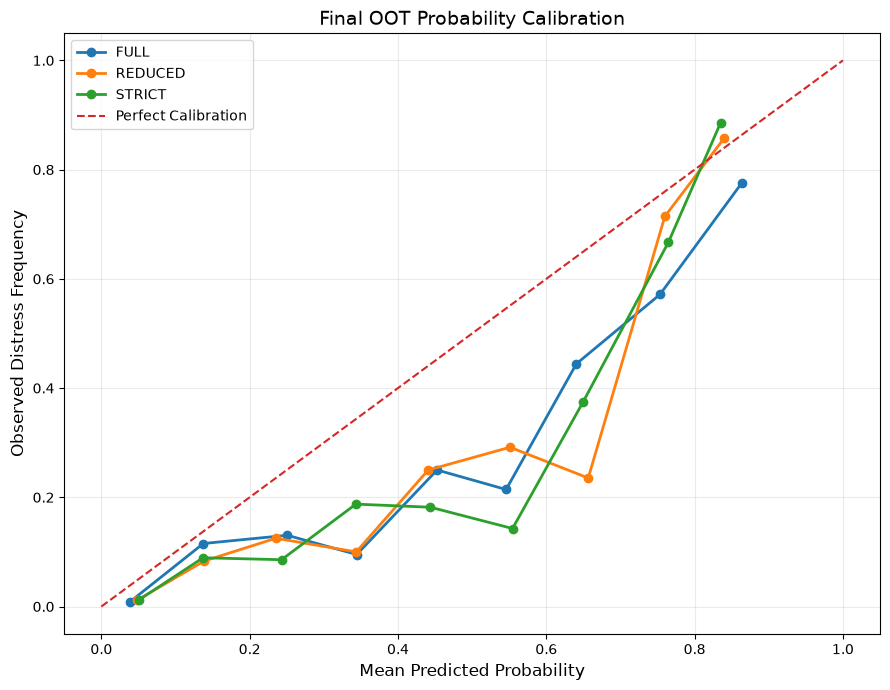


PREDICTED VS OBSERVED DISTRESS RATE


,Model,Observed_Distress_Rate,Mean_Predicted_Probability,Overestimation
0,FULL,0.13975,0.20762,0.06787
1,REDUCED,0.13975,0.21060,0.07086
2,STRICT,0.13975,0.21164,0.07190



FILES SAVED SUCCESSFULLY
1. CALIBRATION_PERFORMANCE.csv
2. PREDICTED_VS_OBSERVED.csv
3. CALIBRATION_BINS_FULL.csv
4. CALIBRATION_BINS_REDUCED.csv
5. CALIBRATION_BINS_STRICT.csv
6. CALIBRATION_CURVES.png
7. CALIBRATION_PROBABILITIES.npz

CALIBRATION COMPLETED.


In [49]:
# ==========================================================================================
# OOT PROBABILITY CALIBRATION
# FULL vs REDUCED vs STRICT LIGHTGBM
# ==========================================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.metrics import (
    brier_score_loss,
    log_loss
)

from sklearn.calibration import calibration_curve

# ------------------------------------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------------------------------------

MODEL_NAMES = ["FULL", "REDUCED", "STRICT"]

TARGET_COL = "Target_Distress"

N_BINS = 10
EPSILON = 1e-10

# ------------------------------------------------------------------------------------------
# PREPARE FINAL OOT DATA
# ------------------------------------------------------------------------------------------

calibration_df = (
    model_df_winsorized[
        model_df_winsorized["Predictor_Year"] == 2025
    ]
    .copy()
    .reset_index(drop=True)
)

y_oot = calibration_df[TARGET_COL].astype(int).to_numpy()

assert len(calibration_df) == 551
assert calibration_df[TARGET_COL].nunique() == 2

print("=" * 110)
print("OOT PROBABILITY CALIBRATION")
print("=" * 110)

print("Observations:", len(calibration_df))
print("Distress cases:", int(y_oot.sum()))
print("Non-distress cases:", int((y_oot == 0).sum()))
print("Observed distress rate:", round(y_oot.mean(), 5))

# ------------------------------------------------------------------------------------------
# REGENERATE OOT PROBABILITIES
# ------------------------------------------------------------------------------------------

fresh_oot_probabilities = {}

for model_name in MODEL_NAMES:

    features = FINAL_CONFIGS[model_name]["features"]

    model = FINAL_DEVELOPMENT_MODELS[model_name]

    probabilities = model.predict_proba(
        calibration_df[features]
    )[:, 1]

    probabilities = np.clip(
        probabilities,
        EPSILON,
        1 - EPSILON
    )

    fresh_oot_probabilities[model_name] = probabilities

    print(
        f"{model_name}: "
        f"Predictors={len(features)}, "
        f"Mean probability={probabilities.mean():.5f}, "
        f"Minimum={probabilities.min():.5f}, "
        f"Maximum={probabilities.max():.5f}"
    )

# ------------------------------------------------------------------------------------------
# EXPECTED CALIBRATION ERROR
# ------------------------------------------------------------------------------------------

def calculate_ece(y_true, probabilities, n_bins=10):

    bin_edges = np.linspace(0, 1, n_bins + 1)

    bin_indices = np.digitize(
        probabilities,
        bin_edges[1:-1],
        right=False
    )

    ece = 0.0

    bin_records = []

    for bin_number in range(n_bins):

        mask = bin_indices == bin_number

        count = int(mask.sum())

        if count == 0:
            continue

        mean_predicted = probabilities[mask].mean()

        observed_frequency = y_true[mask].mean()

        absolute_gap = abs(
            mean_predicted - observed_frequency
        )

        weighted_gap = (
            count / len(y_true)
        ) * absolute_gap

        ece += weighted_gap

        bin_records.append({

            "Bin": bin_number + 1,

            "Observations": count,

            "Mean_Predicted": mean_predicted,

            "Observed_Frequency": observed_frequency,

            "Absolute_Gap": absolute_gap,

            "Weighted_Gap": weighted_gap

        })

    return ece, pd.DataFrame(bin_records)

# ------------------------------------------------------------------------------------------
# CORRECTED CALIBRATION-IN-THE-LARGE AND SLOPE
# ------------------------------------------------------------------------------------------

def calculate_calibration_statistics(y_true, probabilities):

    probabilities = np.clip(
        probabilities,
        EPSILON,
        1 - EPSILON
    )

    logits = np.log(
        probabilities / (1 - probabilities)
    )

    # ------------------------------------------------------------------
    # CALIBRATION-IN-THE-LARGE
    # Intercept estimated with slope fixed at 1
    # ------------------------------------------------------------------

    citl_model = sm.GLM(
        y_true,
        np.ones((len(y_true), 1)),
        family=sm.families.Binomial(),
        offset=logits
    ).fit()

    citl = citl_model.params[0]

    citl_ci = citl_model.conf_int()[0]

    citl_pvalue = citl_model.pvalues[0]

    # ------------------------------------------------------------------
    # JOINT CALIBRATION INTERCEPT AND SLOPE
    # ------------------------------------------------------------------

    X = sm.add_constant(logits)

    joint_model = sm.GLM(
        y_true,
        X,
        family=sm.families.Binomial()
    ).fit()

    joint_intercept = joint_model.params[0]

    joint_slope = joint_model.params[1]

    joint_intercept_ci = joint_model.conf_int()[0]

    slope_ci = joint_model.conf_int()[1]

    # ------------------------------------------------------------------
    # TEST WHETHER SLOPE DIFFERS FROM 1
    # ------------------------------------------------------------------

    slope_test = (
        joint_slope - 1
    ) / joint_model.bse[1]

    from scipy.stats import norm

    slope_pvalue = 2 * norm.sf(
        abs(slope_test)
    )

    return {

        "Calibration_In_The_Large": citl,

        "CITL_CI_Lower": citl_ci[0],

        "CITL_CI_Upper": citl_ci[1],

        "CITL_P_Value": citl_pvalue,

        "Joint_Intercept": joint_intercept,

        "Joint_Intercept_CI_Lower": joint_intercept_ci[0],

        "Joint_Intercept_CI_Upper": joint_intercept_ci[1],

        "Calibration_Slope": joint_slope,

        "Slope_CI_Lower": slope_ci[0],

        "Slope_CI_Upper": slope_ci[1],

        "Slope_P_Value": slope_pvalue

    }

# ------------------------------------------------------------------------------------------
# CALCULATE FINAL CALIBRATION PERFORMANCE
# ------------------------------------------------------------------------------------------

calibration_results = []

calibration_bin_tables = {}

for model_name in MODEL_NAMES:

    probabilities = fresh_oot_probabilities[model_name]

    brier = brier_score_loss(
        y_oot,
        probabilities
    )

    loss = log_loss(
        y_oot,
        probabilities,
        labels=[0, 1]
    )

    ece, bin_table = calculate_ece(
        y_oot,
        probabilities,
        N_BINS
    )

    calibration_statistics = calculate_calibration_statistics(
        y_oot,
        probabilities
    )

    calibration_bin_tables[model_name] = bin_table

    calibration_results.append({

        "Model": model_name,

        "Predictors": len(
            FINAL_CONFIGS[model_name]["features"]
        ),

        "Observations": len(y_oot),

        "Observed_Distress_Rate": y_oot.mean(),

        "Mean_Predicted_Probability": probabilities.mean(),

        "Brier_Score": brier,

        "Log_Loss": loss,

        "ECE": ece,

        **calibration_statistics

    })

calibration_results_df = pd.DataFrame(
    calibration_results
)

# ------------------------------------------------------------------------------------------
# DISPLAY CALIBRATION PERFORMANCE
# ------------------------------------------------------------------------------------------

print("\n" + "=" * 130)
print("OOT CALIBRATION PERFORMANCE")
print("=" * 130)

display(
    calibration_results_df.round(5)
)

# ------------------------------------------------------------------------------------------
# DISPLAY CALIBRATION BIN TABLES
# ------------------------------------------------------------------------------------------

for model_name in MODEL_NAMES:

    print("\n" + "-" * 110)
    print(f"{model_name} — CALIBRATION BIN SUMMARY")
    print("-" * 110)

    display(
        calibration_bin_tables[model_name].round(5)
    )

# ------------------------------------------------------------------------------------------
# CALIBRATION CURVE
# ------------------------------------------------------------------------------------------

plt.figure(figsize=(9, 7))

for model_name in MODEL_NAMES:

    probabilities = fresh_oot_probabilities[model_name]

    fraction_positive, mean_predicted = calibration_curve(
        y_oot,
        probabilities,
        n_bins=N_BINS,
        strategy="uniform"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        linewidth=2,
        markersize=6,
        label=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect Calibration"
)

plt.xlabel(
    "Mean Predicted Probability",
    fontsize=12
)

plt.ylabel(
    "Observed Distress Frequency",
    fontsize=12
)

plt.title(
    "Final OOT Probability Calibration",
    fontsize=14
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "FRESH_FINAL_OOT_CALIBRATION_CURVES.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------------------------------------
# MEAN PREDICTED VS OBSERVED PROBABILITY
# ------------------------------------------------------------------------------------------

rate_comparison = calibration_results_df[
    [
        "Model",
        "Observed_Distress_Rate",
        "Mean_Predicted_Probability"
    ]
].copy()

rate_comparison["Overestimation"] = (
    rate_comparison["Mean_Predicted_Probability"]
    - rate_comparison["Observed_Distress_Rate"]
)

print("\nPREDICTED VS OBSERVED DISTRESS RATE")

display(
    rate_comparison.round(5)
)

# ------------------------------------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------------------------------------

calibration_results_df.to_csv(
    "CALIBRATION_PERFORMANCE.csv",
    index=False
)

rate_comparison.to_csv(
    "PREDICTED_VS_OBSERVED.csv",
    index=False
)

for model_name in MODEL_NAMES:

    calibration_bin_tables[model_name].to_csv(
        f"CALIBRATION_BINS_{model_name}.csv",
        index=False
    )

np.savez(
    "OOT_CALIBRATION_PROBABILITIES.npz",
    FULL=fresh_oot_probabilities["FULL"],
    REDUCED=fresh_oot_probabilities["REDUCED"],
    STRICT=fresh_oot_probabilities["STRICT"],
    y_true=y_oot
)

print("\nFILES SAVED SUCCESSFULLY")

print("1. CALIBRATION_PERFORMANCE.csv")
print("2. PREDICTED_VS_OBSERVED.csv")
print("3. CALIBRATION_BINS_FULL.csv")
print("4. CALIBRATION_BINS_REDUCED.csv")
print("5. CALIBRATION_BINS_STRICT.csv")
print("6. CALIBRATION_CURVES.png")
print("7. CALIBRATION_PROBABILITIES.npz")

print("\nCALIBRATION COMPLETED.")

In [50]:
# ==========================================================================================
# CALIBRATION INTERCEPT AND SLOPE
# FINAL OOT: FULL, REDUCED AND STRICT
# ==========================================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

EPSILON = 1e-10

corrected_calibration_results = []

for model_name in ["FULL", "REDUCED", "STRICT"]:

    probabilities = np.clip(
        oot_probabilities[model_name],
        EPSILON,
        1 - EPSILON
    )

    logits = np.log(
        probabilities / (1 - probabilities)
    )

    # ------------------------------------------------------------------
    # CALIBRATION-IN-THE-LARGE
    # Intercept estimated with slope fixed at 1
    # ------------------------------------------------------------------

    citl_model = sm.GLM(
        y_oot,
        np.ones((len(y_oot), 1)),
        family=sm.families.Binomial(),
        offset=logits
    ).fit()

    citl = citl_model.params[0]

    citl_ci = citl_model.conf_int()[0]

    # ------------------------------------------------------------------
    # CALIBRATION SLOPE
    # Intercept and slope estimated simultaneously
    # ------------------------------------------------------------------

    X = sm.add_constant(logits)

    slope_model = sm.GLM(
        y_oot,
        X,
        family=sm.families.Binomial()
    ).fit()

    calibration_intercept = slope_model.params[0]

    calibration_slope = slope_model.params[1]

    slope_ci = slope_model.conf_int()[1]

    intercept_ci = slope_model.conf_int()[0]

    corrected_calibration_results.append({

        "Model": model_name,

        "Calibration_In_The_Large": citl,

        "CITL_CI_Lower": citl_ci[0],

        "CITL_CI_Upper": citl_ci[1],

        "Joint_Intercept": calibration_intercept,

        "Joint_Intercept_CI_Lower": intercept_ci[0],

        "Joint_Intercept_CI_Upper": intercept_ci[1],

        "Calibration_Slope": calibration_slope,

        "Slope_CI_Lower": slope_ci[0],

        "Slope_CI_Upper": slope_ci[1],

        "CITL_P_Value": citl_model.pvalues[0],

        "Slope_P_Value": slope_model.pvalues[1]

    })


corrected_calibration_df = pd.DataFrame(
    corrected_calibration_results
)

print("=" * 110)
print("OOT CALIBRATION INTERCEPT AND SLOPE")
print("=" * 110)

display(
    corrected_calibration_df.round(5)
)

corrected_calibration_df.to_csv(
    "FINAL_OOT_CORRECTED_CALIBRATION_PARAMETERS.csv",
    index=False
)

print("\ncalibration parameters saved.")

OOT CALIBRATION INTERCEPT AND SLOPE


,Model,Calibration_In_The_Large,CITL_CI_Lower,CITL_CI_Upper,Joint_Intercept,Joint_Intercept_CI_Lower,Joint_Intercept_CI_Upper,Calibration_Slope,Slope_CI_Lower,Slope_CI_Upper,CITL_P_Value,Slope_P_Value
0,FULL,-0.88532,-1.20375,-0.56690,-0.89220,-1.22918,-0.55521,1.12611,0.91409,1.33813,0.0,0.0
1,REDUCED,-0.82672,-1.12965,-0.52380,-0.80906,-1.14226,-0.47585,1.25126,1.01521,1.48731,0.0,0.0
2,STRICT,-0.82987,-1.13171,-0.52802,-0.80872,-1.14383,-0.47362,1.27223,1.03446,1.51000,0.0,0.0



calibration parameters saved.


In [52]:
# ============================================================
# CONSTRUCT NAIVE PERSISTENCE VARIABLE
# ============================================================

import pandas as pd
import numpy as np

df_persistence = model_df_winsorized.copy()

COMPANY_COL = "Company Name"

# Validate required columns
required = [
    COMPANY_COL,
    "Predictor_Year",
    "Target_Distress"
]

missing = [c for c in required if c not in df_persistence.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Check company-year uniqueness
if df_persistence.duplicated(
    subset=[COMPANY_COL, "Predictor_Year"]
).any():
    raise ValueError("Duplicate company-year observations detected.")

# Sort chronologically
df_persistence = df_persistence.sort_values(
    [COMPANY_COL, "Predictor_Year"]
).copy()

# Previous year's actual distress status
df_persistence["Distress_t1"] = (
    df_persistence
    .groupby(COMPANY_COL)["Target_Distress"]
    .shift(1)
)

# Extract 2025 predictor-year observations
oot_persistence = df_persistence[
    df_persistence["Predictor_Year"] == 2025
].copy()

# Validate temporal continuity
if not (oot_persistence["Predictor_Year"] == 2025).all():
    raise ValueError("Incorrect OOT predictor year.")

if oot_persistence["Distress_t1"].isna().any():
    raise ValueError(
        "Previous-year distress status is missing for some companies."
    )

oot_persistence["Distress_t1"] = (
    oot_persistence["Distress_t1"].astype(int)
)

print("=" * 75)
print("NAIVE PERSISTENCE VARIABLE — VALIDATION")
print("=" * 75)

print("OOT observations:", len(oot_persistence))
print("Unique companies:", oot_persistence[COMPANY_COL].nunique())

print("\nPrevious-year distress distribution:")
print(oot_persistence["Distress_t1"].value_counts())

print("\n2026 target distress distribution:")
print(oot_persistence["Target_Distress"].value_counts())

print("\nPrevious-year distress vs target-year distress:")
print(
    pd.crosstab(
        oot_persistence["Distress_t1"],
        oot_persistence["Target_Distress"],
        margins=True
    )
)

print("\nNaive Persistence variable constructed successfully.")

NAIVE PERSISTENCE VARIABLE — VALIDATION
OOT observations: 551
Unique companies: 551

Previous-year distress distribution:
Distress_t1
0    477
1     74
Name: count, dtype: int64

2026 target distress distribution:
Target_Distress
0    474
1     77
Name: count, dtype: int64

Previous-year distress vs target-year distress:
Target_Distress    0   1  All
Distress_t1                  
0                455  22  477
1                 19  55   74
All              474  77  551

Naive Persistence variable constructed successfully.


In [59]:
# ============================================================
# NAIVE PERSISTENCE VS THREE LIGHTGBM MODELS
# FINAL OOT EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss,
    log_loss
)

# ------------------------------------------------------------
# DATA
# ------------------------------------------------------------

evaluation_df = oot_persistence.copy()

y_true = evaluation_df["Target_Distress"].astype(int).to_numpy()

# ------------------------------------------------------------
# PREDICTION STORAGE
# ------------------------------------------------------------

model_predictions = {}

# ------------------------------------------------------------
# THREE LIGHTGBM MODELS
# ------------------------------------------------------------

for model_name in ["FULL", "REDUCED", "STRICT"]:

    features = FINAL_CONFIGS[model_name]["features"]

    model = FINAL_DEVELOPMENT_MODELS[model_name]

    X_oot = evaluation_df[features]

    # Obtain continuous distress probabilities
    probabilities = model.predict_proba(X_oot)[:, 1]

    # Fixed threshold = 0.50
    predictions = (probabilities >= 0.50).astype(int)

    model_predictions[model_name] = {
        "probability": probabilities,
        "prediction": predictions,
        "predictors": len(features)
    }

# ------------------------------------------------------------
# NAIVE PERSISTENCE
# ------------------------------------------------------------

persistence_prediction = (
    evaluation_df["Distress_t1"].astype(int).to_numpy()
)

model_predictions["NAIVE_PERSISTENCE"] = {
    "probability": persistence_prediction.astype(float),
    "prediction": persistence_prediction,
    "predictors": 0
}

print("All four model predictions generated.")

All four model predictions generated.


In [60]:
# ============================================================
# CONSOLIDATED OOT PERFORMANCE
# ============================================================

results = []

for model_name, output in model_predictions.items():

    probabilities = output["probability"]
    predictions = output["prediction"]

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    is_persistence = model_name == "NAIVE_PERSISTENCE"

    row = {
        "Model": model_name,
        "Predictors": output["predictors"],
        "Threshold": (
            "Previous-year status"
            if is_persistence else 0.50
        ),

        "ROC_AUC": roc_auc_score(
            y_true, probabilities
        ),

        "PR_AUC": average_precision_score(
            y_true, probabilities
        ),

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Sensitivity": recall_score(
            y_true, predictions, zero_division=0
        ),

        "Specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0 else np.nan
        ),

        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),

        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    # Probability-based metrics are appropriate for LightGBM.
    # Persistence provides binary scores, not calibrated probabilities.
    if not is_persistence:
        row["Brier_Score"] = brier_score_loss(
            y_true, probabilities
        )

        row["Log_Loss"] = log_loss(
            y_true, probabilities
        )
    else:
        row["Brier_Score"] = np.nan
        row["Log_Loss"] = np.nan

    results.append(row)

comparison_all_models = pd.DataFrame(results)

comparison_all_models = comparison_all_models[
    [
        "Model",
        "Predictors",
        "Threshold",
        "ROC_AUC",
        "PR_AUC",
        "Brier_Score",
        "Log_Loss",
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Precision",
        "F1",
        "TN",
        "FP",
        "FN",
        "TP"
    ]
]

print("=" * 120)
print("FINAL OOT PERFORMANCE — NAIVE PERSISTENCE VS THREE LIGHTGBM MODELS")
print("=" * 120)

display(comparison_all_models.round(4))

FINAL OOT PERFORMANCE — NAIVE PERSISTENCE VS THREE LIGHTGBM MODELS


,Model,Predictors,Threshold,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Accuracy,Sensitivity,Specificity,Precision,F1,TN,FP,FN,TP
0,FULL,21,0.5,0.9357,0.7733,0.0710,0.2373,0.8966,0.7922,0.9135,0.5980,0.6816,433,41,16,61
1,REDUCED,17,0.5,0.9359,0.7664,0.0712,0.2426,0.8929,0.7922,0.9093,0.5865,0.6740,431,43,16,61
2,STRICT,13,0.5,0.9370,0.7748,0.0707,0.2423,0.8966,0.7792,0.9156,0.6000,0.6780,434,40,17,60
3,NAIVE_PERSISTENCE,0,Previous-year status,0.8371,0.5708,NaN,NaN,0.9256,0.7143,0.9599,0.7432,0.7285,455,19,22,55


In [61]:
# ============================================================
# PERFORMANCE DIFFERENCES AGAINST PERSISTENCE
# ============================================================

metrics_to_compare = [
    "ROC_AUC",
    "PR_AUC",
    "Accuracy",
    "Sensitivity",
    "Specificity",
    "Precision",
    "F1"
]

persistence_row = comparison_all_models[
    comparison_all_models["Model"] == "NAIVE_PERSISTENCE"
].iloc[0]

difference_results = []

for model_name in ["FULL", "REDUCED", "STRICT"]:

    model_row = comparison_all_models[
        comparison_all_models["Model"] == model_name
    ].iloc[0]

    row = {"Model": model_name}

    for metric in metrics_to_compare:

        row[f"{metric}_Difference"] = (
            model_row[metric] - persistence_row[metric]
        )

    difference_results.append(row)

difference_df = pd.DataFrame(difference_results)

print("=" * 115)
print("LIGHTGBM PERFORMANCE DIFFERENCES RELATIVE TO NAIVE PERSISTENCE")
print("=" * 115)

display(difference_df.round(4))

LIGHTGBM PERFORMANCE DIFFERENCES RELATIVE TO NAIVE PERSISTENCE


,Model,ROC_AUC_Difference,PR_AUC_Difference,Accuracy_Difference,Sensitivity_Difference,Specificity_Difference,Precision_Difference,F1_Difference
0,FULL,0.0986,0.2025,-0.0290,0.0779,-0.0464,-0.1452,-0.0469
1,REDUCED,0.0988,0.1955,-0.0327,0.0779,-0.0506,-0.1567,-0.0544
2,STRICT,0.0999,0.2039,-0.0290,0.0649,-0.0443,-0.1432,-0.0505


In [62]:
# ============================================================
# PAIRED COMPANY-LEVEL BOOTSTRAP
# THREE LIGHTGBM MODELS VS NAIVE PERSISTENCE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

N_BOOTSTRAP = 2000
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

# Actual OOT outcomes
y = np.asarray(y_true).astype(int)

# Models
models_to_compare = [
    "FULL",
    "REDUCED",
    "STRICT",
    "NAIVE_PERSISTENCE"
]

# Validate arrays
for model_name in models_to_compare:

    assert len(model_predictions[model_name]["prediction"]) == len(y)
    assert len(model_predictions[model_name]["probability"]) == len(y)

# ------------------------------------------------------------
# METRIC FUNCTION
# ------------------------------------------------------------

def calculate_bootstrap_metrics(y_actual, y_pred, y_score):

    tn, fp, fn, tp = confusion_matrix(
        y_actual,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "ROC_AUC": roc_auc_score(y_actual, y_score),

        "PR_AUC": average_precision_score(
            y_actual, y_score
        ),

        "Accuracy": accuracy_score(
            y_actual, y_pred
        ),

        "Sensitivity": recall_score(
            y_actual, y_pred, zero_division=0
        ),

        "Specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0 else np.nan
        ),

        "Precision": precision_score(
            y_actual, y_pred, zero_division=0
        ),

        "F1": f1_score(
            y_actual, y_pred, zero_division=0
        )
    }


# ------------------------------------------------------------
# PAIRED BOOTSTRAP
# ------------------------------------------------------------

comparisons = [
    ("FULL", "NAIVE_PERSISTENCE"),
    ("REDUCED", "NAIVE_PERSISTENCE"),
    ("STRICT", "NAIVE_PERSISTENCE"),
    ("STRICT", "FULL"),
    ("STRICT", "REDUCED")
]

bootstrap_records = []

for replication in range(N_BOOTSTRAP):

    # Identical sampled firms for all models
    indices = rng.choice(
        np.arange(len(y)),
        size=len(y),
        replace=True
    )

    y_b = y[indices]

    # Both classes required for ROC-AUC
    if len(np.unique(y_b)) < 2:
        continue

    metric_results = {}

    for model_name in models_to_compare:

        y_pred = np.asarray(
            model_predictions[model_name]["prediction"]
        )[indices]

        y_score = np.asarray(
            model_predictions[model_name]["probability"]
        )[indices]

        metric_results[model_name] = calculate_bootstrap_metrics(
            y_b,
            y_pred,
            y_score
        )

    # Paired differences
    for model_a, model_b in comparisons:

        for metric in metric_results[model_a]:

            difference = (
                metric_results[model_a][metric]
                - metric_results[model_b][metric]
            )

            bootstrap_records.append({
                "Replication": replication + 1,
                "Comparison": f"{model_a} - {model_b}",
                "Metric": metric,
                "Difference": difference
            })


bootstrap_results = pd.DataFrame(bootstrap_records)

# ------------------------------------------------------------
# SUMMARISE CONFIDENCE INTERVALS
# ------------------------------------------------------------

summary_records = []

for (comparison, metric), group in bootstrap_results.groupby(
    ["Comparison", "Metric"]
):

    differences = group["Difference"].dropna().to_numpy()

    summary_records.append({

        "Comparison": comparison,

        "Metric": metric,

        "Valid_Replications": len(differences),

        "Mean_Difference": np.mean(differences),

        "CI_95_Lower": np.percentile(
            differences, 2.5
        ),

        "CI_95_Upper": np.percentile(
            differences, 97.5
        )

    })


bootstrap_summary = pd.DataFrame(summary_records)

print("=" * 110)
print("PAIRED COMPANY-LEVEL BOOTSTRAP RESULTS")
print("=" * 110)

print("Valid bootstrap replications:",
      bootstrap_results["Replication"].nunique())

display(
    bootstrap_summary.round(5)
)

PAIRED COMPANY-LEVEL BOOTSTRAP RESULTS
Valid bootstrap replications: 2000


,Comparison,Metric,Valid_Replications,Mean_Difference,CI_95_Lower,CI_95_Upper
0,FULL - NAIVE_PERSISTENCE,Accuracy,2000,-0.02898,-0.04900,-0.00907
1,FULL - NAIVE_PERSISTENCE,F1,2000,-0.04654,-0.11171,0.02060
2,FULL - NAIVE_PERSISTENCE,PR_AUC,2000,0.20360,0.12744,0.28019
3,FULL - NAIVE_PERSISTENCE,Precision,2000,-0.14509,-0.21984,-0.07970
4,FULL - NAIVE_PERSISTENCE,ROC_AUC,2000,0.09886,0.05614,0.14341
5,FULL - NAIVE_PERSISTENCE,Sensitivity,2000,0.07844,0.00000,0.16667
6,FULL - NAIVE_PERSISTENCE,Specificity,2000,-0.04636,-0.06627,-0.02911
7,REDUCED - NAIVE_PERSISTENCE,Accuracy,2000,-0.03265,-0.05445,-0.01270
8,REDUCED - NAIVE_PERSISTENCE,F1,2000,-0.05418,-0.12056,0.01423
9,REDUCED - NAIVE_PERSISTENCE,PR_AUC,2000,0.19661,0.12132,0.27399


In [63]:
# ============================================================
# TRANSITION-SPECIFIC PERFORMANCE
# NAIVE PERSISTENCE VS THREE LIGHTGBM MODELS
# ============================================================

import numpy as np
import pandas as pd

transition_df = oot_persistence.copy()

# Construct transitions
transition_labels = {
    (0, 0): "NON_DISTRESS",
    (0, 1): "NEW_DISTRESS",
    (1, 0): "RECOVERED",
    (1, 1): "PERSISTENT_DISTRESS"
}

transition_df["Transition"] = [
    transition_labels[(int(previous), int(current))]
    for previous, current in zip(
        transition_df["Distress_t1"],
        transition_df["Target_Distress"]
    )
]

# Add predictions from all four models
for model_name in ["FULL", "REDUCED", "STRICT", "NAIVE_PERSISTENCE"]:

    transition_df[f"{model_name}_Prediction"] = (
        model_predictions[model_name]["prediction"]
    )

    transition_df[f"{model_name}_Probability"] = (
        model_predictions[model_name]["probability"]
    )

# ------------------------------------------------------------
# TRANSITION SUMMARY
# ------------------------------------------------------------

transition_summary = (
    transition_df
    .groupby("Transition")
    .size()
    .reset_index(name="Observations")
)

print("=" * 100)
print("OOT DISTRESS TRANSITION DISTRIBUTION")
print("=" * 100)

display(transition_summary)


# ------------------------------------------------------------
# MODEL PERFORMANCE WITHIN EACH TRANSITION
# ------------------------------------------------------------

transition_results = []

for transition in [
    "NON_DISTRESS",
    "NEW_DISTRESS",
    "RECOVERED",
    "PERSISTENT_DISTRESS"
]:

    subset = transition_df[
        transition_df["Transition"] == transition
    ]

    for model_name in [
        "FULL",
        "REDUCED",
        "STRICT",
        "NAIVE_PERSISTENCE"
    ]:

        predictions = subset[
            f"{model_name}_Prediction"
        ].to_numpy()

        probabilities = subset[
            f"{model_name}_Probability"
        ].to_numpy()

        actual = subset["Target_Distress"].to_numpy()

        transition_results.append({

            "Transition": transition,

            "Model": model_name,

            "Observations": len(subset),

            "Predicted_Distress": int(predictions.sum()),

            "Predicted_Non_Distress": int(
                (predictions == 0).sum()
            ),

            "Prediction_Rate": predictions.mean(),

            "Mean_Predicted_Probability": probabilities.mean(),

            "Correct_Classification_Rate": np.mean(
                predictions == actual
            )

        })


transition_performance = pd.DataFrame(transition_results)

print("=" * 120)
print("TRANSITION-SPECIFIC MODEL PERFORMANCE")
print("=" * 120)

display(transition_performance.round(4))

OOT DISTRESS TRANSITION DISTRIBUTION


,Transition,Observations
0,NEW_DISTRESS,22
1,NON_DISTRESS,455
2,PERSISTENT_DISTRESS,55
3,RECOVERED,19


TRANSITION-SPECIFIC MODEL PERFORMANCE


,Transition,Model,Observations,Predicted_Distress,Predicted_Non_Distress,Prediction_Rate,Mean_Predicted_Probability,Correct_Classification_Rate
0,NON_DISTRESS,FULL,455,22,433,0.0484,0.1034,0.9516
1,NON_DISTRESS,REDUCED,455,24,431,0.0527,0.1138,0.9473
2,NON_DISTRESS,STRICT,455,21,434,0.0462,0.1151,0.9538
3,NON_DISTRESS,NAIVE_PERSISTENCE,455,0,455,0.0000,0.0000,1.0000
4,NEW_DISTRESS,FULL,22,9,13,0.4091,0.4036,0.4091
5,NEW_DISTRESS,REDUCED,22,9,13,0.4091,0.3999,0.4091
6,NEW_DISTRESS,STRICT,22,9,13,0.4091,0.4083,0.4091
7,NEW_DISTRESS,NAIVE_PERSISTENCE,22,0,22,0.0000,0.0000,0.0000
8,RECOVERED,FULL,19,19,0,1.0000,0.7746,0.0000
9,RECOVERED,REDUCED,19,19,0,1.0000,0.7285,0.0000


In [64]:
# ============================================================
# NEW DISTRESS DISCRIMINATION ANALYSIS
# PREVIOUSLY NON-DISTRESSED FIRMS ONLY
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Restrict analysis to firms previously non-distressed
new_entry_sample = transition_df[
    transition_df["Distress_t1"] == 0
].copy()

# Target:
# 1 = Newly distressed
# 0 = Remained non-distressed

y_new_entry = (
    new_entry_sample["Target_Distress"].astype(int).to_numpy()
)

results_new_entry = []

for model_name in ["FULL", "REDUCED", "STRICT"]:

    scores = new_entry_sample[
        f"{model_name}_Probability"
    ].to_numpy()

    results_new_entry.append({

        "Model": model_name,

        "Observations": len(new_entry_sample),

        "New_Distress_Cases": int(y_new_entry.sum()),

        "Non_Distress_Cases": int(
            len(y_new_entry) - y_new_entry.sum()
        ),

        "ROC_AUC": roc_auc_score(
            y_new_entry, scores
        ),

        "PR_AUC": average_precision_score(
            y_new_entry, scores
        ),

        "Mean_Risk_New_Distress": scores[
            y_new_entry == 1
        ].mean(),

        "Mean_Risk_Stable_Non_Distress": scores[
            y_new_entry == 0
        ].mean(),

        "Risk_Score_Difference": (
            scores[y_new_entry == 1].mean()
            - scores[y_new_entry == 0].mean()
        )

    })

new_distress_discrimination = pd.DataFrame(
    results_new_entry
)

print("=" * 110)
print("NEW DISTRESS DISCRIMINATION — PREVIOUSLY NON-DISTRESSED FIRMS")
print("=" * 110)

display(new_distress_discrimination.round(4))

NEW DISTRESS DISCRIMINATION — PREVIOUSLY NON-DISTRESSED FIRMS


,Model,Observations,New_Distress_Cases,Non_Distress_Cases,ROC_AUC,PR_AUC,Mean_Risk_New_Distress,Mean_Risk_Stable_Non_Distress,Risk_Score_Difference
0,FULL,477,22,455,0.8606,0.3551,0.4036,0.1034,0.3001
1,REDUCED,477,22,455,0.8662,0.3368,0.3999,0.1138,0.2862
2,STRICT,477,22,455,0.8704,0.3236,0.4083,0.1151,0.2932


In [65]:
# ============================================================
# SHAP GLOBAL EXPLAINABILITY
# STRICT LIGHTGBM MODEL
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# MODEL AND DATA
# ------------------------------------------------------------

strict_model = FINAL_DEVELOPMENT_MODELS["STRICT"]

strict_features = FINAL_CONFIGS["STRICT"]["features"]

X_shap = oot_persistence[strict_features].copy()

# Preserve feature names
X_shap = X_shap.reset_index(drop=True)

print("=" * 90)
print("STRICT LIGHTGBM — SHAP ANALYSIS")
print("=" * 90)

print("Observations:", X_shap.shape[0])
print("Predictors:", X_shap.shape[1])

# ------------------------------------------------------------
# SHAP EXPLAINER
# ------------------------------------------------------------

explainer = shap.TreeExplainer(strict_model)

shap_explanation = explainer(X_shap)

shap_values = shap_explanation.values

# Handle possible multi-output SHAP dimensions
if shap_values.ndim == 3:

    if shap_values.shape[-1] == 2:
        shap_values = shap_values[:, :, 1]

    else:
        raise ValueError(
            f"Unexpected SHAP dimensions: {shap_values.shape}"
        )

# Validation
assert shap_values.shape == X_shap.shape

assert np.isfinite(shap_values).all()

print("\nSHAP dimensions:", shap_values.shape)
print("All SHAP values finite:", np.isfinite(shap_values).all())

# ------------------------------------------------------------
# GLOBAL FEATURE IMPORTANCE
# ------------------------------------------------------------

shap_importance = pd.DataFrame({

    "Feature": X_shap.columns,

    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0),

    "Mean_SHAP": shap_values.mean(axis=0)

})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance["Rank"] = (
    np.arange(1, len(shap_importance) + 1)
)

print("\n" + "=" * 100)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 100)

display(shap_importance.round(6))

shap_importance.to_csv(
    "STRICT_SHAP_GLOBAL_IMPORTANCE.csv",
    index=False
)

STRICT LIGHTGBM — SHAP ANALYSIS
Observations: 551
Predictors: 13

SHAP dimensions: (551, 13)
All SHAP values finite: True

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP,Mean_SHAP,Rank
0,Current ratio,0.883530,-0.238565,1
1,TOL/TNW,0.637906,-0.268744,2
2,Return on equity ratio,0.119641,0.017855,3
3,Inventory to Total assets ratio,0.115738,0.003062,4
4,Net profit margin,0.096656,0.001278,5
5,Debtors turnover ratio,0.072875,0.012762,6
6,Creditors turnover ratio,0.054253,0.012273,7
7,CFO to Total liabilities ratio,0.052182,-0.002418,8
8,DSCR,0.051577,-0.013941,9
9,Cash ratio,0.050713,-0.006932,10


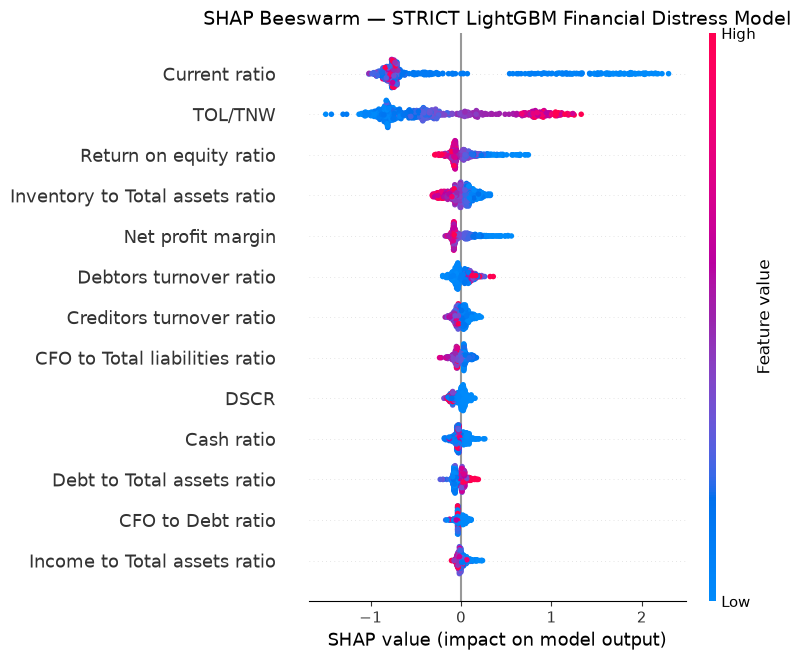

In [66]:
# ============================================================
# SHAP BEESWARM PLOT
# STRICT LIGHTGBM
# ============================================================

import shap
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_shap.columns.tolist(),
    max_display=13,
    show=False
)

plt.title(
    "SHAP Beeswarm — STRICT LightGBM Financial Distress Model",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "STRICT_SHAP_BEESWARM.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

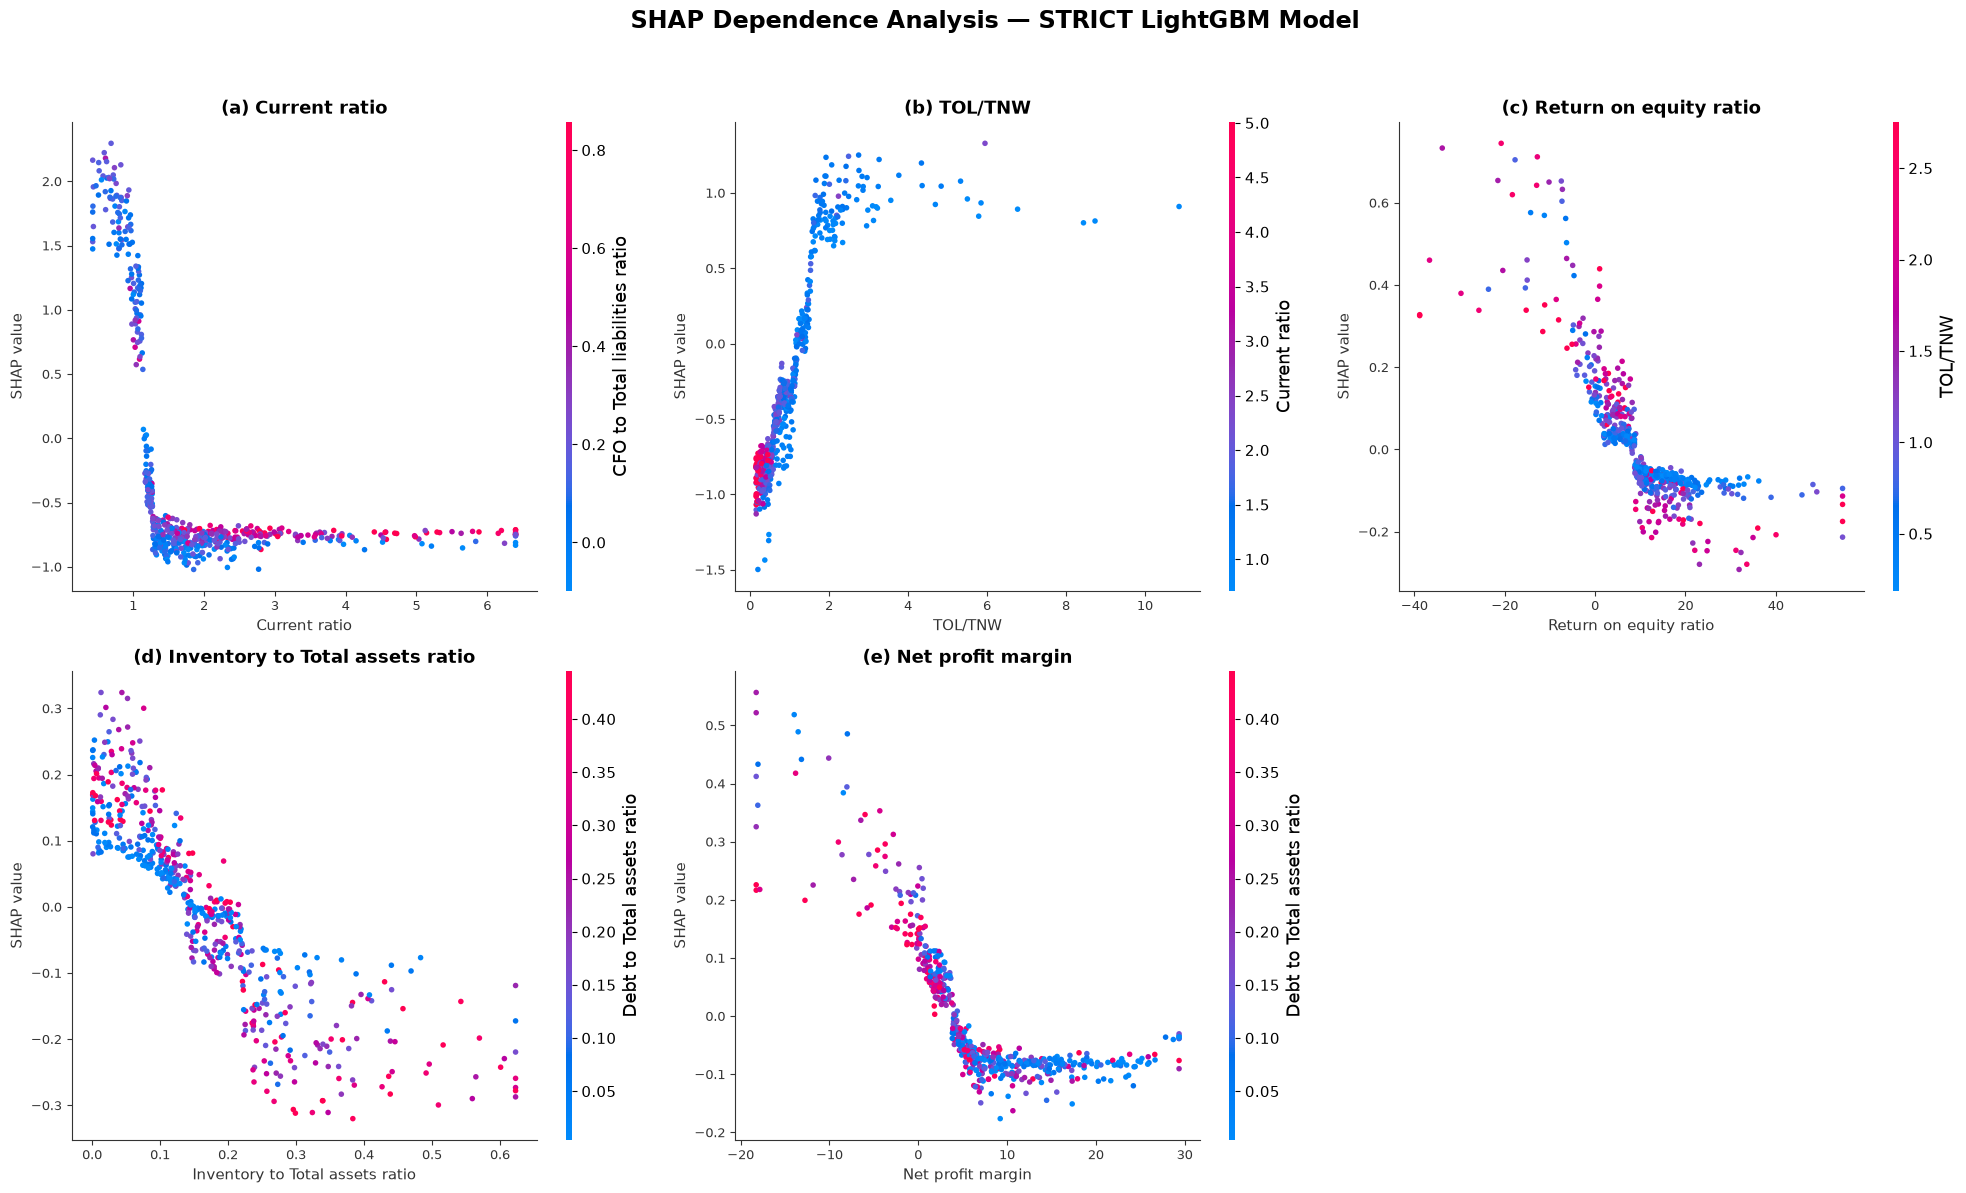

In [67]:
# ============================================================
# SHAP DEPENDENCE PLOTS
# STRICT LIGHTGBM — TOP FIVE PREDICTORS
# ============================================================

import shap
import matplotlib.pyplot as plt
import numpy as np

top_5_features = shap_importance.head(5)["Feature"].tolist()

fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 12)
)

axes = axes.flatten()

for i, feature in enumerate(top_5_features):

    plt.sca(axes[i])

    shap.dependence_plot(
        feature,
        shap_values,
        X_shap,
        interaction_index="auto",
        show=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"({chr(97+i)}) {feature}",
        fontsize=13,
        fontweight="bold"
    )

    axes[i].set_xlabel(feature, fontsize=11)
    axes[i].set_ylabel("SHAP value", fontsize=11)
    axes[i].tick_params(axis="both", labelsize=9)

# Remove unused sixth panel
fig.delaxes(axes[5])

fig.suptitle(
    "SHAP Dependence Analysis — STRICT LightGBM Model",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "STRICT_SHAP_DEPENDENCE_COMBINED.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [71]:
# ============================================================
# DIAGNOSIS — OOT PREDICTION DIMENSIONS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("OOT DATA DIMENSIONS")
print("=" * 90)

print("oot_df:", oot_df.shape)
print("y_oot:", np.asarray(y_oot).shape)
print("y_true:", np.asarray(y_true).shape)

print("\n" + "=" * 90)
print("AVAILABLE PREDICTION DICTIONARIES")
print("=" * 90)

for dict_name in [
    "model_predictions",
    "oot_predictions",
    "OOT_PREDICTIONS"
]:

    if dict_name in globals():

        obj = globals()[dict_name]

        print(f"\n{dict_name}")

        if isinstance(obj, dict):

            for key, value in obj.items():

                arr = np.asarray(value)

                print(
                    key,
                    "| Type:", type(value),
                    "| Shape:", arr.shape
                )

        else:
            print("Not a dictionary:", type(obj))


print("\n" + "=" * 90)
print("CORRECTED STRICT PROBABILITY")
print("=" * 90)

if "strict_probability_corrected" in globals():

    print(
        np.asarray(strict_probability_corrected).shape
    )

OOT DATA DIMENSIONS
oot_df: (551, 29)
y_oot: (551,)
y_true: (551,)

AVAILABLE PREDICTION DICTIONARIES

model_predictions
FULL | Type: <class 'dict'> | Shape: ()
REDUCED | Type: <class 'dict'> | Shape: ()
STRICT | Type: <class 'dict'> | Shape: ()
NAIVE_PERSISTENCE | Type: <class 'dict'> | Shape: ()

oot_predictions
FULL | Type: <class 'numpy.ndarray'> | Shape: (551,)
REDUCED | Type: <class 'numpy.ndarray'> | Shape: (551,)
STRICT | Type: <class 'numpy.ndarray'> | Shape: (551,)

OOT_PREDICTIONS
FULL | Type: <class 'numpy.ndarray'> | Shape: (551,)
REDUCED | Type: <class 'numpy.ndarray'> | Shape: (551,)
STRICT | Type: <class 'numpy.ndarray'> | Shape: (551,)

CORRECTED STRICT PROBABILITY
(551,)


In [73]:
# ============================================================
# REGENERATE CORRECT OOT PROBABILITIES
# FINAL LIGHTGBM MODELS
# ============================================================

import numpy as np
import pandas as pd

probabilities = {}

for model_name in ["FULL", "REDUCED", "STRICT"]:

    # Retrieve final trained model
    model = FINAL_DEVELOPMENT_MODELS[model_name]

    # Retrieve corresponding predictor list
    features = FINAL_CONFIGS[model_name]["features"]

    # Construct OOT feature matrix in original row order
    X_oot_model = oot_df[features].copy()

    # Generate continuous distress probabilities
    probability = model.predict_proba(
        X_oot_model
    )[:, 1]

    probabilities[model_name] = probability

    print("\n", model_name)
    print("Predictors:", len(features))
    print("Observations:", len(probability))
    print("Minimum probability:", probability.min())
    print("Maximum probability:", probability.max())
    print("Mean probability:", probability.mean())
    print("Unique probabilities:", len(np.unique(probability)))

# ------------------------------------------------------------
# VALIDATE ALL THREE MODELS
# ------------------------------------------------------------

for name, values in probabilities.items():

    assert len(values) == len(oot_df) == 551
    assert np.isfinite(values).all()
    assert np.all((values >= 0) & (values <= 1))
    assert len(np.unique(values)) > 2

print("\nAll three continuous OOT probability arrays generated.")


 FULL
Predictors: 21
Observations: 551
Minimum probability: 0.021941965578070044
Maximum probability: 0.8949707698881898
Mean probability: 0.20762075489757434
Unique probabilities: 529

 REDUCED
Predictors: 17
Observations: 551
Minimum probability: 0.032101448549629506
Maximum probability: 0.8565325039015399
Mean probability: 0.21060482941180536
Unique probabilities: 522

 STRICT
Predictors: 13
Observations: 551
Minimum probability: 0.033832084016261886
Maximum probability: 0.8537698491363235
Mean probability: 0.21164172631634584
Unique probabilities: 520

All three continuous OOT probability arrays generated.


In [74]:
# ============================================================
# STRICT MODEL CONSISTENCY CHECK
# ============================================================

print(
    "STRICT probability correlation:",
    np.corrcoef(
        probabilities["STRICT"],
        strict_probability_corrected
    )[0, 1]
)

print(
    "Maximum absolute difference:",
    np.max(
        np.abs(
            probabilities["STRICT"] -
            strict_probability_corrected
        )
    )
)

STRICT probability correlation: 0.9710027224535134
Maximum absolute difference: 0.7624341453889089


In [75]:
y_true = oot_df["Target_Distress"].astype(int).to_numpy()

# Altman Z''
altman_z = pd.to_numeric(
    oot_df["Target_Altman_Zdp"],
    errors="coerce"
).to_numpy()

# Reverse score direction for ranking
altman_risk = -altman_z

In [76]:
from sklearn.metrics import roc_auc_score, average_precision_score

for name, scores in {
    **probabilities,
    "ALTMAN_Z_DOUBLE_PRIME": altman_risk
}.items():

    print(
        name,
        "ROC-AUC:", round(roc_auc_score(y_true, scores), 4),
        "PR-AUC:", round(average_precision_score(y_true, scores), 4)
    )

FULL ROC-AUC: 0.9357 PR-AUC: 0.7733
REDUCED ROC-AUC: 0.9359 PR-AUC: 0.7664
STRICT ROC-AUC: 0.937 PR-AUC: 0.7748
ALTMAN_Z_DOUBLE_PRIME ROC-AUC: 1.0 PR-AUC: 1.0


In [77]:
# ============================================================
# VERIFY ALTMAN Z'' TARGET CONSTRUCTION
# ============================================================

import pandas as pd
import numpy as np

verification_df = pd.DataFrame({

    "Altman_Z": oot_df["Target_Altman_Zdp"].values,

    "Actual_Target": oot_df["Target_Distress"].values

})

verification_df["Altman_Predicted_Distress"] = (
    verification_df["Altman_Z"] < 1.10
).astype(int)

print("=" * 90)
print("ALTMAN Z'' VS ACTUAL DISTRESS TARGET")
print("=" * 90)

print(
    pd.crosstab(
        verification_df["Actual_Target"],
        verification_df["Altman_Predicted_Distress"],
        rownames=["Actual Target"],
        colnames=["Altman Prediction"],
        margins=True
    )
)

agreement = np.mean(
    verification_df["Actual_Target"] ==
    verification_df["Altman_Predicted_Distress"]
)

print("\nExact agreement:", round(agreement, 4))

print(
    "Mismatched observations:",
    (
        verification_df["Actual_Target"] !=
        verification_df["Altman_Predicted_Distress"]
    ).sum()
)

ALTMAN Z'' VS ACTUAL DISTRESS TARGET
Altman Prediction    0   1  All
Actual Target                  
0                  474   0  474
1                    0  77   77
All                474  77  551

Exact agreement: 1.0
Mismatched observations: 0


In [81]:
# ============================================================
# DIAGNOSTIC — IDENTIFY ORIGINAL ACCOUNTING AND ALTMAN VARIABLES
# ============================================================

print("=" * 100)
print("MODEL DATASET COLUMNS")
print("=" * 100)

for i, col in enumerate(model_df_winsorized.columns):

    print(
        i + 1,
        "|",
        col,
        "|",
        model_df_winsorized[col].dtype
    )

print("\n" + "=" * 100)
print("OOT DATASET COLUMNS")
print("=" * 100)

for i, col in enumerate(oot_df.columns):

    print(i + 1, "|", col)

MODEL DATASET COLUMNS
1 | Company Name | object
2 | Predictor_Year | int64
3 | Predictor_Altman_Zdp | float64
4 | Predictor_Distress | int64
5 | Target_Year | int64
6 | Target_Altman_Zdp | float64
7 | Target_Distress | int64
8 | Year_Difference | int64
9 | Return on equity ratio | float64
10 | Net profit margin | float64
11 | PBDITA % of total income | float64
12 | PBT % of total income | float64
13 | PAT % of total income | float64
14 | Debt to equity ratio | float64
15 | DSCR | float64
16 | Creditors turnover ratio | float64
17 | Debtors turnover ratio | float64
18 | Inventory to Total assets ratio | float64
19 | Current asset to Total assets ratio | float64
20 | CFO to Total assets ratio | float64
21 | CFO to Total liabilities ratio | float64
22 | CFO to Debt ratio | float64
23 | Income to Total assets ratio | float64
24 | Cash ratio | float64
25 | Debt to Total assets ratio | float64
26 | Net worth to Total assets ratio | float64
27 | Quick ratio | float64
28 | Current ratio | floa

In [83]:
# ============================================================
# STRICT PREDICTORS VS LAGGED ALTMAN Z''
# DEVELOPMENT PERIOD ONLY
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr

development_corr = model_df_winsorized[
    model_df_winsorized["Predictor_Year"].between(2016, 2022)
].copy()

STRICT_FEATURES_CURRENT = FINAL_CONFIGS["STRICT"]["features"]

Z_COLUMN = "Predictor_Altman_Zdp"

correlation_results = []

for feature in STRICT_FEATURES_CURRENT:

    temp = development_corr[
        [feature, Z_COLUMN]
    ].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    pearson_r, pearson_p = pearsonr(
        temp[feature],
        temp[Z_COLUMN]
    )

    spearman_r, spearman_p = spearmanr(
        temp[feature],
        temp[Z_COLUMN]
    )

    correlation_results.append({

        "STRICT_Predictor": feature,

        "Observations": len(temp),

        "Pearson_r": pearson_r,

        "Pearson_p": pearson_p,

        "Spearman_r": spearman_r,

        "Spearman_p": spearman_p,

        "Absolute_Spearman": abs(spearman_r)

    })

z_correlation_df = pd.DataFrame(
    correlation_results
).sort_values(
    "Absolute_Spearman",
    ascending=False
)

print("=" * 100)
print("STRICT PREDICTOR CORRELATION WITH LAGGED ALTMAN Z''")
print("=" * 100)

display(z_correlation_df.round(4))

STRICT PREDICTOR CORRELATION WITH LAGGED ALTMAN Z''


,STRICT_Predictor,Observations,Pearson_r,Pearson_p,Spearman_r,Spearman_p,Absolute_Spearman
11,Current ratio,3857,0.8376,0.0000,0.8618,0.0000,0.8618
12,TOL/TNW,3857,-0.5070,0.0000,-0.8045,0.0000,0.8045
10,Debt to Total assets ratio,3857,-0.5863,0.0000,-0.6491,0.0000,0.6491
2,DSCR,3857,0.3287,0.0000,0.6053,0.0000,0.6053
1,Net profit margin,3857,0.4884,0.0000,0.5590,0.0000,0.5590
9,Cash ratio,3857,0.4999,0.0000,0.4792,0.0000,0.4792
7,CFO to Debt ratio,3857,0.2645,0.0000,0.4518,0.0000,0.4518
6,CFO to Total liabilities ratio,3857,0.4629,0.0000,0.4083,0.0000,0.4083
0,Return on equity ratio,3857,0.3322,0.0000,0.3758,0.0000,0.3758
3,Creditors turnover ratio,3857,0.1356,0.0000,0.1762,0.0000,0.1762


In [84]:
# ============================================================
# PRIMARY EMPIRICAL PROXY EXCLUSION
# Threshold: Absolute Spearman correlation >= 0.70
# ============================================================

PROXY_THRESHOLD = 0.70

# Identify high-correlation proxies
Z2_PROXY_FEATURES = z_correlation_df.loc[
    z_correlation_df["Absolute_Spearman"] >= PROXY_THRESHOLD,
    "STRICT_Predictor"
].tolist()

# Remove only these predictors
PROXY_FREE_STRICT_FEATURES = [
    feature
    for feature in STRICT_FEATURES_CURRENT
    if feature not in Z2_PROXY_FEATURES
]

print("=" * 100)
print("PRIMARY PROXY EXCLUSION")
print("=" * 100)

print("\nOriginal STRICT predictors:", len(STRICT_FEATURES_CURRENT))

print("\nExcluded predictors:")
print(Z2_PROXY_FEATURES)

print("\nRemaining predictors:")
print(PROXY_FREE_STRICT_FEATURES)

print("\nOriginal predictor count:", len(STRICT_FEATURES_CURRENT))
print("Proxy-free predictor count:", len(PROXY_FREE_STRICT_FEATURES))
print(
    "Percentage reduction:",
    round(
        (1 - len(PROXY_FREE_STRICT_FEATURES) /
         len(STRICT_FEATURES_CURRENT)) * 100,
        2
    ),
    "%"
)

PRIMARY PROXY EXCLUSION

Original STRICT predictors: 13

Excluded predictors:
['Current ratio', 'TOL/TNW']

Remaining predictors:
['Return on equity ratio', 'Net profit margin', 'DSCR', 'Creditors turnover ratio', 'Debtors turnover ratio', 'Inventory to Total assets ratio', 'CFO to Total liabilities ratio', 'CFO to Debt ratio', 'Income to Total assets ratio', 'Cash ratio', 'Debt to Total assets ratio']

Original predictor count: 13
Proxy-free predictor count: 11
Percentage reduction: 15.38 %


In [85]:
# ============================================================
# TRAIN PROXY-FREE STRICT LIGHTGBM
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. DEVELOPMENT AND OOT DATA
# ------------------------------------------------------------

development_proxyfree = model_df_winsorized[
    model_df_winsorized["Predictor_Year"].between(2016, 2022)
].copy()

oot_proxyfree = model_df_winsorized[
    model_df_winsorized["Predictor_Year"] == 2025
].copy()

FEATURES_PROXYFREE = PROXY_FREE_STRICT_FEATURES

X_dev_proxyfree = development_proxyfree[
    FEATURES_PROXYFREE
].copy()

y_dev_proxyfree = development_proxyfree[
    "Target_Distress"
].astype(int)

X_oot_proxyfree = oot_proxyfree[
    FEATURES_PROXYFREE
].copy()

y_oot_proxyfree = oot_proxyfree[
    "Target_Distress"
].astype(int)

# ------------------------------------------------------------
# 2. CHECK DATA QUALITY
# ------------------------------------------------------------

print("Development observations:", len(X_dev_proxyfree))
print("OOT observations:", len(X_oot_proxyfree))
print("Proxy-free predictors:", len(FEATURES_PROXYFREE))

print("\nMissing values in development:")
print(X_dev_proxyfree.isna().sum().sum())

print("\nMissing values in OOT:")
print(X_oot_proxyfree.isna().sum().sum())

assert X_dev_proxyfree.isna().sum().sum() == 0
assert X_oot_proxyfree.isna().sum().sum() == 0

assert len(X_oot_proxyfree) == 551

# ------------------------------------------------------------
# 3. REUSE ORIGINAL STRICT MODEL PARAMETERS
# ------------------------------------------------------------

strict_parameters = FINAL_DEVELOPMENT_MODELS[
    "STRICT"
].get_params().copy()

# Preserve original class weighting and other settings.
strict_parameters["n_estimators"] = 70
strict_parameters["random_state"] = 42
strict_parameters["verbosity"] = -1
strict_parameters["n_jobs"] = -1

PROXY_FREE_STRICT_MODEL = lgb.LGBMClassifier(
    **strict_parameters
)

# ------------------------------------------------------------
# 4. TRAIN MODEL
# ------------------------------------------------------------

PROXY_FREE_STRICT_MODEL.fit(
    X_dev_proxyfree,
    y_dev_proxyfree
)

# ------------------------------------------------------------
# 5. GENERATE OOT PROBABILITIES
# ------------------------------------------------------------

PROXY_FREE_STRICT_PROBABILITY = (
    PROXY_FREE_STRICT_MODEL.predict_proba(
        X_oot_proxyfree
    )[:, 1]
)

# ------------------------------------------------------------
# 6. EVALUATE OOT PERFORMANCE
# ------------------------------------------------------------

threshold = 0.50

predicted_labels = (
    PROXY_FREE_STRICT_PROBABILITY >= threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_oot_proxyfree,
    predicted_labels,
    labels=[0, 1]
).ravel()

proxyfree_results = {

    "Model": "PROXY_FREE_STRICT",

    "Observations": len(y_oot_proxyfree),

    "Predictors": len(FEATURES_PROXYFREE),

    "ROC_AUC": roc_auc_score(
        y_oot_proxyfree,
        PROXY_FREE_STRICT_PROBABILITY
    ),

    "PR_AUC": average_precision_score(
        y_oot_proxyfree,
        PROXY_FREE_STRICT_PROBABILITY
    ),

    "Brier_Score": brier_score_loss(
        y_oot_proxyfree,
        PROXY_FREE_STRICT_PROBABILITY
    ),

    "Log_Loss": log_loss(
        y_oot_proxyfree,
        PROXY_FREE_STRICT_PROBABILITY
    ),

    "Accuracy": accuracy_score(
        y_oot_proxyfree,
        predicted_labels
    ),

    "Sensitivity": recall_score(
        y_oot_proxyfree,
        predicted_labels,
        zero_division=0
    ),

    "Specificity": tn / (tn + fp),

    "Precision": precision_score(
        y_oot_proxyfree,
        predicted_labels,
        zero_division=0
    ),

    "F1": f1_score(
        y_oot_proxyfree,
        predicted_labels,
        zero_division=0
    ),

    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp

}

proxyfree_oot_results = pd.DataFrame(
    [proxyfree_results]
)

print("\n" + "=" * 100)
print("PROXY-FREE STRICT — OOT PERFORMANCE")
print("=" * 100)

display(proxyfree_oot_results.round(4))

Development observations: 3857
OOT observations: 551
Proxy-free predictors: 11

Missing values in development:
0

Missing values in OOT:
0

PROXY-FREE STRICT — OOT PERFORMANCE


,Model,Observations,Predictors,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,Accuracy,Sensitivity,Specificity,Precision,F1,TN,FP,FN,TP
0,PROXY_FREE_STRICT,551,11,0.8971,0.6339,0.1077,0.3465,0.8439,0.7922,0.8523,0.4656,0.5865,404,70,16,61


In [86]:
# ============================================================
# LAGGED ALTMAN VS PROXY-FREE LIGHTGBM
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

# ------------------------------------------------------------
# 1. ALIGN DEVELOPMENT AND OOT DATA
# ------------------------------------------------------------

development_data = model_df_winsorized[
    model_df_winsorized["Predictor_Year"].between(2016, 2022)
].copy()

oot_data = model_df_winsorized[
    model_df_winsorized["Predictor_Year"] == 2025
].copy()

# Ensure OOT company order is consistent
assert oot_data["Company Name"].reset_index(drop=True).equals(
    oot_proxyfree["Company Name"].reset_index(drop=True)
)

y_dev = development_data["Target_Distress"].astype(int)

y_oot_final = oot_data["Target_Distress"].astype(int).to_numpy()

# ------------------------------------------------------------
# 2. MODEL A — LAGGED ALTMAN Z''
# ------------------------------------------------------------

lagged_altman_risk = (
    -oot_data["Predictor_Altman_Zdp"].to_numpy()
)

# ------------------------------------------------------------
# 3. MODEL B — PROXY-FREE STRICT
# ------------------------------------------------------------

proxyfree_probability = (
    PROXY_FREE_STRICT_MODEL.predict_proba(
        oot_data[PROXY_FREE_STRICT_FEATURES]
    )[:, 1]
)

# ------------------------------------------------------------
# 4. MODEL C — LAGGED Z'' + PROXY-FREE PREDICTORS
# ------------------------------------------------------------

COMBINED_FEATURES = (
    ["Predictor_Altman_Zdp"] +
    PROXY_FREE_STRICT_FEATURES
)

X_combined_dev = development_data[
    COMBINED_FEATURES
].copy()

X_combined_oot = oot_data[
    COMBINED_FEATURES
].copy()

combined_parameters = (
    FINAL_DEVELOPMENT_MODELS["STRICT"].get_params().copy()
)

combined_parameters["n_estimators"] = 70
combined_parameters["random_state"] = 42
combined_parameters["verbosity"] = -1
combined_parameters["n_jobs"] = -1

COMBINED_PROXYFREE_MODEL = lgb.LGBMClassifier(
    **combined_parameters
)

COMBINED_PROXYFREE_MODEL.fit(
    X_combined_dev,
    y_dev
)

combined_probability = (
    COMBINED_PROXYFREE_MODEL.predict_proba(
        X_combined_oot
    )[:, 1]
)

# ------------------------------------------------------------
# 5. CALCULATE PERFORMANCE
# ------------------------------------------------------------

def calculate_ranking_metrics(y, score):

    return {
        "ROC_AUC": roc_auc_score(y, score),
        "PR_AUC": average_precision_score(y, score)
    }


def calculate_probability_metrics(y, probability):

    return {
        "Brier_Score": brier_score_loss(y, probability),
        "Log_Loss": log_loss(y, probability)
    }


comparison_results = []

# Model A
comparison_results.append({
    "Model": "LAGGED_ALTMAN_Z2",
    "Predictors": 1,
    **calculate_ranking_metrics(
        y_oot_final,
        lagged_altman_risk
    ),
    "Brier_Score": np.nan,
    "Log_Loss": np.nan
})

# Model B
comparison_results.append({
    "Model": "PROXY_FREE_STRICT",
    "Predictors": len(PROXY_FREE_STRICT_FEATURES),
    **calculate_ranking_metrics(
        y_oot_final,
        proxyfree_probability
    ),
    **calculate_probability_metrics(
        y_oot_final,
        proxyfree_probability
    )
})

# Model C
comparison_results.append({
    "Model": "COMBINED_Z2_PLUS_PROXY_FREE",
    "Predictors": len(COMBINED_FEATURES),
    **calculate_ranking_metrics(
        y_oot_final,
        combined_probability
    ),
    **calculate_probability_metrics(
        y_oot_final,
        combined_probability
    )
})

incremental_results = pd.DataFrame(
    comparison_results
)

print("=" * 110)
print("INCREMENTAL PREDICTIVE VALUE — OOT RESULTS")
print("=" * 110)

display(incremental_results.round(4))

print("\nOOT observations:", len(y_oot_final))
print("OOT distress cases:", int(y_oot_final.sum()))
print("OOT distress prevalence:", round(y_oot_final.mean(), 4))

INCREMENTAL PREDICTIVE VALUE — OOT RESULTS


,Model,Predictors,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
0,LAGGED_ALTMAN_Z2,1,0.9423,0.7978,NaN,NaN
1,PROXY_FREE_STRICT,11,0.8971,0.6339,0.1077,0.3465
2,COMBINED_Z2_PLUS_PROXY_FREE,12,0.9424,0.7906,0.0675,0.2372



OOT observations: 551
OOT distress cases: 77
OOT distress prevalence: 0.1397


In [87]:
# ============================================================
# PAIRED COMPANY-LEVEL BOOTSTRAP
# INCREMENTAL PREDICTIVE PERFORMANCE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. PREPARE ALIGNED OOT DATA
# ------------------------------------------------------------

y_boot = np.asarray(y_oot_final).astype(int)

score_dict = {
    "LAGGED_ALTMAN_Z2": np.asarray(
        lagged_altman_risk
    ),

    "PROXY_FREE_STRICT": np.asarray(
        proxyfree_probability
    ),

    "COMBINED_MODEL": np.asarray(
        combined_probability
    )
}

# Verify dimensions
for name, score in score_dict.items():

    assert len(score) == len(y_boot), (
        f"Dimension mismatch in {name}"
    )

    assert np.isfinite(score).all(), (
        f"Non-finite scores in {name}"
    )

assert len(y_boot) == 551
assert y_boot.sum() == 77

print("OOT observations:", len(y_boot))
print("Distress cases:", y_boot.sum())
print("Non-distress cases:", (y_boot == 0).sum())

# ------------------------------------------------------------
# 2. DEFINE PAIRED COMPARISONS
# ------------------------------------------------------------

comparisons = [

    ("PROXY_FREE_STRICT", "LAGGED_ALTMAN_Z2"),

    ("COMBINED_MODEL", "LAGGED_ALTMAN_Z2"),

    ("COMBINED_MODEL", "PROXY_FREE_STRICT")

]

# ------------------------------------------------------------
# 3. BOOTSTRAP SETTINGS
# ------------------------------------------------------------

N_BOOTSTRAP = 2000

rng = np.random.default_rng(42)

n = len(y_boot)

bootstrap_results = []

# ------------------------------------------------------------
# 4. PAIRED BOOTSTRAP
# ------------------------------------------------------------

for model_a, model_b in comparisons:

    auc_differences = []
    ap_differences = []

    for iteration in range(N_BOOTSTRAP):

        # Same sampled companies for both models
        indices = rng.integers(
            0,
            n,
            size=n
        )

        y_sample = y_boot[indices]

        # Skip samples containing only one outcome class
        if len(np.unique(y_sample)) < 2:
            continue

        score_a = score_dict[model_a][indices]
        score_b = score_dict[model_b][indices]

        # ROC-AUC difference
        auc_a = roc_auc_score(
            y_sample,
            score_a
        )

        auc_b = roc_auc_score(
            y_sample,
            score_b
        )

        auc_differences.append(
            auc_a - auc_b
        )

        # PR-AUC difference
        ap_a = average_precision_score(
            y_sample,
            score_a
        )

        ap_b = average_precision_score(
            y_sample,
            score_b
        )

        ap_differences.append(
            ap_a - ap_b
        )

    # --------------------------------------------------------
    # 5. CONFIDENCE INTERVALS
    # --------------------------------------------------------

    for metric, differences in [

        ("ROC_AUC", auc_differences),

        ("PR_AUC", ap_differences)

    ]:

        differences = np.asarray(differences)

        lower = np.percentile(
            differences,
            2.5
        )

        upper = np.percentile(
            differences,
            97.5
        )

        mean_difference = np.mean(
            differences
        )

        bootstrap_results.append({

            "Comparison": f"{model_a} - {model_b}",

            "Metric": metric,

            "Bootstrap_Replications": len(differences),

            "Mean_Difference": mean_difference,

            "CI_95_Lower": lower,

            "CI_95_Upper": upper,

            "Significant_At_5_Percent": (
                lower > 0 or upper < 0
            )

        })

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

incremental_bootstrap_df = pd.DataFrame(
    bootstrap_results
)

print("\n" + "=" * 110)
print("PAIRED BOOTSTRAP — INCREMENTAL PREDICTIVE PERFORMANCE")
print("=" * 110)

display(
    incremental_bootstrap_df.round(5)
)

OOT observations: 551
Distress cases: 77
Non-distress cases: 474

PAIRED BOOTSTRAP — INCREMENTAL PREDICTIVE PERFORMANCE


,Comparison,Metric,Bootstrap_Replications,Mean_Difference,CI_95_Lower,CI_95_Upper,Significant_At_5_Percent
0,PROXY_FREE_STRICT - LAGGED_ALTMAN_Z2,ROC_AUC,2000,-0.04499,-0.07798,-0.01491,True
1,PROXY_FREE_STRICT - LAGGED_ALTMAN_Z2,PR_AUC,2000,-0.15891,-0.25928,-0.06245,True
2,COMBINED_MODEL - LAGGED_ALTMAN_Z2,ROC_AUC,2000,0.00010,-0.01025,0.01088,False
3,COMBINED_MODEL - LAGGED_ALTMAN_Z2,PR_AUC,2000,-0.00651,-0.03919,0.02467,False
4,COMBINED_MODEL - PROXY_FREE_STRICT,ROC_AUC,2000,0.04583,0.02045,0.07517,True
5,COMBINED_MODEL - PROXY_FREE_STRICT,PR_AUC,2000,0.15322,0.07401,0.23210,True


In [88]:
# ============================================================
# PROXY EXCLUSION THRESHOLD SENSITIVITY
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

# ------------------------------------------------------------
# 1. DATA PREPARATION
# ------------------------------------------------------------

development_data = model_df_winsorized[
    model_df_winsorized["Predictor_Year"].between(2016, 2022)
].copy()

oot_data = model_df_winsorized[
    model_df_winsorized["Predictor_Year"] == 2025
].copy()

y_dev = development_data["Target_Distress"].astype(int)

y_oot_sensitivity = oot_data[
    "Target_Distress"
].astype(int).to_numpy()

# ------------------------------------------------------------
# 2. DEFINE THRESHOLDS
# ------------------------------------------------------------

THRESHOLDS = [0.50, 0.60, 0.70, 0.80]

sensitivity_models = {}

sensitivity_results = []

# ------------------------------------------------------------
# 3. REUSE ORIGINAL STRICT PARAMETERS
# ------------------------------------------------------------

base_parameters = (
    FINAL_DEVELOPMENT_MODELS["STRICT"].get_params().copy()
)

base_parameters["n_estimators"] = 70
base_parameters["random_state"] = 42
base_parameters["verbosity"] = -1
base_parameters["n_jobs"] = -1

# ------------------------------------------------------------
# 4. TRAIN MODELS
# ------------------------------------------------------------

for threshold in THRESHOLDS:

    excluded_features = z_correlation_df.loc[
        z_correlation_df["Absolute_Spearman"] >= threshold,
        "STRICT_Predictor"
    ].tolist()

    retained_features = [
        feature
        for feature in STRICT_FEATURES_CURRENT
        if feature not in excluded_features
    ]

    X_train = development_data[
        retained_features
    ].copy()

    X_oot = oot_data[
        retained_features
    ].copy()

    if len(retained_features) == 0:
        print("No predictors retained for threshold:", threshold)
        continue

    model = lgb.LGBMClassifier(
        **base_parameters
    )

    model.fit(
        X_train,
        y_dev
    )

    probability = model.predict_proba(
        X_oot
    )[:, 1]

    sensitivity_models[threshold] = {

        "model": model,

        "features": retained_features,

        "excluded": excluded_features,

        "probability": probability

    }

    sensitivity_results.append({

        "Threshold": threshold,

        "Excluded_Count": len(excluded_features),

        "Retained_Count": len(retained_features),

        "Excluded_Features": ", ".join(excluded_features),

        "ROC_AUC": roc_auc_score(
            y_oot_sensitivity,
            probability
        ),

        "PR_AUC": average_precision_score(
            y_oot_sensitivity,
            probability
        ),

        "Brier_Score": brier_score_loss(
            y_oot_sensitivity,
            probability
        ),

        "Log_Loss": log_loss(
            y_oot_sensitivity,
            probability
        )

    })

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

threshold_sensitivity_results = pd.DataFrame(
    sensitivity_results
)

print("=" * 120)
print("PROXY EXCLUSION THRESHOLD SENSITIVITY — OOT")
print("=" * 120)

display(
    threshold_sensitivity_results.round(4)
)

PROXY EXCLUSION THRESHOLD SENSITIVITY — OOT


,Threshold,Excluded_Count,Retained_Count,Excluded_Features,ROC_AUC,PR_AUC,Brier_Score,Log_Loss
0,0.5,5,8,"Current ratio, TOL/TNW, Debt to Total assets r...",0.8754,0.5677,0.1288,0.4045
1,0.6,4,9,"Current ratio, TOL/TNW, Debt to Total assets r...",0.8847,0.5908,0.1201,0.3811
2,0.7,2,11,"Current ratio, TOL/TNW",0.8971,0.6339,0.1077,0.3465
3,0.8,2,11,"Current ratio, TOL/TNW",0.8971,0.6339,0.1077,0.3465


In [89]:
# ============================================================
# PROXY-FREE STRICT SHAP ANALYSIS
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. SELECT TRAINED PROXY-FREE MODEL
# ------------------------------------------------------------

proxyfree_model = PROXY_FREE_STRICT_MODEL

proxyfree_features = PROXY_FREE_STRICT_FEATURES

# Use all 551 OOT observations
X_shap_proxyfree = oot_data[
    proxyfree_features
].copy().reset_index(drop=True)

# ------------------------------------------------------------
# 2. CREATE TREE EXPLAINER
# ------------------------------------------------------------

proxyfree_explainer = shap.TreeExplainer(
    proxyfree_model
)

# ------------------------------------------------------------
# 3. CALCULATE SHAP VALUES
# ------------------------------------------------------------

proxyfree_shap_raw = proxyfree_explainer.shap_values(
    X_shap_proxyfree
)

# Handle binary classification output formats
if isinstance(proxyfree_shap_raw, list):

    proxyfree_shap_values = proxyfree_shap_raw[1]

else:

    proxyfree_shap_values = np.asarray(
        proxyfree_shap_raw
    )

    if proxyfree_shap_values.ndim == 3:

        proxyfree_shap_values = (
            proxyfree_shap_values[:, :, 1]
        )

# ------------------------------------------------------------
# 4. VERIFY DIMENSIONS
# ------------------------------------------------------------

print("SHAP dimensions:", proxyfree_shap_values.shape)

print("Expected dimensions:", (
    len(X_shap_proxyfree),
    len(proxyfree_features)
))

print(
    "All SHAP values finite:",
    np.isfinite(proxyfree_shap_values).all()
)

assert proxyfree_shap_values.shape == (
    len(X_shap_proxyfree),
    len(proxyfree_features)
)

assert np.isfinite(proxyfree_shap_values).all()

# ------------------------------------------------------------
# 5. GLOBAL SHAP IMPORTANCE
# ------------------------------------------------------------

proxyfree_shap_importance = pd.DataFrame({

    "Feature": proxyfree_features,

    "Mean_Absolute_SHAP": np.mean(
        np.abs(proxyfree_shap_values),
        axis=0
    ),

    "Mean_SHAP": np.mean(
        proxyfree_shap_values,
        axis=0
    )

}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

proxyfree_shap_importance.insert(
    0,
    "Rank",
    range(1, len(proxyfree_shap_importance) + 1)
)

print("\n" + "=" * 100)
print("PROXY-FREE STRICT — GLOBAL SHAP IMPORTANCE")
print("=" * 100)

display(
    proxyfree_shap_importance.round(6)
)

SHAP dimensions: (551, 11)
Expected dimensions: (551, 11)
All SHAP values finite: True

PROXY-FREE STRICT — GLOBAL SHAP IMPORTANCE


,Rank,Feature,Mean_Absolute_SHAP,Mean_SHAP
0,1,Debt to Total assets ratio,0.592634,-0.220717
1,2,Net profit margin,0.410073,-0.020241
2,3,Creditors turnover ratio,0.293800,0.049770
3,4,Debtors turnover ratio,0.269859,0.036578
4,5,Cash ratio,0.264892,-0.078036
5,6,Inventory to Total assets ratio,0.217804,-0.000314
6,7,DSCR,0.153101,-0.040612
7,8,CFO to Total liabilities ratio,0.148132,-0.015849
8,9,Return on equity ratio,0.073131,-0.005385
9,10,Income to Total assets ratio,0.048180,0.006116


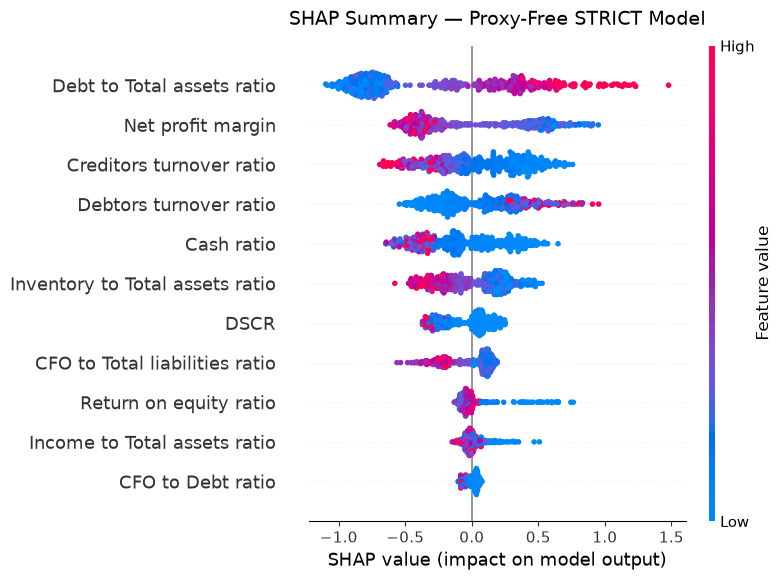

In [90]:
# ============================================================
# SHAP BEESWARM PLOT
# ============================================================

plt.figure(figsize=(11, 8))

shap.summary_plot(
    proxyfree_shap_values,
    X_shap_proxyfree,
    feature_names=proxyfree_features,
    max_display=11,
    show=False
)

plt.title(
    "SHAP Summary — Proxy-Free STRICT Model",
    fontsize=14,
    pad=15
)

plt.tight_layout()

plt.show()

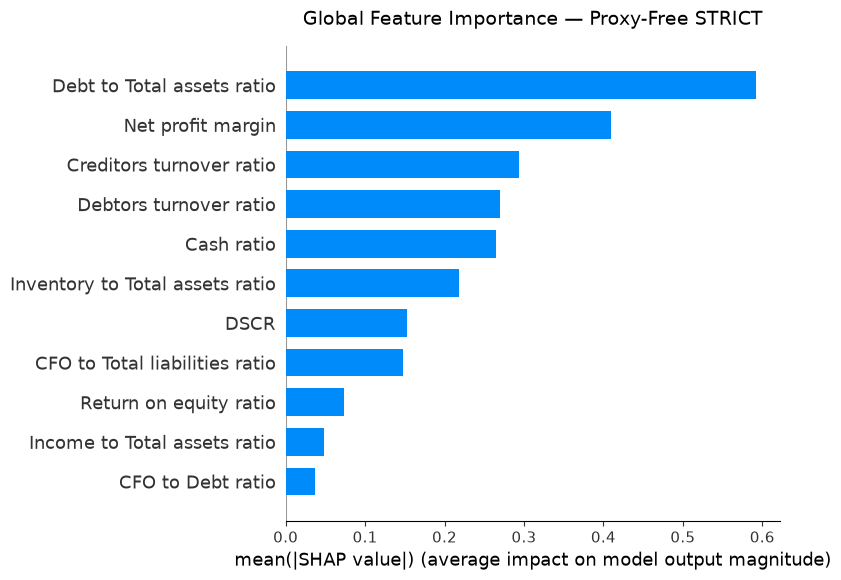

In [91]:
# ============================================================
# GLOBAL SHAP IMPORTANCE BAR CHART
# ============================================================

plt.figure(figsize=(10, 7))

shap.summary_plot(
    proxyfree_shap_values,
    X_shap_proxyfree,
    plot_type="bar",
    feature_names=proxyfree_features,
    max_display=11,
    show=False
)

plt.title(
    "Global Feature Importance — Proxy-Free STRICT",
    fontsize=14,
    pad=15
)

plt.tight_layout()

plt.show()

Top five proxy-free predictors:
1 Debt to Total assets ratio
2 Net profit margin
3 Creditors turnover ratio
4 Debtors turnover ratio
5 Cash ratio


<Figure size 800x600 with 0 Axes>

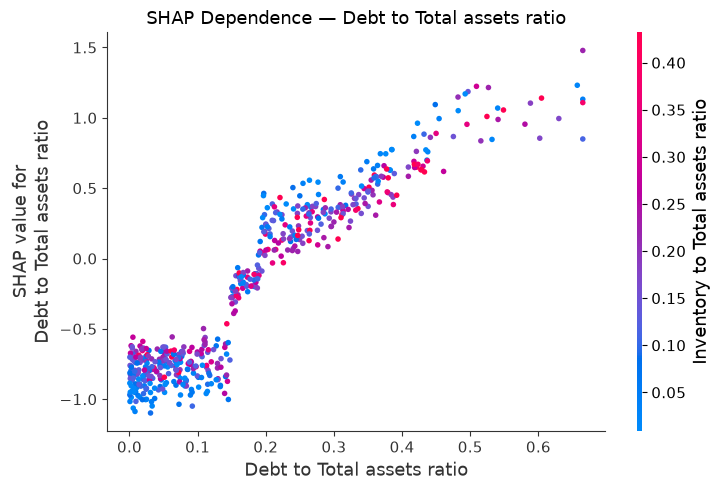

<Figure size 800x600 with 0 Axes>

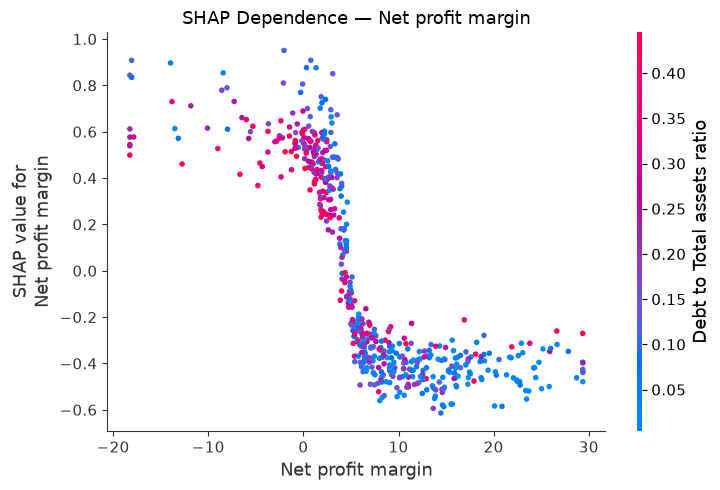

<Figure size 800x600 with 0 Axes>

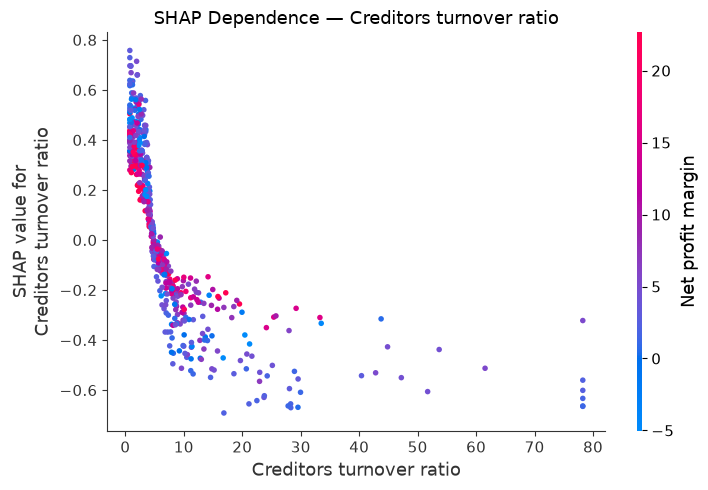

<Figure size 800x600 with 0 Axes>

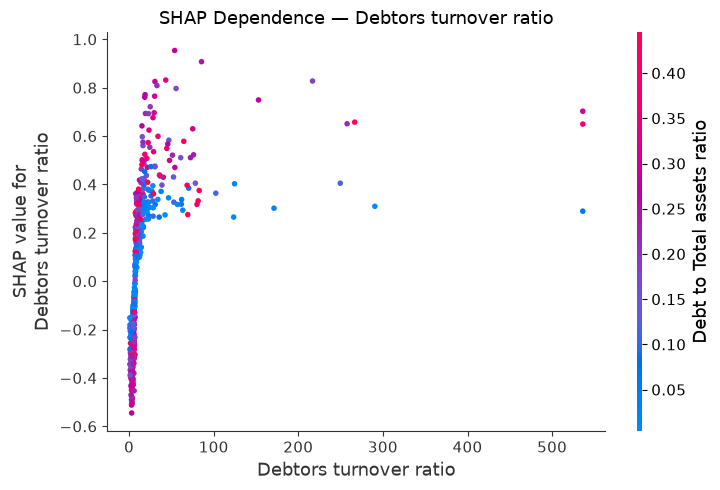

<Figure size 800x600 with 0 Axes>

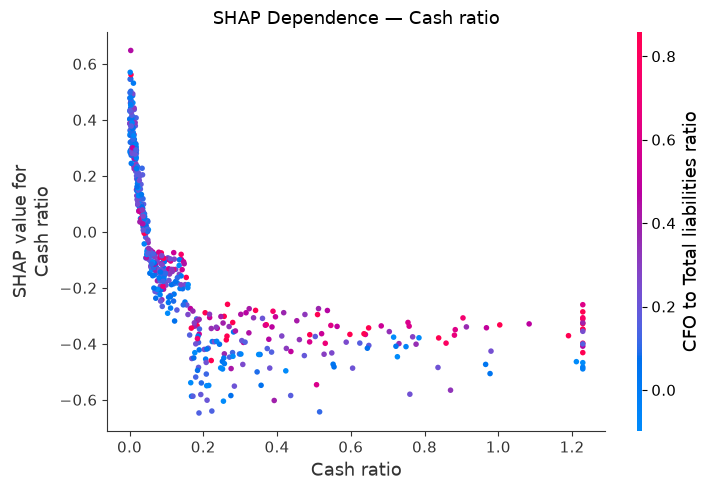

In [92]:
# ============================================================
# TOP FIVE SHAP DEPENDENCE PLOTS
# ============================================================

top_five_proxyfree = (
    proxyfree_shap_importance
    .head(5)["Feature"]
    .tolist()
)

print("Top five proxy-free predictors:")

for rank, feature in enumerate(
    top_five_proxyfree,
    start=1
):

    print(rank, feature)

# Generate separate dependence plots
for feature in top_five_proxyfree:

    plt.figure(figsize=(8, 6))

    shap.dependence_plot(
        feature,
        proxyfree_shap_values,
        X_shap_proxyfree,
        interaction_index="auto",
        show=False
    )

    plt.title(
        f"SHAP Dependence — {feature}",
        fontsize=13
    )

    plt.tight_layout()

    plt.show()

In [93]:
# ============================================================
# ORIGINAL STRICT VS PROXY-FREE SHAP COMPARISON
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PREPARE IDENTICAL OOT OBSERVATIONS
# ------------------------------------------------------------

X_original = oot_data[
    FINAL_CONFIGS["STRICT"]["features"]
].copy().reset_index(drop=True)

X_proxyfree = oot_data[
    PROXY_FREE_STRICT_FEATURES
].copy().reset_index(drop=True)

assert len(X_original) == len(X_proxyfree) == 551

# ------------------------------------------------------------
# 2. ORIGINAL STRICT SHAP
# ------------------------------------------------------------

original_model = FINAL_DEVELOPMENT_MODELS["STRICT"]

original_explainer = shap.TreeExplainer(
    original_model
)

original_shap_raw = original_explainer.shap_values(
    X_original
)

# Handle different SHAP output formats
if isinstance(original_shap_raw, list):

    original_shap_values_comparison = original_shap_raw[1]

else:

    original_shap_values_comparison = np.asarray(
        original_shap_raw
    )

    if original_shap_values_comparison.ndim == 3:

        original_shap_values_comparison = (
            original_shap_values_comparison[:, :, 1]
        )

# ------------------------------------------------------------
# 3. PROXY-FREE STRICT SHAP
# ------------------------------------------------------------

proxyfree_model = PROXY_FREE_STRICT_MODEL

proxyfree_explainer = shap.TreeExplainer(
    proxyfree_model
)

proxyfree_shap_raw = proxyfree_explainer.shap_values(
    X_proxyfree
)

if isinstance(proxyfree_shap_raw, list):

    proxyfree_shap_values_comparison = proxyfree_shap_raw[1]

else:

    proxyfree_shap_values_comparison = np.asarray(
        proxyfree_shap_raw
    )

    if proxyfree_shap_values_comparison.ndim == 3:

        proxyfree_shap_values_comparison = (
            proxyfree_shap_values_comparison[:, :, 1]
        )

# ------------------------------------------------------------
# 4. VERIFY DIMENSIONS
# ------------------------------------------------------------

assert original_shap_values_comparison.shape == (
    551,
    len(FINAL_CONFIGS["STRICT"]["features"])
)

assert proxyfree_shap_values_comparison.shape == (
    551,
    len(PROXY_FREE_STRICT_FEATURES)
)

# ------------------------------------------------------------
# 5. CALCULATE GLOBAL IMPORTANCE
# ------------------------------------------------------------

original_importance_comparison = pd.DataFrame({

    "Feature": FINAL_CONFIGS["STRICT"]["features"],

    "Original_Mean_Abs_SHAP": np.mean(
        np.abs(original_shap_values_comparison),
        axis=0
    )

})

proxyfree_importance_comparison = pd.DataFrame({

    "Feature": PROXY_FREE_STRICT_FEATURES,

    "ProxyFree_Mean_Abs_SHAP": np.mean(
        np.abs(proxyfree_shap_values_comparison),
        axis=0
    )

})

# ------------------------------------------------------------
# 6. MERGE COMMON FEATURES
# ------------------------------------------------------------

shap_comparison_df = original_importance_comparison.merge(
    proxyfree_importance_comparison,
    on="Feature",
    how="outer"
)

shap_comparison_df["Original_Relative_Importance"] = (
    shap_comparison_df["Original_Mean_Abs_SHAP"] /
    shap_comparison_df["Original_Mean_Abs_SHAP"].sum()
)

shap_comparison_df["ProxyFree_Relative_Importance"] = (
    shap_comparison_df["ProxyFree_Mean_Abs_SHAP"] /
    shap_comparison_df["ProxyFree_Mean_Abs_SHAP"].sum()
)

# ------------------------------------------------------------
# 7. RANK COMPARISON
# ------------------------------------------------------------

shap_comparison_df["Original_Rank"] = (
    shap_comparison_df["Original_Mean_Abs_SHAP"]
    .rank(ascending=False, method="min")
)

shap_comparison_df["ProxyFree_Rank"] = (
    shap_comparison_df["ProxyFree_Mean_Abs_SHAP"]
    .rank(ascending=False, method="min")
)

shap_comparison_df["Rank_Change"] = (
    shap_comparison_df["Original_Rank"] -
    shap_comparison_df["ProxyFree_Rank"]
)

shap_comparison_df = shap_comparison_df.sort_values(
    "ProxyFree_Relative_Importance",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 110)
print("ORIGINAL STRICT VS PROXY-FREE STRICT — SHAP COMPARISON")
print("=" * 110)

display(
    shap_comparison_df.round(5)
)

# ------------------------------------------------------------
# 9. EXCLUDED FEATURE IMPORTANCE
# ------------------------------------------------------------

excluded_feature_importance = shap_comparison_df[
    shap_comparison_df["ProxyFree_Mean_Abs_SHAP"].isna()
]

print("\nExcluded predictor importance in original STRICT:")

display(
    excluded_feature_importance.round(5)
)

ORIGINAL STRICT VS PROXY-FREE STRICT — SHAP COMPARISON


,Feature,Original_Mean_Abs_SHAP,ProxyFree_Mean_Abs_SHAP,Original_Relative_Importance,ProxyFree_Relative_Importance,Original_Rank,ProxyFree_Rank,Rank_Change
0,Debt to Total assets ratio,0.04703,0.59263,0.02088,0.23626,11.0,1.0,10.0
1,Net profit margin,0.09666,0.41007,0.04292,0.16348,5.0,2.0,3.0
2,Creditors turnover ratio,0.05425,0.29380,0.02409,0.11713,7.0,3.0,4.0
3,Debtors turnover ratio,0.07287,0.26986,0.03236,0.10758,6.0,4.0,2.0
4,Cash ratio,0.05071,0.26489,0.02252,0.10560,10.0,5.0,5.0
5,Inventory to Total assets ratio,0.11574,0.21780,0.05139,0.08683,4.0,6.0,-2.0
6,DSCR,0.05158,0.15310,0.02290,0.06103,9.0,7.0,2.0
7,CFO to Total liabilities ratio,0.05218,0.14813,0.02317,0.05905,8.0,8.0,0.0
8,Return on equity ratio,0.11964,0.07313,0.05312,0.02915,3.0,9.0,-6.0
9,Income to Total assets ratio,0.03472,0.04818,0.01541,0.01921,13.0,10.0,3.0



Excluded predictor importance in original STRICT:


,Feature,Original_Mean_Abs_SHAP,ProxyFree_Mean_Abs_SHAP,Original_Relative_Importance,ProxyFree_Relative_Importance,Original_Rank,ProxyFree_Rank,Rank_Change
11,Current ratio,0.88353,NaN,0.39229,NaN,1.0,NaN,NaN
12,TOL/TNW,0.63791,NaN,0.28323,NaN,2.0,NaN,NaN


In [94]:
# ============================================================
# SHAP ADDITIVITY AND MODEL CONSISTENCY AUDIT
# ============================================================

import numpy as np
import pandas as pd
from scipy.special import expit

# ------------------------------------------------------------
# 1. FUNCTION TO VERIFY SHAP ADDITIVITY
# ------------------------------------------------------------

def shap_additivity_audit(
    model,
    X,
    shap_values,
    explainer,
    model_name
):

    # LightGBM raw prediction margin
    raw_predictions = model.predict(
        X,
        raw_score=True
    )

    # SHAP expected value
    base_value = np.asarray(
        explainer.expected_value
    ).squeeze()

    if base_value.ndim > 0:

        base_value = base_value[-1]

    # Reconstructed raw output
    reconstructed_raw = (
        float(base_value) +
        np.sum(shap_values, axis=1)
    )

    # Difference between actual and reconstructed margin
    raw_error = np.abs(
        raw_predictions - reconstructed_raw
    )

    # Convert raw margins to probabilities
    reconstructed_probability = expit(
        reconstructed_raw
    )

    actual_probability = model.predict_proba(
        X
    )[:, 1]

    probability_error = np.abs(
        actual_probability - reconstructed_probability
    )

    return {

        "Model": model_name,

        "Observations": len(X),

        "Features": X.shape[1],

        "Maximum_Raw_Error": np.max(raw_error),

        "Mean_Raw_Error": np.mean(raw_error),

        "Maximum_Probability_Error": np.max(
            probability_error
        ),

        "Mean_Probability_Error": np.mean(
            probability_error
        ),

        "SHAP_Additivity_Validated": (
            np.max(raw_error) < 1e-4
        )

    }


# ------------------------------------------------------------
# 2. AUDIT ORIGINAL STRICT
# ------------------------------------------------------------

original_audit = shap_additivity_audit(

    FINAL_DEVELOPMENT_MODELS["STRICT"],

    X_original,

    original_shap_values_comparison,

    original_explainer,

    "ORIGINAL_STRICT"

)


# ------------------------------------------------------------
# 3. AUDIT PROXY-EXCLUDED STRICT
# ------------------------------------------------------------

proxyfree_audit = shap_additivity_audit(

    PROXY_FREE_STRICT_MODEL,

    X_proxyfree,

    proxyfree_shap_values_comparison,

    proxyfree_explainer,

    "HIGH_CORRELATION_PROXY_EXCLUDED"

)


# ------------------------------------------------------------
# 4. DISPLAY
# ------------------------------------------------------------

shap_additivity_results = pd.DataFrame([

    original_audit,

    proxyfree_audit

])

print("=" * 110)

print("FINAL SHAP ADDITIVITY AND MODEL CONSISTENCY AUDIT")

print("=" * 110)

display(
    shap_additivity_results.round(8)
)

FINAL SHAP ADDITIVITY AND MODEL CONSISTENCY AUDIT


,Model,Observations,Features,Maximum_Raw_Error,Mean_Raw_Error,Maximum_Probability_Error,Mean_Probability_Error,SHAP_Additivity_Validated
0,ORIGINAL_STRICT,551,13,0.0,0.0,0.0,0.0,True
1,HIGH_CORRELATION_PROXY_EXCLUDED,551,11,0.0,0.0,0.0,0.0,True


In [95]:
import pandas as pd
import numpy as np
import os
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Border, Side, Alignment
from openpyxl.utils import get_column_letter
from datetime import datetime

In [97]:
import pandas as pd

print("=" * 80)
print("AVAILABLE DATAFRAMES")
print("=" * 80)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"{name:45s} Shape: {obj.shape}")

AVAILABLE DATAFRAMES
df                                            Shape: (6061, 36)
predictor_df                                  Shape: (6061, 5)
target_df                                     Shape: (6061, 4)
model_target                                  Shape: (5510, 8)
year_summary                                  Shape: (10, 4)
features_df                                   Shape: (6061, 23)
model_df                                      Shape: (5510, 29)
subset                                        Shape: (55, 40)
split_summary                                 Shape: (4, 8)
train_df                                      Shape: (2755, 29)
X_train_corr                                  Shape: (2755, 21)
corr_matrix                                   Shape: (21, 21)
pairs                                         Shape: (78, 4)
corr_pairs_df                                 Shape: (210, 4)
vif_df                                        Shape: (13, 2)
feature_summary                          

In [98]:
import pandas as pd
import numpy as np
import os

TABLES = {}

# ============================================================
# MAIN MANUSCRIPT TABLES
# ============================================================

# Table 1: Dataset characteristics
TABLES["T1_Dataset"] = year_summary.copy()

# Table 2: Variable information
TABLES["T2_Variables"] = pd.DataFrame({
    "Variable": model_df_winsorized.columns,
    "Data_Type": [
        str(model_df_winsorized[col].dtype)
        for col in model_df_winsorized.columns
    ]
})

# Table 3: Temporal data partitioning
TABLES["T3_Temporal_Split"] = split_summary.copy()

# Table 4: Descriptive statistics
if "development_df" in globals():
    descriptive_data = development_df.select_dtypes(
        include=np.number
    )

    exclude_cols = [
        "Target_Distress",
        "Target_Year",
        "Predictor_Year",
        "Predictor_Altman_Zdp",
        "Target_Altman_Zdp",
        "Predictor_Distress"
    ]

    descriptive_data = descriptive_data.drop(
        columns=[
            c for c in exclude_cols
            if c in descriptive_data.columns
        ],
        errors="ignore"
    )

    TABLES["T4_Descriptive_Stats"] = (
        descriptive_data.describe().T.reset_index()
        .rename(columns={"index": "Variable"})
    )

# Table 5: Model configuration
if "FINAL_CONFIGS" in globals():
    config_rows = []

    for model_name, config in FINAL_CONFIGS.items():
        config_rows.append({
            "Model": model_name,
            "Number_of_Predictors": len(config["features"]),
            "Boosting_Rounds": config["trees"],
            "Features": ", ".join(config["features"])
        })

    TABLES["T5_Model_Config"] = pd.DataFrame(config_rows)

# Table 6: Validation model comparison
TABLES["T6_Validation"] = VALIDATION_COMPARISON.copy()

# Table 7: Final OOT performance
TABLES["T7_OOT_Performance"] = OOT_RESULTS_DF.copy()

# Table 8: Calibration assessment
TABLES["T8_Calibration"] = corrected_calibration_df.copy()

# Table 9: Paired bootstrap comparison
TABLES["T9_Bootstrap"] = paired_results_df.copy()

# Table 10: Distress transition analysis
TABLES["T10_Transitions"] = transition_performance.copy()

# Table 11: Proxy exclusion and incremental analysis
TABLES["T11_Proxy_Analysis"] = proxyfree_oot_results.copy()

TABLES["T11B_Incremental"] = incremental_results.copy()

TABLES["T11C_Incremental_Boot"] = incremental_bootstrap_df.copy()

# Table 12: SHAP importance
TABLES["T12_SHAP_Strict"] = shap_importance.copy()

TABLES["T12B_SHAP_ProxyFree"] = proxyfree_shap_importance.copy()

TABLES["T12C_SHAP_Comparison"] = shap_comparison_df.copy()


# ============================================================
# SUPPLEMENTARY TABLES
# ============================================================

# S1: Multicollinearity diagnostics
TABLES["S1_Multicollinearity"] = (
    multicollinearity_summary_df.copy()
)

TABLES["S1B_VIF"] = vif_df.copy()

# S2: Lagged Altman correlation
TABLES["S2_Altman_Correlation"] = z_correlation_df.copy()

# S3: Proxy exclusion threshold sensitivity
TABLES["S3_Threshold_Sensitivity"] = (
    threshold_sensitivity_results.copy()
)

# S4: Detailed bootstrap results
TABLES["S4_Bootstrap_Detailed"] = bootstrap_summary.copy()

# S5: Conditional distress performance
TABLES["S5_Conditional"] = transition_performance.copy()

TABLES["S5B_New_Distress"] = (
    new_distress_discrimination.copy()
)

# S6: Local SHAP explanations
TABLES["S6_Local_SHAP"] = local_shap_summary_df.copy()

print("Manuscript table registry created.")
print("Total registered tables:", len(TABLES))

Manuscript table registry created.
Total registered tables: 24


In [99]:
OUTPUT_FILE = "Financial_Distress_Research_Tables.xlsx"

with pd.ExcelWriter(
    OUTPUT_FILE,
    engine="openpyxl"
) as writer:

    for sheet_name, table in TABLES.items():

        if isinstance(table, pd.DataFrame):

            table.to_excel(
                writer,
                sheet_name=sheet_name[:31],
                index=False
            )

            print(
                f"Exported: {sheet_name:30s} "
                f"Rows: {len(table):5d} "
                f"Columns: {len(table.columns):3d}"
            )

print("\nExcel workbook successfully created.")

Exported: T1_Dataset                     Rows:    10 Columns:   4
Exported: T2_Variables                   Rows:    29 Columns:   2
Exported: T3_Temporal_Split              Rows:     4 Columns:   8
Exported: T4_Descriptive_Stats           Rows:    22 Columns:   9
Exported: T5_Model_Config                Rows:     3 Columns:   4
Exported: T6_Validation                  Rows:     9 Columns:   7
Exported: T7_OOT_Performance             Rows:     3 Columns:  18
Exported: T8_Calibration                 Rows:     3 Columns:  12
Exported: T9_Bootstrap                   Rows:    27 Columns:   8
Exported: T10_Transitions                Rows:    16 Columns:   8
Exported: T11_Proxy_Analysis             Rows:     1 Columns:  16
Exported: T11B_Incremental               Rows:     3 Columns:   6
Exported: T11C_Incremental_Boot          Rows:     6 Columns:   7
Exported: T12_SHAP_Strict                Rows:    13 Columns:   4
Exported: T12B_SHAP_ProxyFree            Rows:    11 Columns:   4
Exported: 

In [101]:
check = load_workbook(
    OUTPUT_FILE,
    read_only=True
)

print("\n" + "=" * 85)
print("FINAL RESEARCH TABLES — EXPORT VERIFICATION")
print("=" * 85)

for sheet in check.sheetnames:

    ws = check[sheet]

    print(
        f"{sheet:35s} | "
        f"Rows: {ws.max_row:5d} | "
        f"Columns: {ws.max_column:3d}"
    )

print("\nTotal worksheets:", len(check.sheetnames))

print(
    "File size:",
    round(os.path.getsize(OUTPUT_FILE) / 1024, 2),
    "KB"
)

print("File:", os.path.abspath(OUTPUT_FILE))


FINAL RESEARCH TABLES — EXPORT VERIFICATION
T1_Dataset                          | Rows:    11 | Columns:   4
T2_Variables                        | Rows:    30 | Columns:   2
T3_Temporal_Split                   | Rows:     5 | Columns:   8
T4_Descriptive_Stats                | Rows:    23 | Columns:   9
T5_Model_Config                     | Rows:     4 | Columns:   4
T6_Validation                       | Rows:    10 | Columns:   7
T7_OOT_Performance                  | Rows:     4 | Columns:  18
T8_Calibration                      | Rows:     4 | Columns:  12
T9_Bootstrap                        | Rows:    28 | Columns:   8
T10_Transitions                     | Rows:    17 | Columns:   8
T11_Proxy_Analysis                  | Rows:     2 | Columns:  16
T11B_Incremental                    | Rows:     4 | Columns:   6
T11C_Incremental_Boot               | Rows:     7 | Columns:   7
T12_SHAP_Strict                     | Rows:    14 | Columns:   4
T12B_SHAP_ProxyFree                 | Rows:  

In [102]:
from IPython.display import display, FileLink

display(FileLink(OUTPUT_FILE))

C:\Users\iamku\Financial_Distress_Research_Tables.xlsx

In [104]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score
)

from sklearn.calibration import calibration_curve

# Output directory
FIGURE_DIR = "Research_Figures"

os.makedirs(FIGURE_DIR, exist_ok=True)

# Publication settings
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "axes.spines.top": False,
    "axes.spines.right": False
})

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(FIGURE_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Figure directory created:", FIGURE_DIR)

Figure directory created: Research_Figures


In [108]:
print(year_summary.columns.tolist())
print(year_summary.head(10))

['Companies', 'Distressed', 'Total', 'Distress_Rate_%']
             Companies  Distressed  Total  Distress_Rate_%
Target_Year                                               
2017               551         133    551            24.14
2018               551         120    551            21.78
2019               551         112    551            20.33
2020               551         122    551            22.14
2021               551          93    551            16.88
2022               551          75    551            13.61
2023               551          72    551            13.07
2024               551          82    551            14.88
2025               551          74    551            13.43
2026               551          77    551            13.97


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Exact observed data
temporal_df = pd.DataFrame({
    "Year": [2017, 2018, 2019, 2020, 2021,
             2022, 2023, 2024, 2025, 2026],

    "Distress_Prevalence": [
        24.14, 21.78, 20.33, 22.14, 16.88,
        13.61, 13.07, 14.88, 13.43, 13.97
    ]
})

# Publication styling
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14
})

fig, ax = plt.subplots(figsize=(11, 6))

# Main line
ax.plot(
    temporal_df["Year"],
    temporal_df["Distress_Prevalence"],
    color="#0072B2",
    linewidth=3,
    marker="o",
    markersize=9,
    markerfacecolor="#E69F00",
    markeredgecolor="#0072B2",
    markeredgewidth=1.5
)

# Data labels
for year, rate in zip(
    temporal_df["Year"],
    temporal_df["Distress_Prevalence"]
):
    ax.annotate(
        f"{rate:.2f}%",
        xy=(year, rate),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="#333333"
    )

# Axis labels
ax.set_xlabel("Year")
ax.set_ylabel("Financial distress prevalence (%)")

ax.set_xticks(temporal_df["Year"])
ax.set_ylim(0, 30)

# Title
ax.set_title(
    "Annual Financial Distress Prevalence Among Indian SMEs (2017–2026)",
    fontweight="bold",
    pad=20
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Export
os.makedirs("Q1_Research_Figures", exist_ok=True)

plt.savefig(
    "Q1_Research_Figures/Figure_01_Annual_Distress_Prevalence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Q1_Research_Figures/Figure_01_Annual_Distress_Prevalence.tiff",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"}
)

plt.show()

print("Both publication-quality figures saved successfully.")

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os

temporal_df = pd.DataFrame({
    "Year": [2017, 2018, 2019, 2020, 2021,
             2022, 2023, 2024, 2025, 2026],
    "Distress_Prevalence": [
        24.14, 21.78, 20.33, 22.14, 16.88,
        13.61, 13.07, 14.88, 13.43, 13.97
    ]
})

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11
})

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    temporal_df["Year"],
    temporal_df["Distress_Prevalence"],
    color="#0072B2",
    linewidth=3,
    marker="o",
    markersize=9,
    markerfacecolor="#E69F00",
    markeredgecolor="#0072B2"
)

for year, rate in zip(
    temporal_df["Year"],
    temporal_df["Distress_Prevalence"]
):
    ax.annotate(
        f"{rate:.2f}%",
        (year, rate),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_xlabel("Year")
ax.set_ylabel("Financial distress prevalence (%)")

ax.set_title(
    "Annual Financial Distress Prevalence (2017–2026)",
    fontweight="bold"
)

ax.set_xticks(temporal_df["Year"])
ax.set_ylim(0, 30)
ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

os.makedirs("Research_Figures", exist_ok=True)

fig.savefig(
    "Research_Figures/Annual_Distress_Prevalence.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "Research_Figures/Annual_Distress_Prevalence.tiff",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"compression": "tiff_lzw"}
)

plt.show()

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import os
import zipfile

# Annual distress prevalence
years = [2017, 2018, 2019, 2020, 2021,
         2022, 2023, 2024, 2025, 2026]

prevalence = [24.14, 21.78, 20.33, 22.14, 16.88,
              13.61, 13.07, 14.88, 13.43, 13.97]

# Create output folder
os.makedirs("Research_Figures", exist_ok=True)

# Create chart
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    years,
    prevalence,
    color="#0072B2",
    linewidth=2.8,
    marker="o",
    markersize=8,
    markerfacecolor="#E69F00",
    markeredgecolor="#0072B2"
)

# Add percentage labels
for x, y in zip(years, prevalence):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_xlabel("Year")
ax.set_ylabel("Financial distress prevalence (%)")

ax.set_title(
    "Annual Financial Distress Prevalence (2017–2026)"
)

ax.set_xticks(years)
ax.set_ylim(0, 30)

ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save PNG
fig.savefig(
    "Research_Figures/Annual_Distress_Prevalence.png",
    dpi=300,
    bbox_inches="tight"
)

# Save TIFF
fig.savefig(
    "Research_Figures/Annual_Distress_Prevalence.tiff",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print("Figures saved successfully.")

Figures saved successfully.


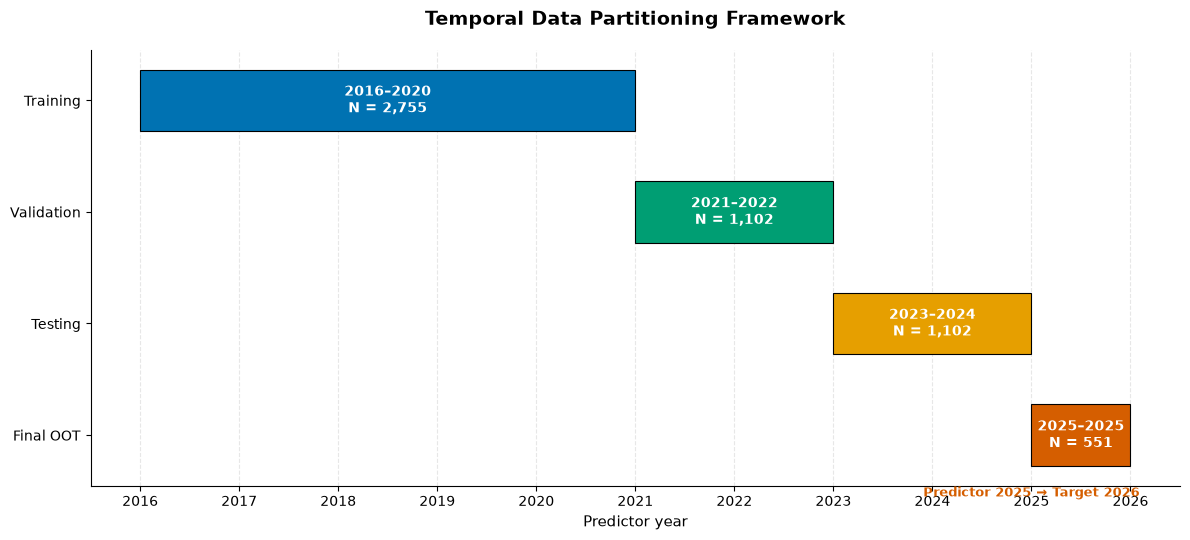

Figure 2 saved successfully.


In [2]:
import matplotlib.pyplot as plt
import os

# Temporal periods
periods = [
    ("Training", 2016, 2020, 2755, "#0072B2"),
    ("Validation", 2021, 2022, 1102, "#009E73"),
    ("Testing", 2023, 2024, 1102, "#E69F00"),
    ("Final OOT", 2025, 2025, 551, "#D55E00")
]

fig, ax = plt.subplots(figsize=(12, 5.5))

for i, (name, start, end, n, color) in enumerate(periods):

    width = end - start + 1

    ax.barh(
        i,
        width,
        left=start,
        height=0.55,
        color=color,
        edgecolor="black",
        linewidth=0.8
    )

    label = (
        f"{start}–{end}\n"
        f"N = {n:,}"
    )

    ax.text(
        start + width / 2,
        i,
        label,
        ha="center",
        va="center",
        color="white",
        fontsize=10,
        fontweight="bold"
    )

# Axis formatting
ax.set_yticks(range(len(periods)))
ax.set_yticklabels([p[0] for p in periods])

ax.invert_yaxis()

ax.set_xticks(range(2016, 2027))
ax.set_xlim(2015.5, 2026.5)

ax.set_xlabel("Predictor year", fontsize=11)
ax.set_title(
    "Temporal Data Partitioning Framework",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Final OOT target explanation
ax.text(
    2025,
    3.55,
    "Predictor 2025 → Target 2026",
    ha="center",
    fontsize=9,
    color="#D55E00",
    fontweight="bold"
)

plt.tight_layout()

# Save figures
os.makedirs("Research_Figures", exist_ok=True)

fig.savefig(
    "Research_Figures/Figure_02_Temporal_Partitioning.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "Research_Figures/Figure_02_Temporal_Partitioning.tiff",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Figure 2 saved successfully.")

In [5]:
import pandas as pd

print("AVAILABLE MODEL AND PREDICTION VARIABLES")
print("=" * 60)

for name, obj in globals().copy().items():

    if any(key in name.lower() for key in [
        "oot", "prediction", "model", "probability"
    ]):

        if isinstance(obj, pd.DataFrame):
            print(f"{name}: DataFrame {obj.shape}")

        elif isinstance(obj, dict):
            print(f"{name}: Dictionary")

        elif hasattr(obj, "predict_proba"):
            print(f"{name}: Trained model")

AVAILABLE MODEL AND PREDICTION VARIABLES


In [6]:
import os

print("CURRENT DIRECTORY:")
print(os.getcwd())

print("\nAVAILABLE FILES:")

for file in os.listdir():
    if file.lower().endswith((
        ".csv", ".xlsx", ".xls",
        ".pkl", ".joblib", ".parquet"
    )):
        print(file)

CURRENT DIRECTORY:
C:\Users\iamku

AVAILABLE FILES:
Algorithm_Summary.csv
Best_Model_Summary.csv
CALIBRATION_BINS_FULL.csv
CALIBRATION_BINS_REDUCED.csv
CALIBRATION_BINS_STRICT.csv
CALIBRATION_PERFORMANCE.csv
Consolidated_Model_Performance.csv
Consolidated_Validation_Results.csv
Detailed_Three_Model_Results.xlsx
distress_model_results.xlsx
DSCR_Debt_Relationship_Analysis.xlsx
DSCR_Extreme_Company_Analysis.xlsx
DSCR_Winsorised_LightGBM_Performance.xlsx
Final_Altman_FULL_STRICT_Comparison.xlsx
FINAL_DEVELOPMENT_LIGHTGBM_FULL.pkl
FINAL_DEVELOPMENT_LIGHTGBM_REDUCED.pkl
FINAL_DEVELOPMENT_LIGHTGBM_STRICT.pkl
FINAL_LIGHTGBM_FULL.pkl
FINAL_LIGHTGBM_REDUCED.pkl
FINAL_LIGHTGBM_STRICT.pkl
Final_LightGBM_Training_Summary.xlsx
FINAL_LIGHTGBM_VALIDATION_PREDICTIONS.csv
FINAL_LIGHTGBM_VALIDATION_RESULTS.csv
Final_Model_Comparison.xlsx
FINAL_OOT_CALIBRATION_BINS_FULL.csv
FINAL_OOT_CALIBRATION_BINS_REDUCED.csv
FINAL_OOT_CALIBRATION_BINS_STRICT.csv
FINAL_OOT_CALIBRATION_PERFORMANCE.csv
FINAL_OOT_CORRECTE

Working directory: C:\Users\iamku
Figure output directory: C:\Users\iamku\Research_Figures
Saved: Figure_01_Annual_Distress_Prevalence


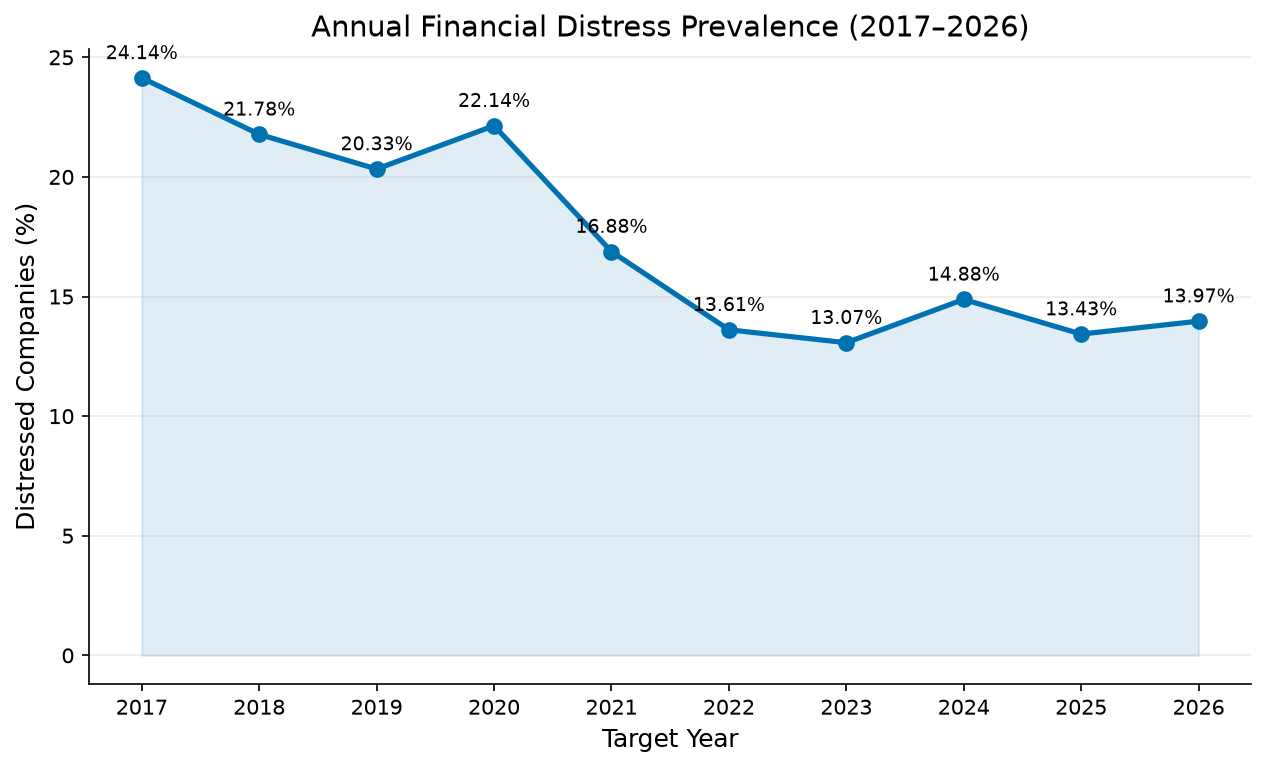

Saved: Figure_02_Temporal_Data_Partitioning


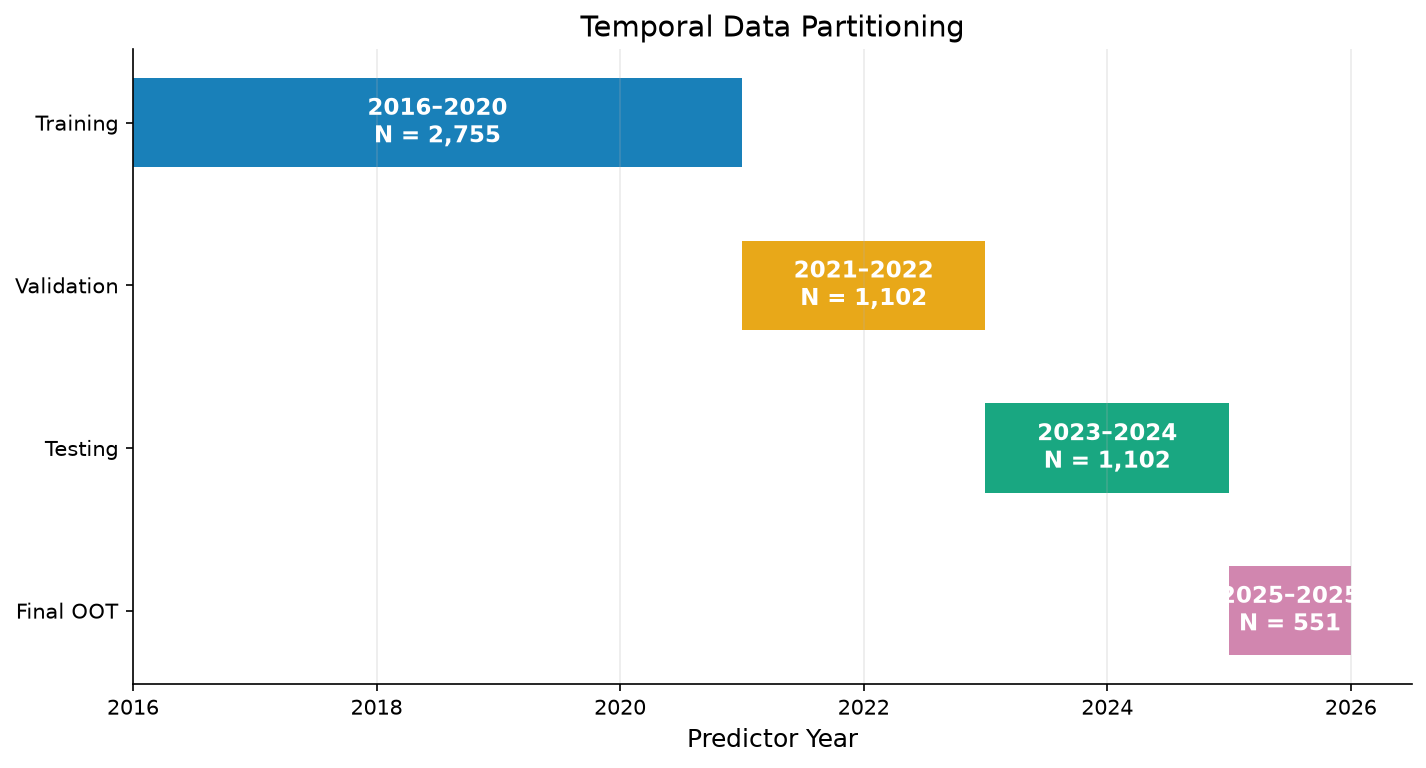


OOT prediction file loaded.
Shape: (551, 8)
Columns: ['Predictor_Year', 'Actual_Distress', 'FULL_Probability', 'REDUCED_Probability', 'STRICT_Probability', 'FULL_Prediction', 'REDUCED_Prediction', 'STRICT_Prediction']

Identified columns:
Target: Actual_Distress
FULL: FULL_Probability
REDUCED: REDUCED_Probability
STRICT: STRICT_Probability

Models with valid probability columns:
['FULL', 'REDUCED', 'STRICT']
Saved: Figure_03_ROC_Curve_Comparison


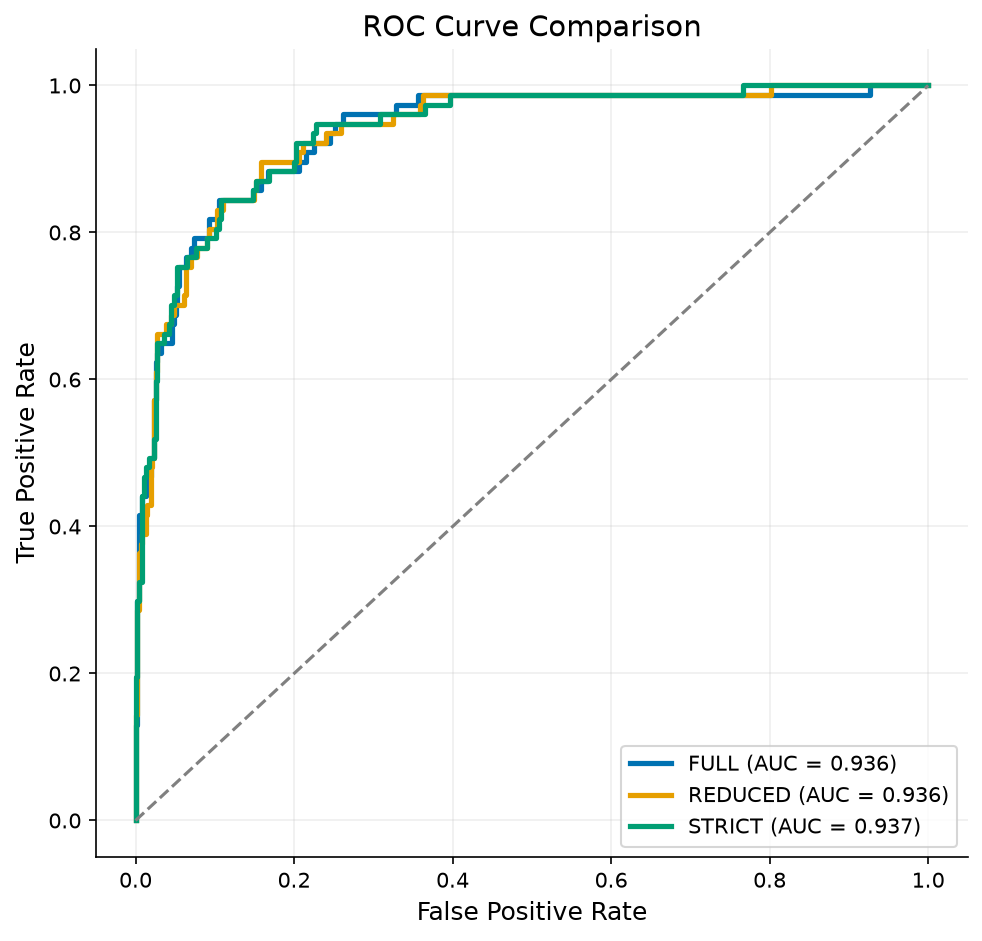

Saved: Figure_04_Precision_Recall_Comparison


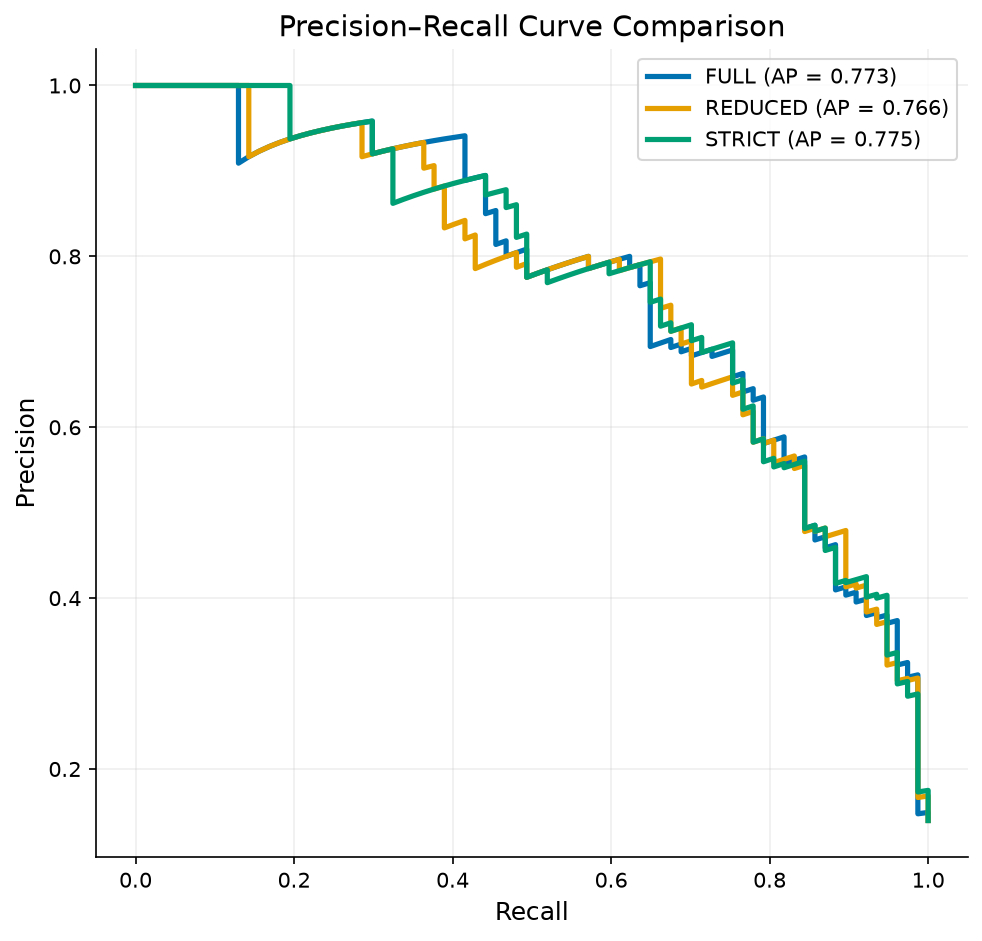

Saved: Figure_05_Confusion_Matrices


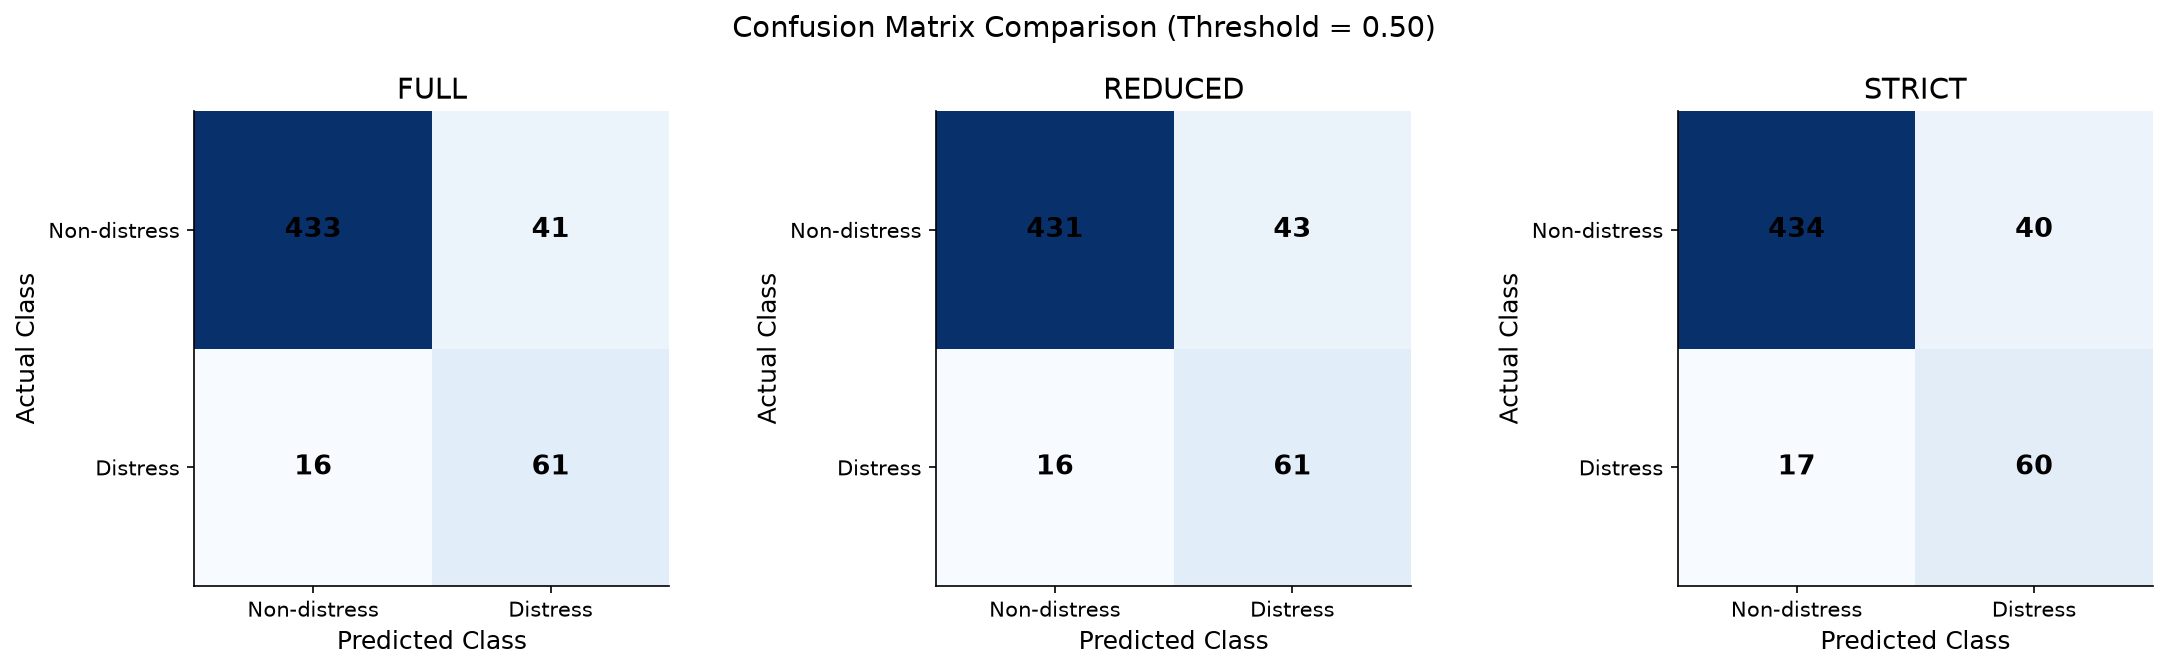


Performance table loaded: LIGHTGBM_FINAL_OOT_PERFORMANCE.csv
  Algorithm    Model  Predictors  Observations  Threshold   ROC_AUC    PR_AUC  \
0  LightGBM     FULL          21           551        0.5  0.935723  0.773269   
1  LightGBM  REDUCED          17           551        0.5  0.935859  0.766356   
2  LightGBM   STRICT          13           551        0.5  0.937038  0.774755   

   Brier_Score  Log_Loss  Accuracy  Sensitivity  Specificity  Precision  \
0     0.071035  0.237285  0.896552     0.792208     0.913502   0.598039   
1     0.071220  0.242605  0.892922     0.792208     0.909283   0.586538   
2     0.070653  0.242337  0.896552     0.779221     0.915612   0.600000   

   F1_Score   TN  FP  FN  TP  
0  0.681564  433  41  16  61  
1  0.674033  431  43  16  61  
2  0.677966  434  40  17  60  

Performance columns:
['Algorithm', 'Model', 'Predictors', 'Observations', 'Threshold', 'ROC_AUC', 'PR_AUC', 'Brier_Score', 'Log_Loss', 'Accuracy', 'Sensitivity', 'Specificity', 'Precision

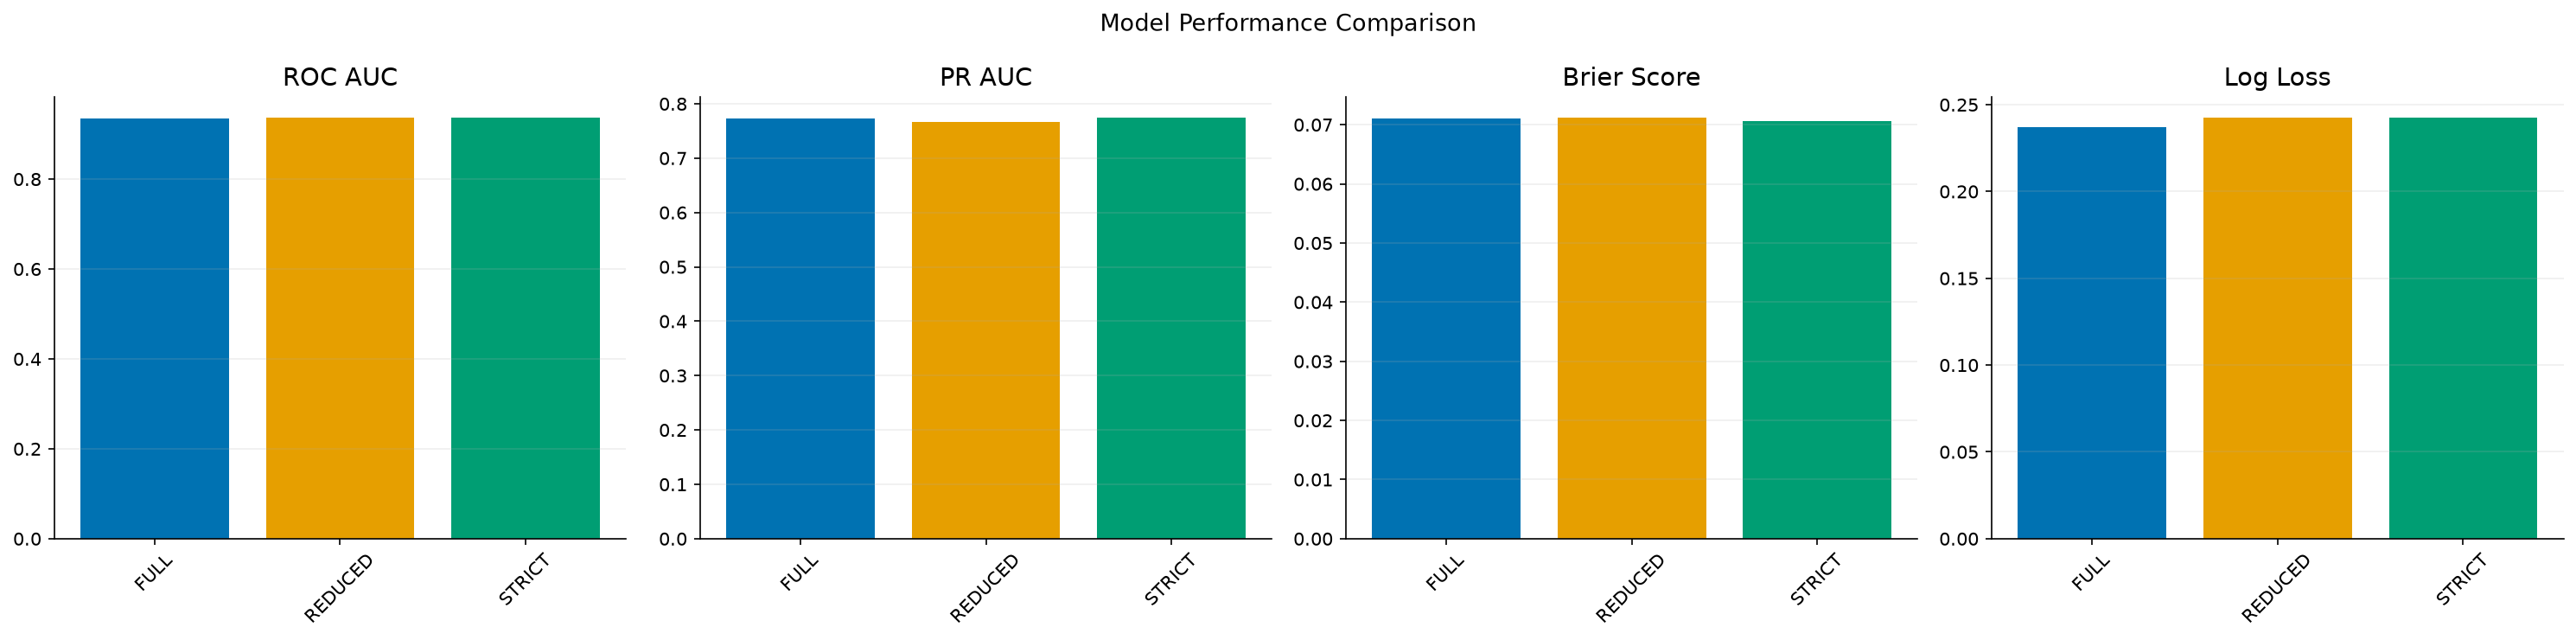

Saved: Figure_07_Calibration_Curves


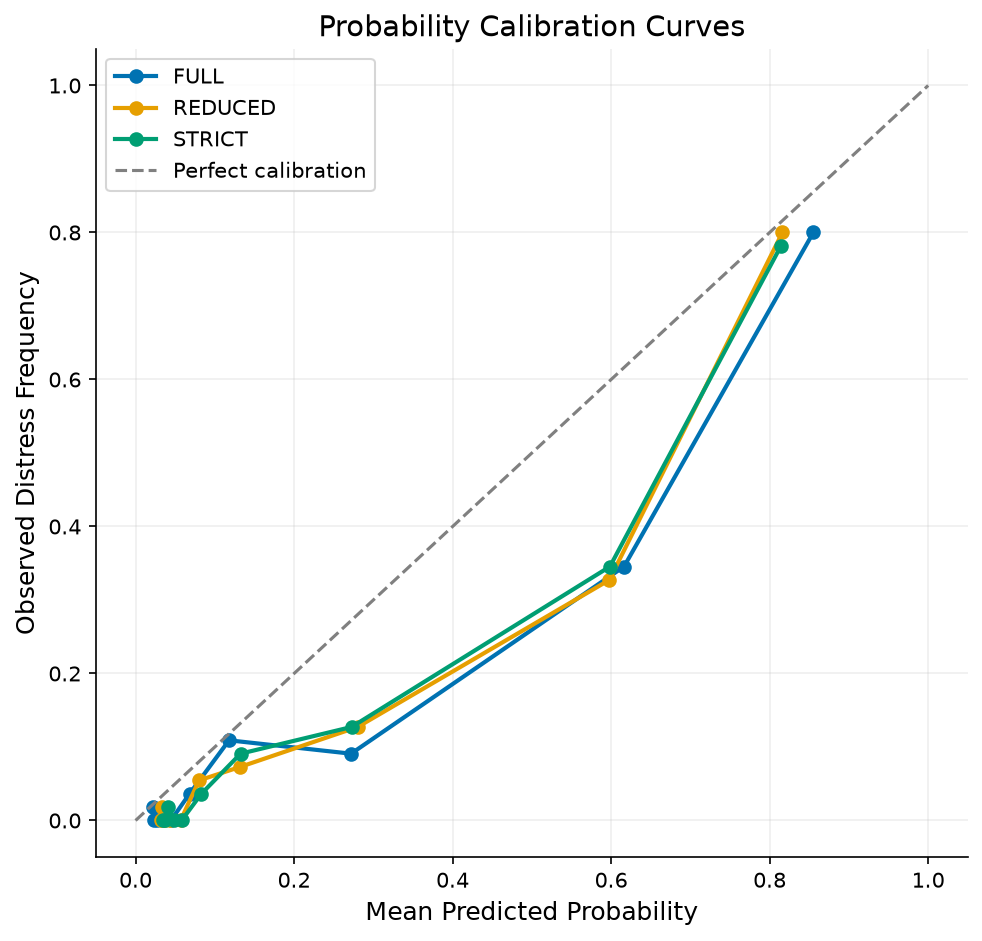

Figure 8 skipped: no recognised SHAP importance CSV found.
Saved: Figure_09_Distress_Transitions


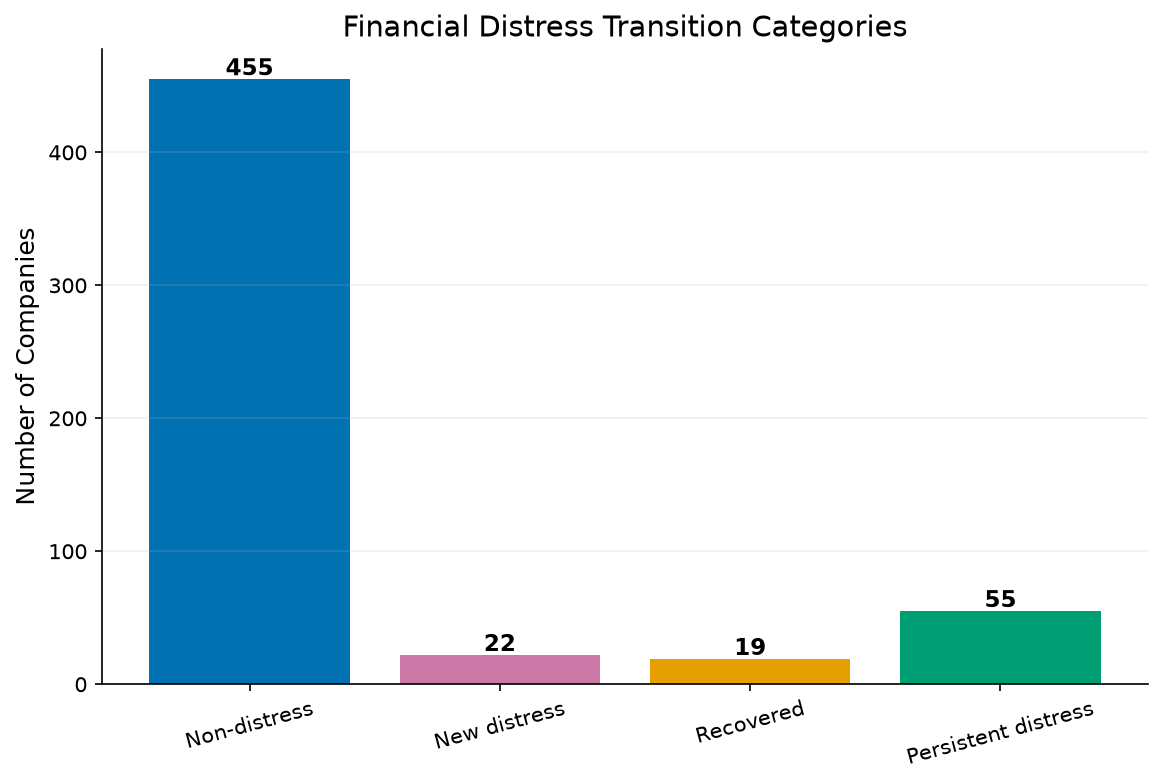


FIGURE GENERATION COMPLETED
Total figure files generated: 16
Output folder: C:\Users\iamku\Research_Figures

Generated files:
Figure_01_Annual_Distress_Prevalence.png
Figure_01_Annual_Distress_Prevalence.tiff
Figure_02_Temporal_Data_Partitioning.png
Figure_02_Temporal_Data_Partitioning.tiff
Figure_03_ROC_Curve_Comparison.png
Figure_03_ROC_Curve_Comparison.tiff
Figure_04_Precision_Recall_Comparison.png
Figure_04_Precision_Recall_Comparison.tiff
Figure_05_Confusion_Matrices.png
Figure_05_Confusion_Matrices.tiff
Figure_06_Model_Performance_Comparison.png
Figure_06_Model_Performance_Comparison.tiff
Figure_07_Calibration_Curves.png
Figure_07_Calibration_Curves.tiff
Figure_09_Distress_Transitions.png
Figure_09_Distress_Transitions.tiff

ZIP FILE CREATED:
C:\Users\iamku\All_Research_Figures.zip

DOWNLOAD ALL FIGURES:


C:\Users\iamku\All_Research_Figures.zip


INDIVIDUAL FIGURE FILES:


C:\Users\iamku\Research_Figures\Figure_01_Annual_Distress_Prevalence.png

C:\Users\iamku\Research_Figures\Figure_02_Temporal_Data_Partitioning.png

C:\Users\iamku\Research_Figures\Figure_03_ROC_Curve_Comparison.png

C:\Users\iamku\Research_Figures\Figure_04_Precision_Recall_Comparison.png

C:\Users\iamku\Research_Figures\Figure_05_Confusion_Matrices.png

C:\Users\iamku\Research_Figures\Figure_06_Model_Performance_Comparison.png

C:\Users\iamku\Research_Figures\Figure_07_Calibration_Curves.png

C:\Users\iamku\Research_Figures\Figure_09_Distress_Transitions.png

In [7]:
# ================================================================
# COMPLETE FIGURE GENERATION AND DOWNLOAD SCRIPT
# ================================================================
# Standalone execution: does not depend on previous notebook cells.
# Output: PNG and TIFF files in Research_Figures folder.
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, FileLink

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

# ================================================================
# 1. DIRECTORY CONFIGURATION
# ================================================================

BASE_DIR = os.getcwd()

OUTPUT_DIR = os.path.join(BASE_DIR, "Research_Figures")
os.makedirs(OUTPUT_DIR, exist_ok=True)

PREDICTION_FILE = os.path.join(
    BASE_DIR,
    "LIGHTGBM_FINAL_OOT_PREDICTIONS.csv"
)

PERFORMANCE_FILES = [
    os.path.join(BASE_DIR, "LIGHTGBM_FINAL_OOT_PERFORMANCE.csv"),
    os.path.join(BASE_DIR, "OOT_ORIGINAL_MODEL_PERFORMANCE.csv")
]

EXCEL_FILE = os.path.join(
    BASE_DIR,
    "Financial_Distress_Research_Tables.xlsx"
)

print("Working directory:", BASE_DIR)
print("Figure output directory:", OUTPUT_DIR)

# ================================================================
# 2. GLOBAL FIGURE SETTINGS
# ================================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False
})

COLORS = {
    "FULL": "#0072B2",
    "REDUCED": "#E69F00",
    "STRICT": "#009E73",
    "ALTMAN": "#CC79A7",
    "PERSISTENCE": "#666666",
    "OTHER": "#56B4E9"
}

# ================================================================
# 3. SAVE FIGURE FUNCTION
# ================================================================

generated_figures = []

def save_figure(fig, filename):

    png_path = os.path.join(OUTPUT_DIR, filename + ".png")
    tif_path = os.path.join(OUTPUT_DIR, filename + ".tiff")

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        tif_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    generated_figures.extend([png_path, tif_path])

    print("Saved:", filename)

    plt.show()
    plt.close(fig)


# ================================================================
# FIGURE 1 — ANNUAL DISTRESS PREVALENCE
# ================================================================

years = np.arange(2017, 2027)

distress_rates = np.array([
    24.14, 21.78, 20.33, 22.14, 16.88,
    13.61, 13.07, 14.88, 13.43, 13.97
])

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    years,
    distress_rates,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color=COLORS["FULL"]
)

ax.fill_between(
    years,
    distress_rates,
    alpha=0.12,
    color=COLORS["FULL"]
)

for x, y in zip(years, distress_rates):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title("Annual Financial Distress Prevalence (2017–2026)")
ax.set_xlabel("Target Year")
ax.set_ylabel("Distressed Companies (%)")
ax.set_xticks(years)
ax.grid(axis="y", alpha=0.25)

save_figure(fig, "Figure_01_Annual_Distress_Prevalence")


# ================================================================
# FIGURE 2 — TEMPORAL DATA PARTITIONING
# ================================================================

partitions = [
    ("Training", 2016, 2020, 2755),
    ("Validation", 2021, 2022, 1102),
    ("Testing", 2023, 2024, 1102),
    ("Final OOT", 2025, 2025, 551)
]

fig, ax = plt.subplots(figsize=(11, 5.5))

partition_colors = [
    COLORS["FULL"],
    COLORS["REDUCED"],
    COLORS["STRICT"],
    COLORS["ALTMAN"]
]

for i, (name, start, end, n) in enumerate(partitions):

    width = end - start + 1

    ax.barh(
        i,
        width,
        left=start,
        height=0.55,
        color=partition_colors[i],
        alpha=0.9
    )

    ax.text(
        start + width / 2,
        i,
        f"{start}–{end}\nN = {n:,}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

ax.set_yticks(range(len(partitions)))
ax.set_yticklabels([p[0] for p in partitions])
ax.invert_yaxis()

ax.set_xlabel("Predictor Year")
ax.set_title("Temporal Data Partitioning")
ax.grid(axis="x", alpha=0.25)

save_figure(fig, "Figure_02_Temporal_Data_Partitioning")


# ================================================================
# 4. LOAD OOT PREDICTIONS
# ================================================================

oot = None

if os.path.exists(PREDICTION_FILE):

    oot = pd.read_csv(PREDICTION_FILE)

    print("\nOOT prediction file loaded.")
    print("Shape:", oot.shape)
    print("Columns:", oot.columns.tolist())

else:

    print("\nOOT prediction CSV not found.")
    print("Prediction-dependent figures will be skipped.")


# ================================================================
# 5. AUTOMATIC COLUMN IDENTIFICATION
# ================================================================

def find_column(df, candidates):

    if df is None:
        return None

    lower_map = {
        str(col).lower().replace(" ", "_"): col
        for col in df.columns
    }

    for candidate in candidates:

        key = candidate.lower().replace(" ", "_")

        if key in lower_map:
            return lower_map[key]

    return None


if oot is not None:

    target_col = find_column(
        oot,
        [
            "Target_Distress",
            "Actual",
            "Actual_Distress",
            "y_true",
            "target",
            "distress_actual"
        ]
    )

    full_col = find_column(
        oot,
        [
            "FULL_Probability",
            "FULL_Prob",
            "FULL_Probability_Distress",
            "FULL_Predicted_Probability",
            "FULL"
        ]
    )

    reduced_col = find_column(
        oot,
        [
            "REDUCED_Probability",
            "REDUCED_Prob",
            "REDUCED_Probability_Distress",
            "REDUCED_Predicted_Probability",
            "REDUCED"
        ]
    )

    strict_col = find_column(
        oot,
        [
            "STRICT_Probability",
            "STRICT_Prob",
            "STRICT_Probability_Distress",
            "STRICT_Predicted_Probability",
            "STRICT"
        ]
    )

    print("\nIdentified columns:")
    print("Target:", target_col)
    print("FULL:", full_col)
    print("REDUCED:", reduced_col)
    print("STRICT:", strict_col)

else:

    target_col = None
    full_col = None
    reduced_col = None
    strict_col = None


# ================================================================
# 6. PREPARE VALID PROBABILITY DATA
# ================================================================

model_columns = {
    "FULL": full_col,
    "REDUCED": reduced_col,
    "STRICT": strict_col
}

valid_models = {}

if oot is not None and target_col is not None:

    for model_name, column in model_columns.items():

        if column is None:
            continue

        values = pd.to_numeric(
            oot[column],
            errors="coerce"
        )

        if values.notna().sum() == 0:
            continue

        if values.dropna().between(0, 1).all():

            valid_models[model_name] = values

    print("\nModels with valid probability columns:")
    print(list(valid_models.keys()))


# ================================================================
# FIGURE 3 — ROC CURVE COMPARISON
# ================================================================

if len(valid_models) > 0:

    y = pd.to_numeric(
        oot[target_col],
        errors="coerce"
    )

    fig, ax = plt.subplots(figsize=(7.5, 7))

    for model_name, probability in valid_models.items():

        data = pd.DataFrame({
            "actual": y,
            "probability": probability
        }).dropna()

        fpr, tpr, _ = roc_curve(
            data["actual"],
            data["probability"]
        )

        roc_auc = auc(fpr, tpr)

        ax.plot(
            fpr,
            tpr,
            linewidth=2.5,
            color=COLORS[model_name],
            label=f"{model_name} (AUC = {roc_auc:.3f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="grey",
        linewidth=1.5
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curve Comparison")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.2)

    save_figure(fig, "Figure_03_ROC_Curve_Comparison")

else:

    print("Figure 3 skipped: valid probability columns unavailable.")


# ================================================================
# FIGURE 4 — PRECISION-RECALL CURVE
# ================================================================

if len(valid_models) > 0:

    y = pd.to_numeric(
        oot[target_col],
        errors="coerce"
    )

    fig, ax = plt.subplots(figsize=(7.5, 7))

    for model_name, probability in valid_models.items():

        data = pd.DataFrame({
            "actual": y,
            "probability": probability
        }).dropna()

        precision, recall, _ = precision_recall_curve(
            data["actual"],
            data["probability"]
        )

        ap = average_precision_score(
            data["actual"],
            data["probability"]
        )

        ax.plot(
            recall,
            precision,
            linewidth=2.5,
            color=COLORS[model_name],
            label=f"{model_name} (AP = {ap:.3f})"
        )

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("Precision–Recall Curve Comparison")
    ax.legend(loc="best")
    ax.grid(alpha=0.2)

    save_figure(fig, "Figure_04_Precision_Recall_Comparison")

else:

    print("Figure 4 skipped: valid probability columns unavailable.")


# ================================================================
# FIGURE 5 — CONFUSION MATRICES
# ================================================================

if len(valid_models) > 0:

    y = pd.to_numeric(
        oot[target_col],
        errors="coerce"
    )

    available = list(valid_models.keys())

    fig, axes = plt.subplots(
        1,
        len(available),
        figsize=(5 * len(available), 4.5)
    )

    if len(available) == 1:
        axes = [axes]

    for ax, model_name in zip(axes, available):

        data = pd.DataFrame({
            "actual": y,
            "probability": valid_models[model_name]
        }).dropna()

        predicted = (
            data["probability"] >= 0.50
        ).astype(int)

        cm = confusion_matrix(
            data["actual"].astype(int),
            predicted
        )

        image = ax.imshow(
            cm,
            cmap="Blues"
        )

        for row in range(2):
            for col in range(2):

                ax.text(
                    col,
                    row,
                    f"{cm[row, col]:,}",
                    ha="center",
                    va="center",
                    fontsize=13,
                    fontweight="bold"
                )

        ax.set_title(model_name)
        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["Non-distress", "Distress"])
        ax.set_yticklabels(["Non-distress", "Distress"])

    fig.suptitle(
        "Confusion Matrix Comparison (Threshold = 0.50)",
        fontsize=14
    )

    fig.tight_layout()

    save_figure(fig, "Figure_05_Confusion_Matrices")

else:

    print("Figure 5 skipped: valid probability columns unavailable.")


# ================================================================
# 7. LOAD PERFORMANCE TABLE
# ================================================================

performance = None

for file in PERFORMANCE_FILES:

    if os.path.exists(file):

        try:

            performance = pd.read_csv(file)

            if not performance.empty:
                print("\nPerformance table loaded:", os.path.basename(file))
                print(performance.head())
                break

        except Exception as error:

            print("Could not read:", file, error)


# ================================================================
# FIGURE 6 — MODEL PERFORMANCE COMPARISON
# ================================================================

if performance is not None:

    print("\nPerformance columns:")
    print(performance.columns.tolist())

    model_name_col = find_column(
        performance,
        ["Model", "Specification", "Model_Name"]
    )

    metric_candidates = [
        "ROC_AUC",
        "PR_AUC",
        "Brier_Score",
        "Log_Loss"
    ]

    available_metrics = [
        col for col in metric_candidates
        if col in performance.columns
    ]

    if model_name_col is not None and available_metrics:

        plot_data = performance.copy()

        plot_data[model_name_col] = (
            plot_data[model_name_col].astype(str)
        )

        for metric in available_metrics:

            plot_data[metric] = pd.to_numeric(
                plot_data[metric],
                errors="coerce"
            )

        fig, axes = plt.subplots(
            1,
            len(available_metrics),
            figsize=(5 * len(available_metrics), 5)
        )

        if len(available_metrics) == 1:
            axes = [axes]

        for ax, metric in zip(axes, available_metrics):

            temp = plot_data.dropna(
                subset=[metric]
            )

            ax.bar(
                temp[model_name_col],
                temp[metric],
                color=[
                    COLORS.get(str(name).upper(), COLORS["OTHER"])
                    for name in temp[model_name_col]
                ]
            )

            ax.set_title(metric.replace("_", " "))
            ax.tick_params(axis="x", rotation=45)
            ax.grid(axis="y", alpha=0.2)

        fig.suptitle("Model Performance Comparison")
        fig.tight_layout()

        save_figure(fig, "Figure_06_Model_Performance_Comparison")

    else:

        print("Figure 6 skipped: required performance columns unavailable.")

else:

    print("Figure 6 skipped: performance file unavailable.")


# ================================================================
# FIGURE 7 — CALIBRATION CURVES
# ================================================================

if len(valid_models) > 0:

    y = pd.to_numeric(
        oot[target_col],
        errors="coerce"
    )

    fig, ax = plt.subplots(figsize=(7.5, 7))

    for model_name, probability in valid_models.items():

        data = pd.DataFrame({
            "actual": y,
            "probability": probability
        }).dropna()

        fraction_positive, mean_probability = calibration_curve(
            data["actual"].astype(int),
            data["probability"],
            n_bins=10,
            strategy="quantile"
        )

        ax.plot(
            mean_probability,
            fraction_positive,
            marker="o",
            linewidth=2,
            color=COLORS[model_name],
            label=model_name
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="grey",
        label="Perfect calibration"
    )

    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Observed Distress Frequency")
    ax.set_title("Probability Calibration Curves")
    ax.legend()
    ax.grid(alpha=0.2)

    save_figure(fig, "Figure_07_Calibration_Curves")

else:

    print("Figure 7 skipped: valid probability columns unavailable.")


# ================================================================
# 8. LOAD SHAP IMPORTANCE FILE
# ================================================================

shap_candidates = [
    "STRICT_SHAP_IMPORTANCE.csv",
    "SHAP_GLOBAL_FEATURE_IMPORTANCE.csv",
    "GLOBAL_SHAP_FEATURE_IMPORTANCE.csv",
    "PROXY_EXCLUDED_SHAP_IMPORTANCE.csv"
]

shap_file = None
shap_data = None

for filename in shap_candidates:

    path = os.path.join(BASE_DIR, filename)

    if os.path.exists(path):

        try:

            temp = pd.read_csv(path)

            if not temp.empty:

                shap_file = path
                shap_data = temp
                print("\nSHAP file loaded:", filename)
                break

        except Exception:
            pass


# ================================================================
# FIGURE 8 — SHAP FEATURE IMPORTANCE
# ================================================================

if shap_data is not None:

    feature_col = find_column(
        shap_data,
        ["Feature", "Variable", "Feature_Name"]
    )

    importance_col = find_column(
        shap_data,
        [
            "Mean_Absolute_SHAP",
            "MeanAbsSHAP",
            "Mean_Abs_SHAP",
            "Importance"
        ]
    )

    if feature_col is not None and importance_col is not None:

        shap_data[importance_col] = pd.to_numeric(
            shap_data[importance_col],
            errors="coerce"
        )

        shap_plot = (
            shap_data
            .dropna(subset=[importance_col])
            .sort_values(importance_col, ascending=True)
            .tail(15)
        )

        fig, ax = plt.subplots(figsize=(9, 7))

        ax.barh(
            shap_plot[feature_col],
            shap_plot[importance_col],
            color=COLORS["FULL"]
        )

        ax.set_xlabel("Mean Absolute SHAP Value")
        ax.set_ylabel("Predictor")
        ax.set_title("Global SHAP Feature Importance")
        ax.grid(axis="x", alpha=0.2)

        save_figure(fig, "Figure_08_SHAP_Feature_Importance")

    else:

        print("Figure 8 skipped: SHAP columns not identified.")

else:

    print("Figure 8 skipped: no recognised SHAP importance CSV found.")


# ================================================================
# FIGURE 9 — DISTRESS TRANSITION ANALYSIS
# ================================================================

transition_labels = [
    "Non-distress",
    "New distress",
    "Recovered",
    "Persistent distress"
]

transition_counts = [455, 22, 19, 55]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    transition_labels,
    transition_counts,
    color=[
        COLORS["FULL"],
        COLORS["ALTMAN"],
        COLORS["REDUCED"],
        COLORS["STRICT"]
    ]
)

for bar, value in zip(bars, transition_counts):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        str(value),
        ha="center",
        fontweight="bold"
    )

ax.set_ylabel("Number of Companies")
ax.set_title("Financial Distress Transition Categories")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.2)

save_figure(fig, "Figure_09_Distress_Transitions")


# ================================================================
# 10. CREATE FIGURE INDEX
# ================================================================

figure_index = pd.DataFrame({
    "Figure_File": [
        os.path.basename(path)
        for path in generated_figures
    ],
    "Full_Path": generated_figures
})

index_path = os.path.join(
    OUTPUT_DIR,
    "Figure_Index.csv"
)

figure_index.to_csv(
    index_path,
    index=False
)

print("\n" + "=" * 65)
print("FIGURE GENERATION COMPLETED")
print("=" * 65)

print("Total figure files generated:", len(generated_figures))
print("Output folder:", OUTPUT_DIR)

print("\nGenerated files:")
for path in generated_figures:
    print(os.path.basename(path))


# ================================================================
# 11. CREATE ZIP FILE FOR DOWNLOADING ALL FIGURES
# ================================================================

import zipfile

zip_path = os.path.join(
    BASE_DIR,
    "All_Research_Figures.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for path in generated_figures:

        if os.path.exists(path):

            zip_file.write(
                path,
                arcname=os.path.join(
                    "Research_Figures",
                    os.path.basename(path)
                )
            )

    zip_file.write(
        index_path,
        arcname="Research_Figures/Figure_Index.csv"
    )

print("\nZIP FILE CREATED:")
print(zip_path)

# ================================================================
# 12. DOWNLOAD LINKS
# ================================================================

print("\nDOWNLOAD ALL FIGURES:")
display(FileLink(zip_path))

print("\nINDIVIDUAL FIGURE FILES:")

for path in generated_figures:

    if path.endswith(".png"):
        display(FileLink(path))

In [8]:
%pip install pandas numpy matplotlib seaborn scikit-learn shap openpyxl joblib

Note: you may need to restart the kernel to use updated packages.


Working directory: C:\Users\iamku
Output directory: C:\Users\iamku\Research_Figures


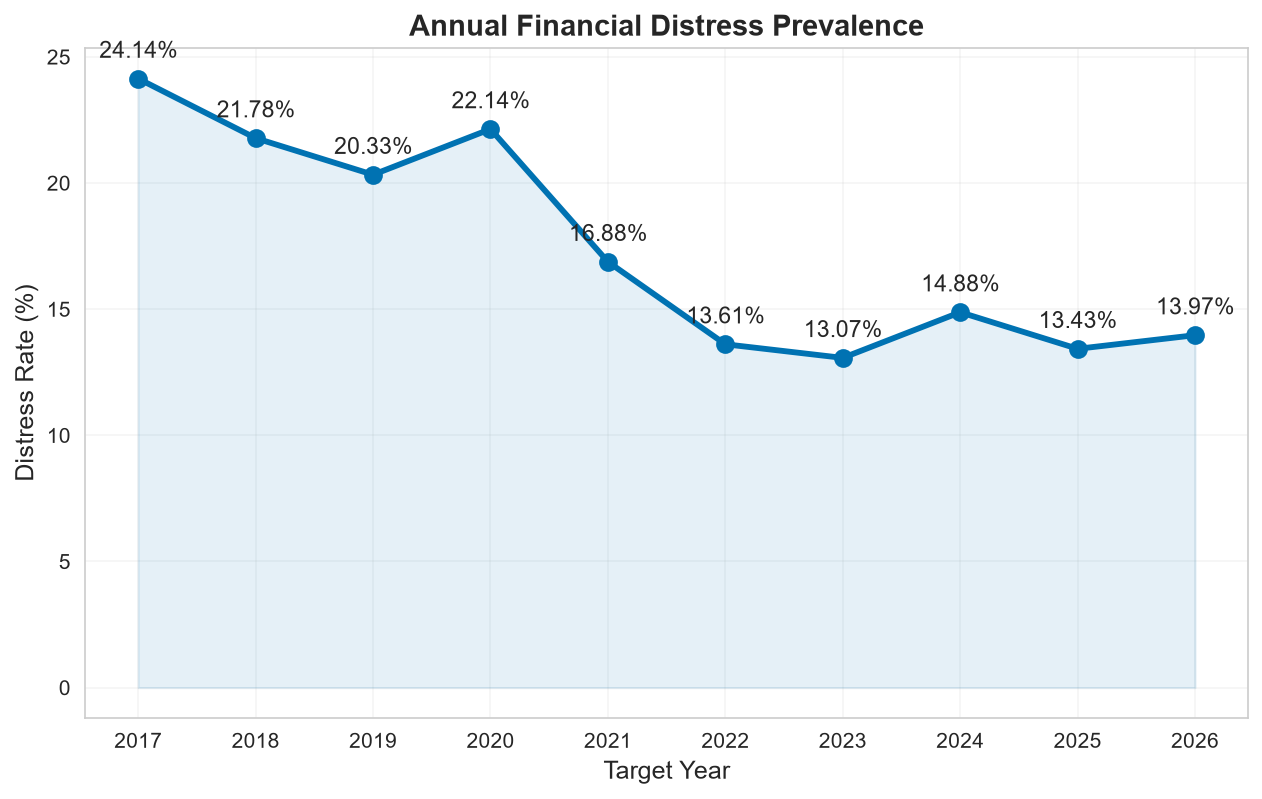

Saved: Figure_01_Annual_Distress_Prevalence


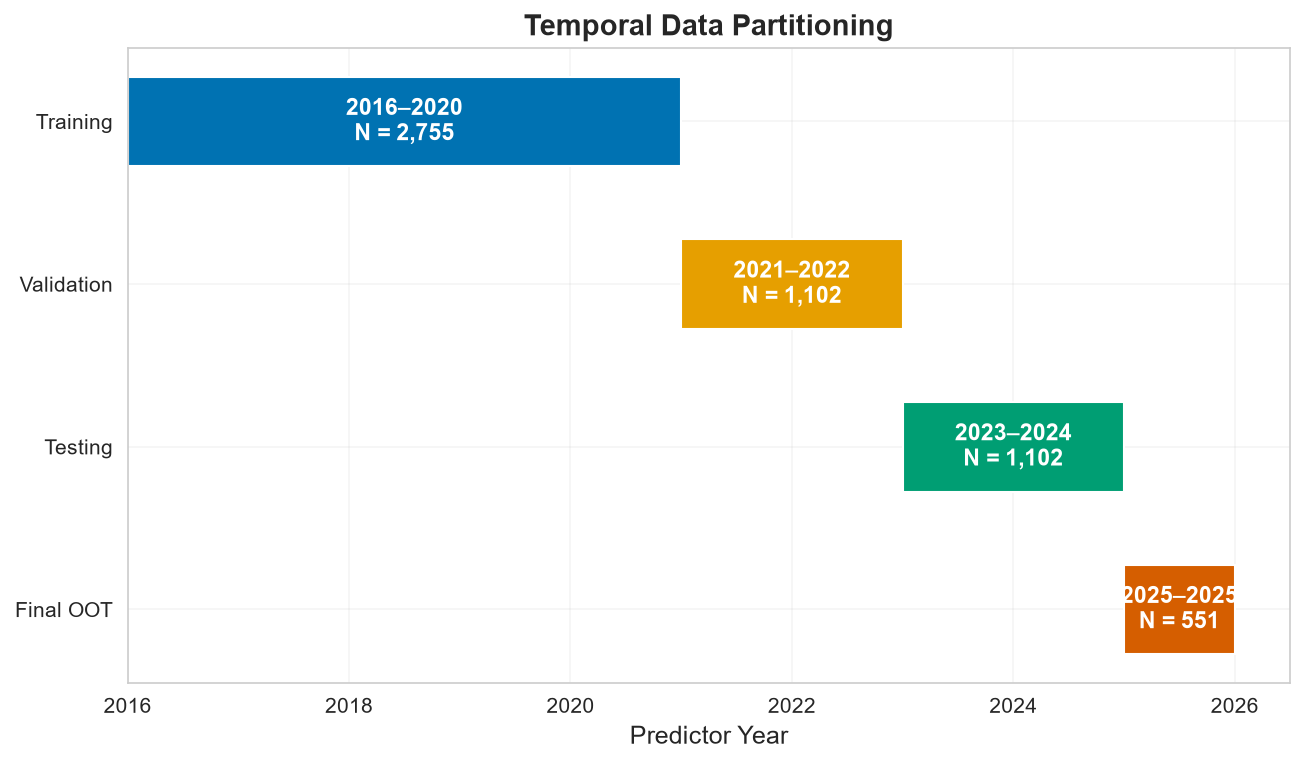

Saved: Figure_02_Temporal_Data_Partitioning

OOT prediction dataset:
(551, 8)
['Predictor_Year', 'Actual_Distress', 'FULL_Probability', 'REDUCED_Probability', 'STRICT_Probability', 'FULL_Prediction', 'REDUCED_Prediction', 'STRICT_Prediction']

Available probability models:
['FULL', 'REDUCED', 'STRICT']

Performance table columns:
['Algorithm', 'Model', 'Predictors', 'Observations', 'Threshold', 'ROC_AUC', 'PR_AUC', 'Brier_Score', 'Log_Loss', 'Accuracy', 'Sensitivity', 'Specificity', 'Precision', 'F1_Score', 'TN', 'FP', 'FN', 'TP']


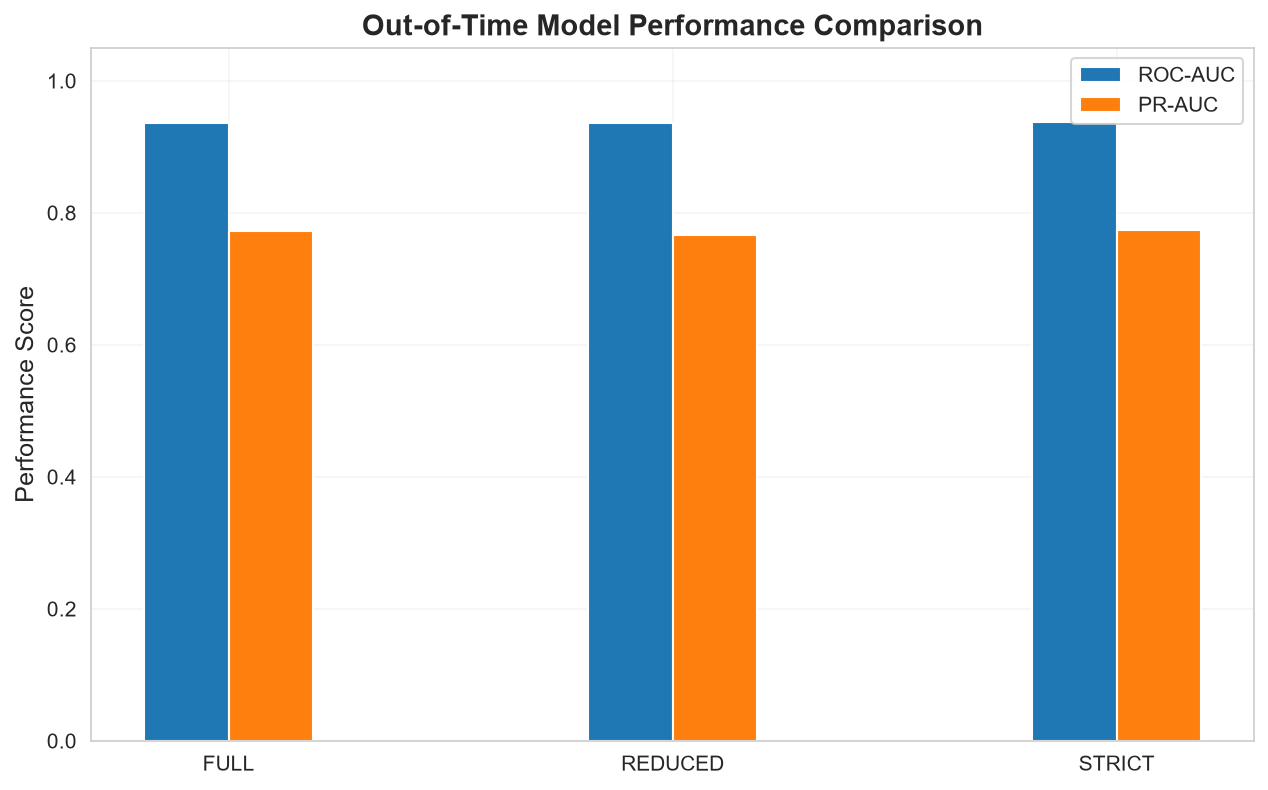

Saved: Figure_03_OOT_Model_Performance


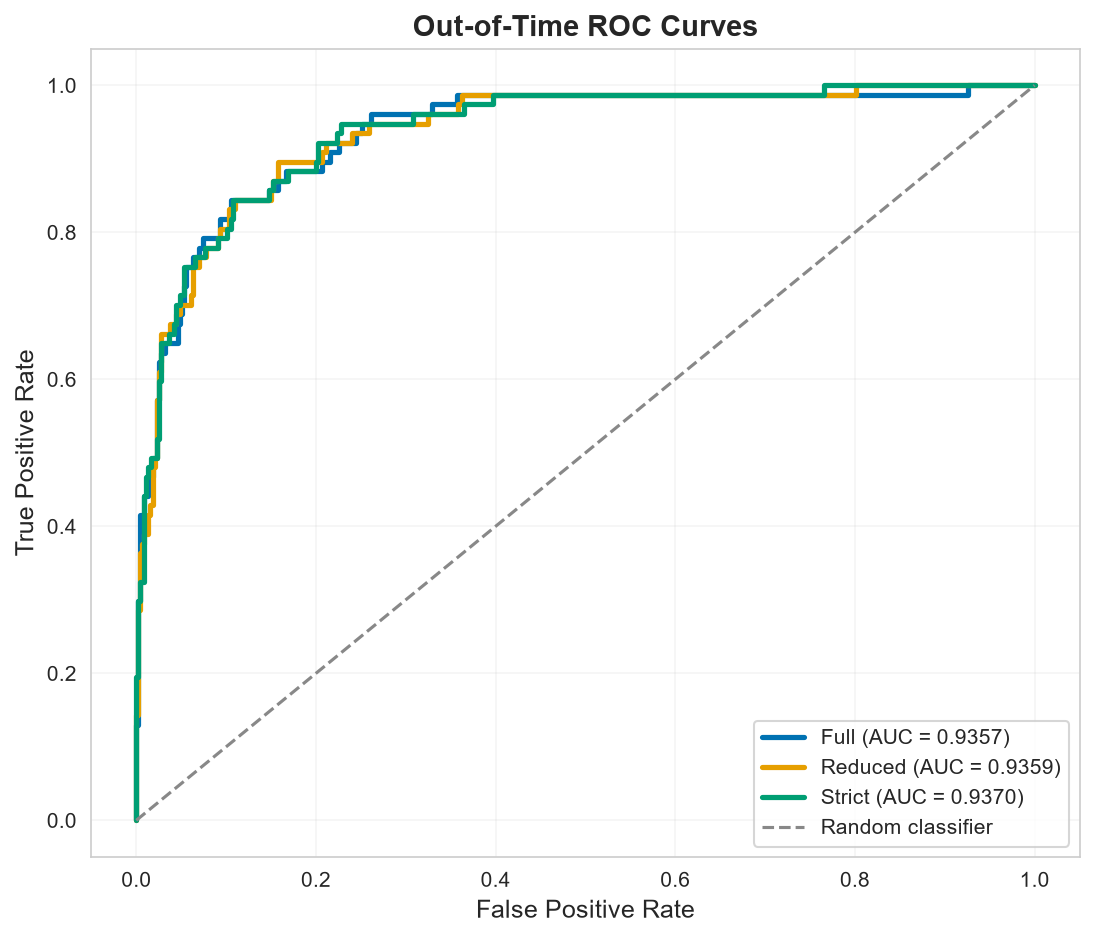

Saved: Figure_04_OOT_ROC_Curves


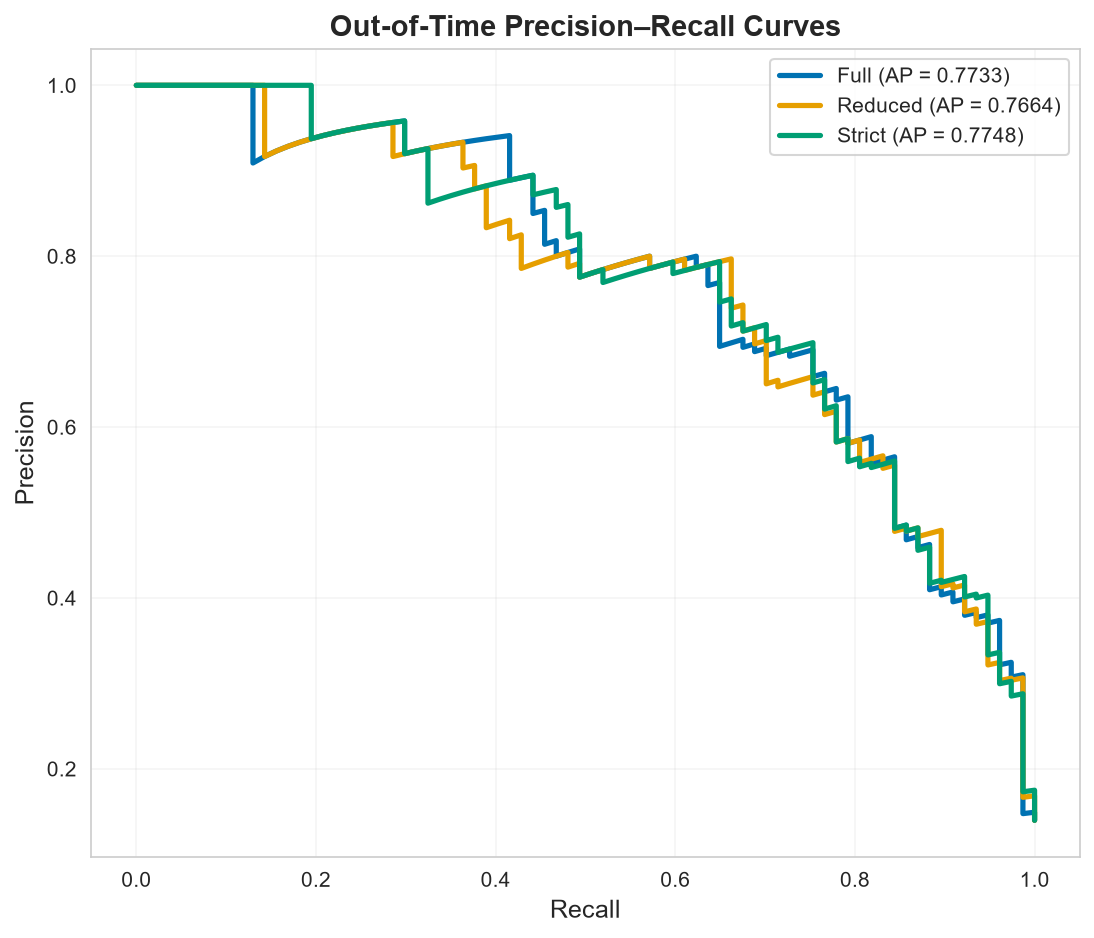

Saved: Figure_05_OOT_Precision_Recall


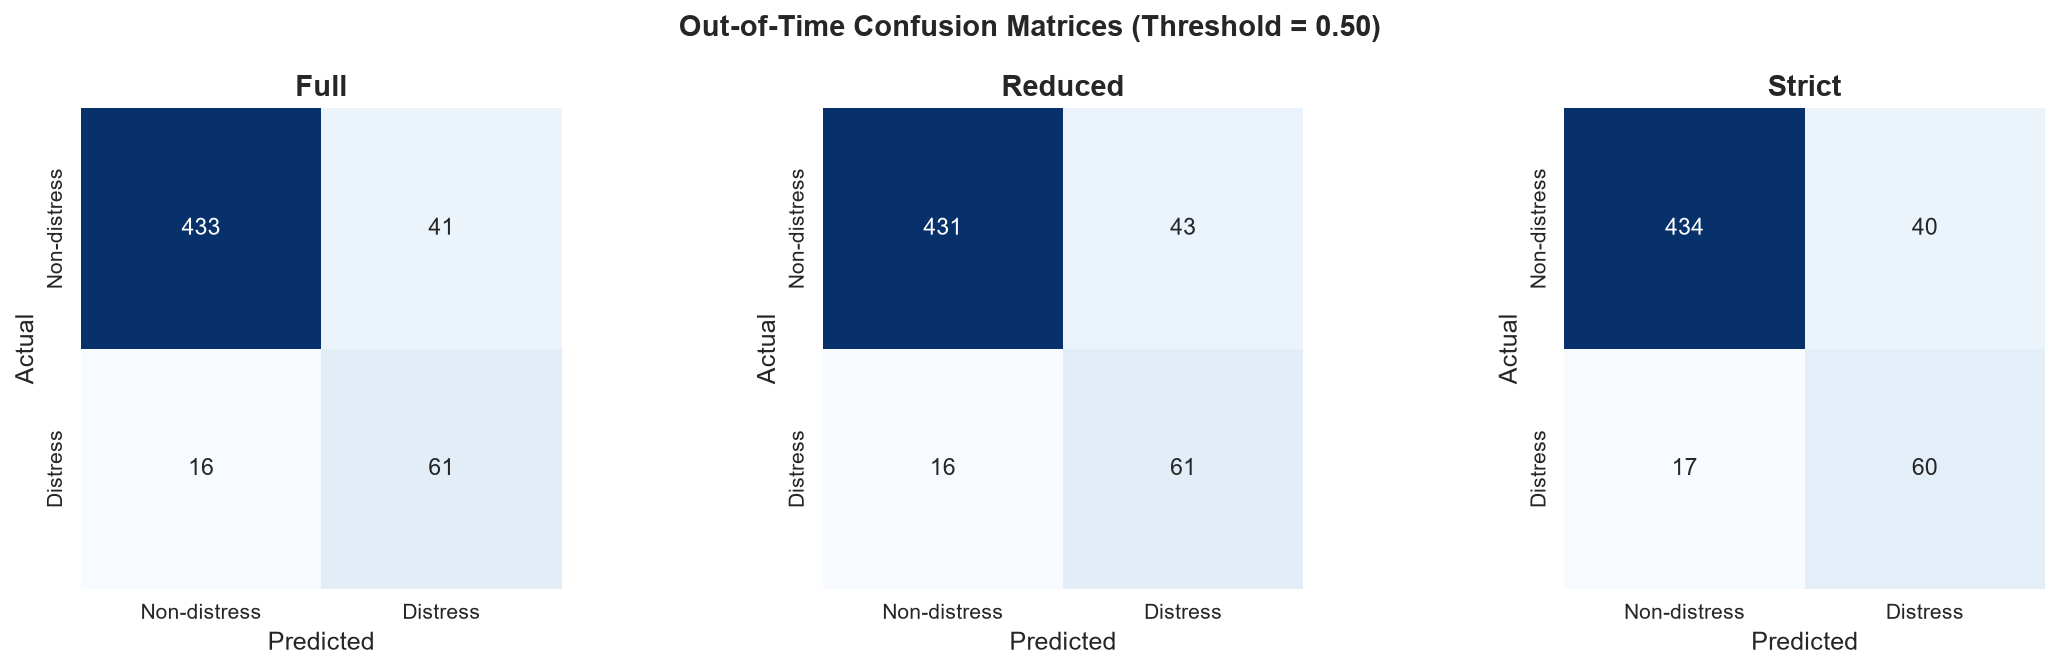

Saved: Figure_06_Confusion_Matrices


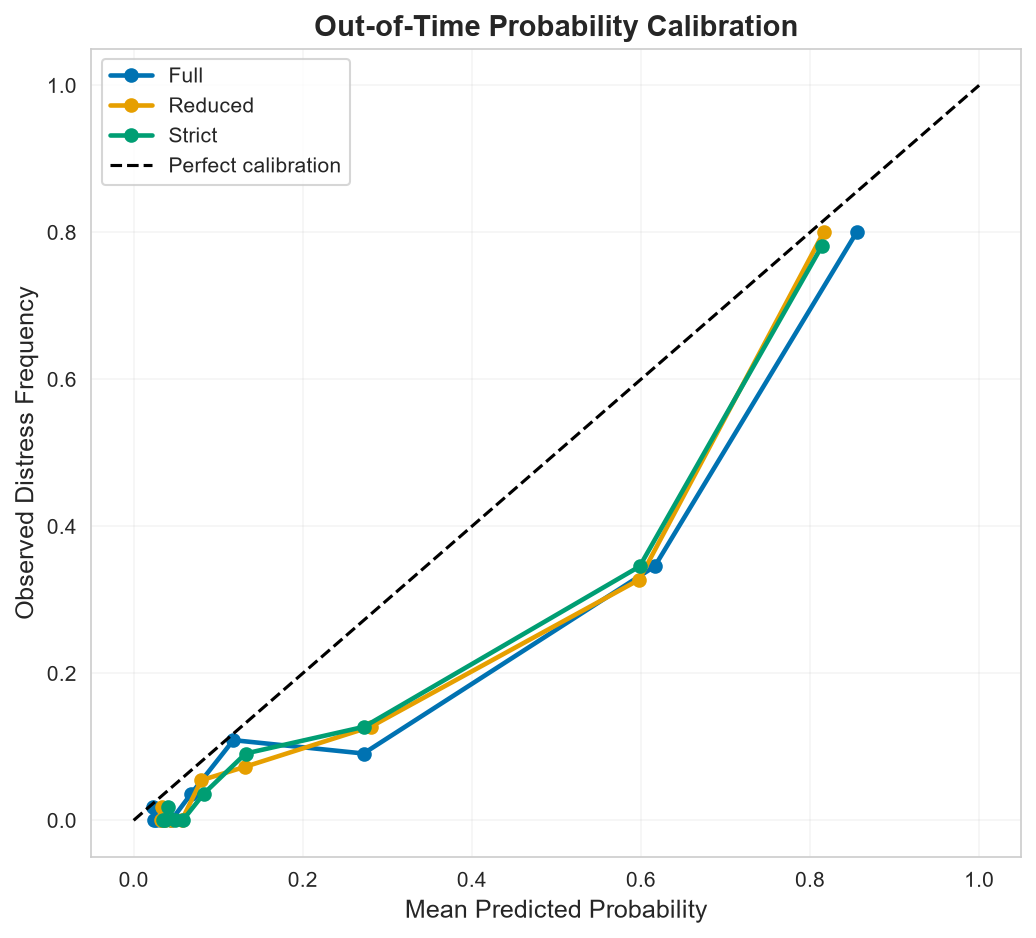

Saved: Figure_07_Calibration_Curves


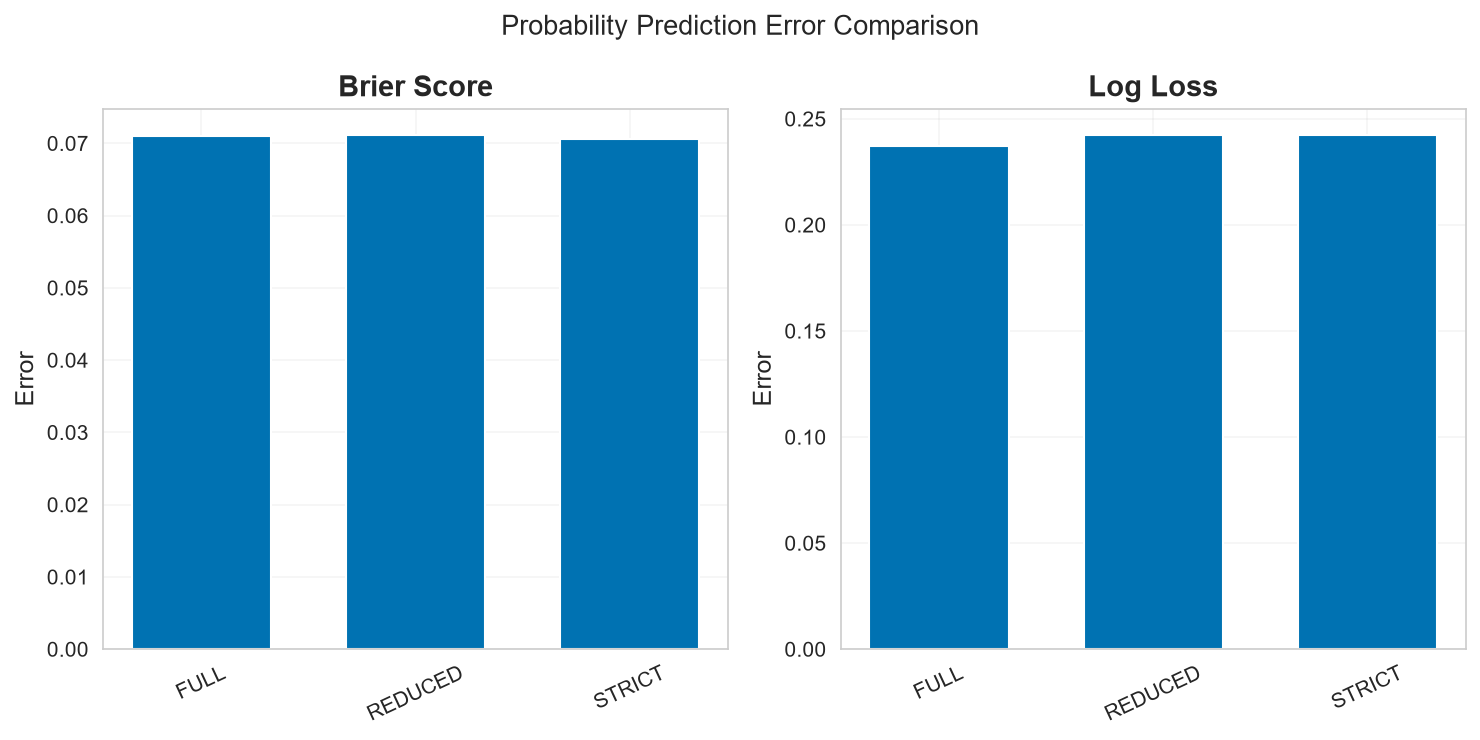

Saved: Figure_08_Probability_Error


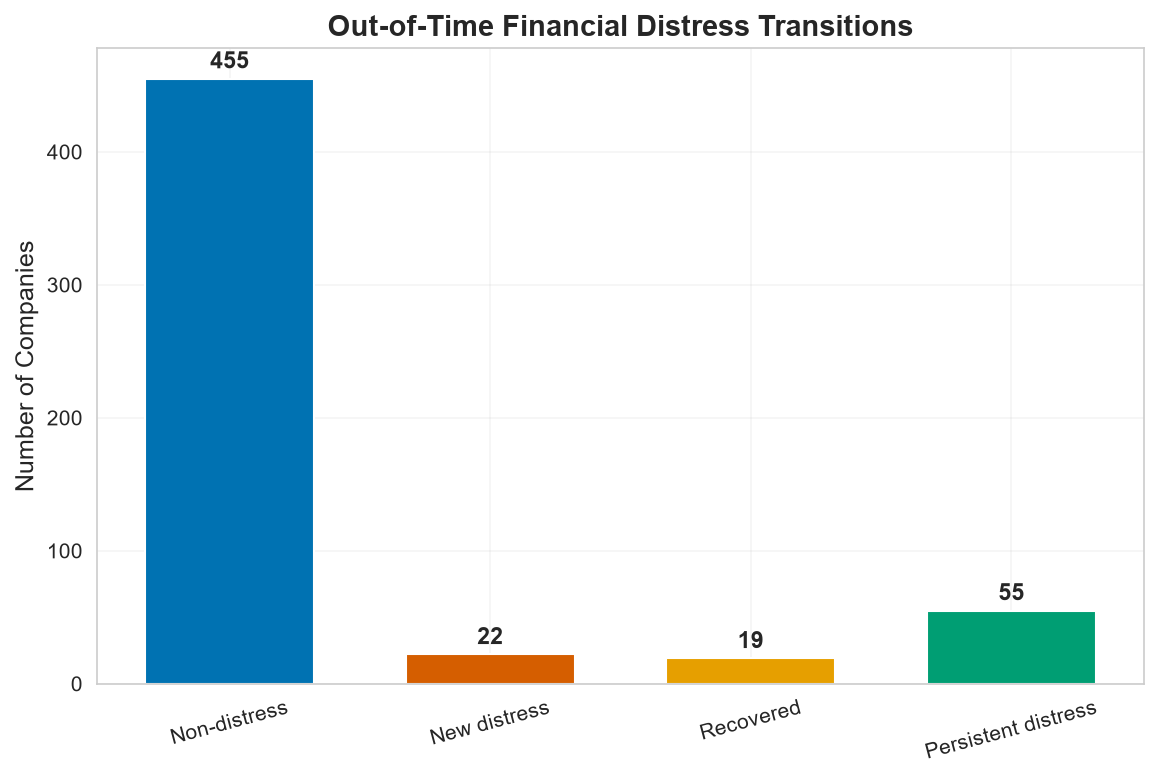

Saved: Figure_09_Distress_Transitions

SHAP importance file:
C:\Users\iamku\STRICT_SHAP_GLOBAL_IMPORTANCE.csv
['Feature', 'Mean_Absolute_SHAP', 'Mean_SHAP', 'Rank']


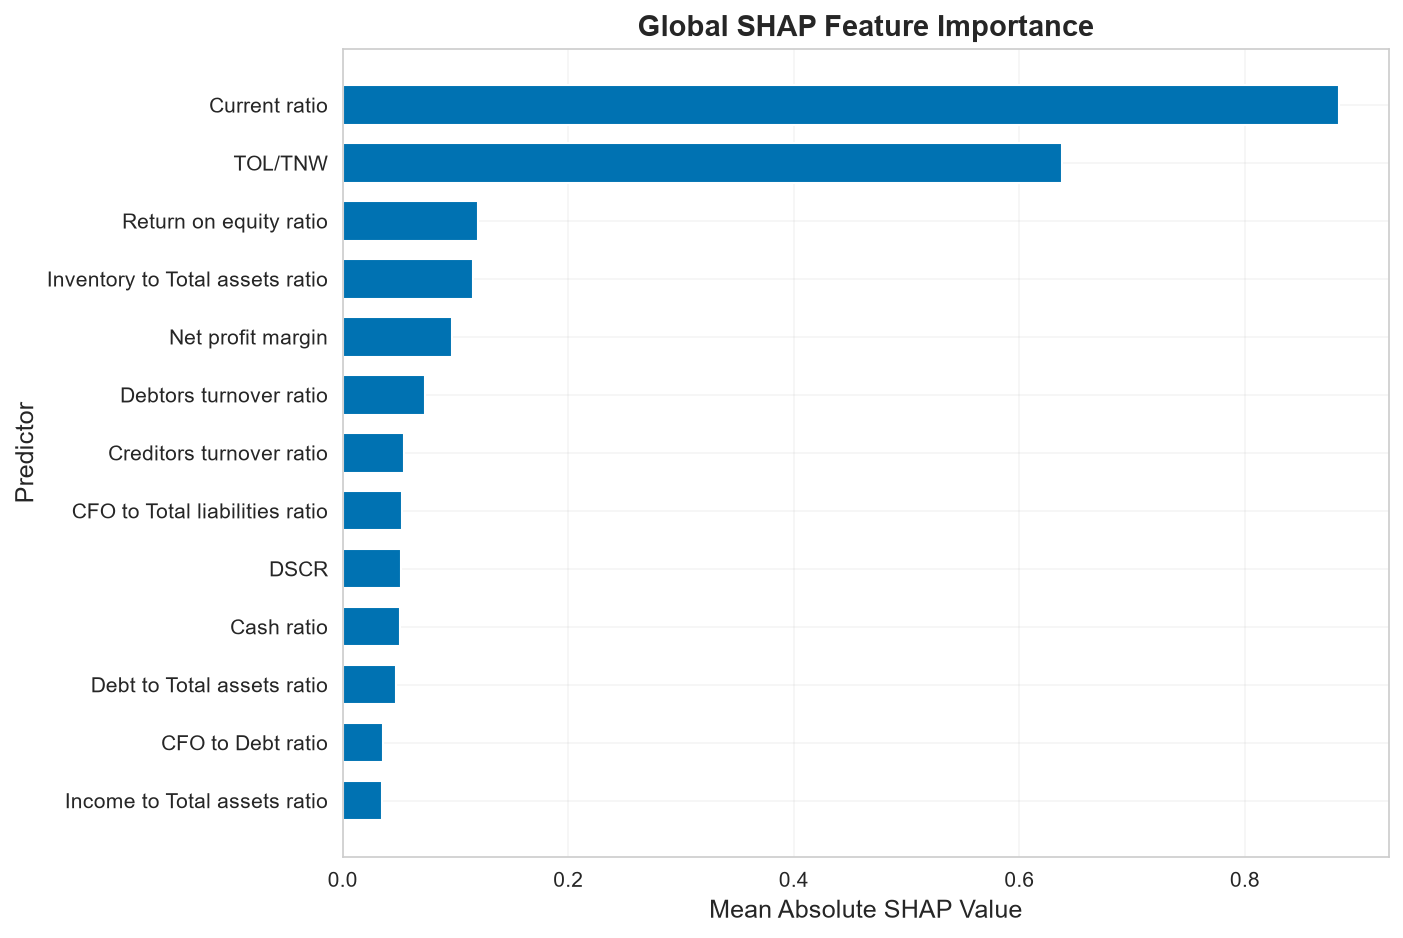

Saved: Figure_10_SHAP_Global_Importance

Row-level SHAP values CSV not found. Beeswarm and dependence plots need the saved SHAP matrix.

Potential OOT feature file:
C:\Users\iamku\Table_7_Top_10_SHAP_Features.csv


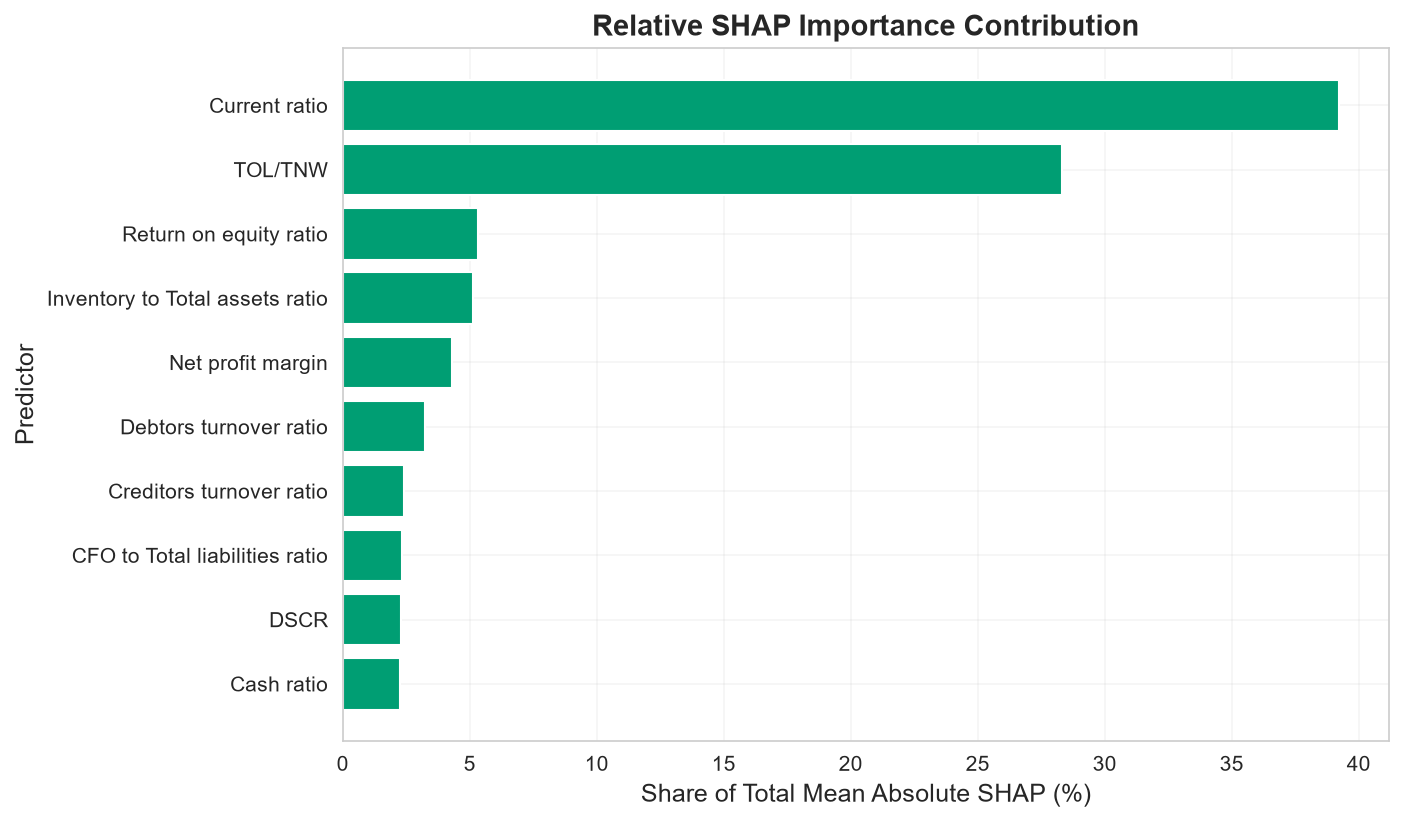

Saved: Figure_13_SHAP_Contribution


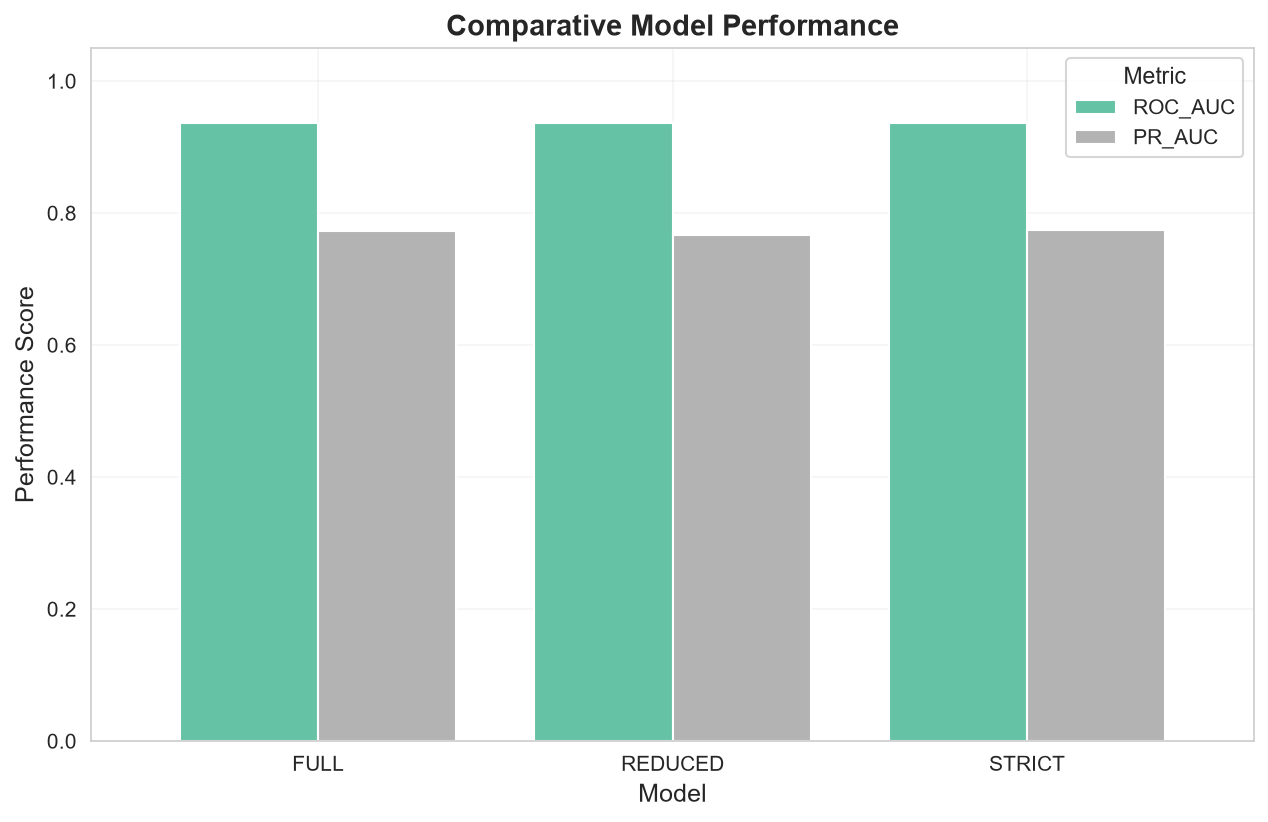

Saved: Figure_14_Comparative_Performance

FIGURE GENERATION SUMMARY
Total files: 24
Output folder: C:\Users\iamku\Research_Figures
ZIP file: C:\Users\iamku\Complete_Financial_Distress_Figures.zip

Download complete figure collection:


C:\Users\iamku\Complete_Financial_Distress_Figures.zip


Available PNG figures:


C:\Users\iamku\Research_Figures\Figure_01_Annual_Distress_Prevalence.png

C:\Users\iamku\Research_Figures\Figure_02_Temporal_Data_Partitioning.png

C:\Users\iamku\Research_Figures\Figure_03_OOT_Model_Performance.png

... (5 outputs left out)

C:\Users\iamku\Research_Figures\Figure_09_Distress_Transitions.png

C:\Users\iamku\Research_Figures\Figure_10_SHAP_Global_Importance.png

C:\Users\iamku\Research_Figures\Figure_13_SHAP_Contribution.png

C:\Users\iamku\Research_Figures\Figure_14_Comparative_Performance.png

In [9]:
# ================================================================
# COMPLETE FINANCIAL DISTRESS FIGURE GENERATION
# ================================================================

import os
import glob
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, FileLink
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

# ================================================================
# 1. PATHS
# ================================================================

BASE_DIR = os.getcwd()

OUTPUT_DIR = os.path.join(
    BASE_DIR, "Research_Figures"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Working directory:", BASE_DIR)
print("Output directory:", OUTPUT_DIR)


# ================================================================
# 2. VISUAL SETTINGS
# ================================================================

COLORS = {
    "FULL": "#0072B2",
    "REDUCED": "#E69F00",
    "STRICT": "#009E73",
    "ALTMAN": "#D55E00",
    "PERSISTENCE": "#7E57C2",
    "BLUE": "#0072B2",
    "ORANGE": "#E69F00",
    "GREEN": "#009E73",
    "RED": "#D55E00",
    "PURPLE": "#7E57C2"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.figsize": (9, 6),
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.20
})

sns.set_style("whitegrid")

generated_files = []


# ================================================================
# 3. SAVE FUNCTION
# ================================================================

def save_fig(fig, name):

    png = os.path.join(
        OUTPUT_DIR, name + ".png"
    )

    tiff = os.path.join(
        OUTPUT_DIR, name + ".tiff"
    )

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        tiff,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    generated_files.extend([png, tiff])

    plt.show()
    plt.close(fig)

    print("Saved:", name)


# ================================================================
# 4. FIND EXISTING FILES
# ================================================================

def find_file(patterns):

    for pattern in patterns:

        matches = glob.glob(
            os.path.join(BASE_DIR, pattern)
        )

        if matches:
            return matches[0]

    return None


# ================================================================
# 5. FIGURE 1 — ANNUAL DISTRESS PREVALENCE
# ================================================================

years = np.arange(2017, 2027)

rates = np.array([
    24.14, 21.78, 20.33, 22.14, 16.88,
    13.61, 13.07, 14.88, 13.43, 13.97
])

fig, ax = plt.subplots(figsize=(10, 5.8))

ax.plot(
    years,
    rates,
    marker="o",
    markersize=8,
    linewidth=2.8,
    color=COLORS["BLUE"]
)

ax.fill_between(
    years,
    rates,
    alpha=0.10,
    color=COLORS["BLUE"]
)

for x, y in zip(years, rates):

    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Annual Financial Distress Prevalence")
ax.set_xlabel("Target Year")
ax.set_ylabel("Distress Rate (%)")
ax.set_xticks(years)

save_fig(fig, "Figure_01_Annual_Distress_Prevalence")


# ================================================================
# 6. FIGURE 2 — TEMPORAL DATA PARTITIONING
# ================================================================

periods = [
    ("Training", 2016, 2020, 2755),
    ("Validation", 2021, 2022, 1102),
    ("Testing", 2023, 2024, 1102),
    ("Final OOT", 2025, 2025, 551)
]

fig, ax = plt.subplots(figsize=(10, 5.5))

period_colors = [
    COLORS["FULL"],
    COLORS["REDUCED"],
    COLORS["STRICT"],
    COLORS["ALTMAN"]
]

for i, (label, start, end, n) in enumerate(periods):

    width = end - start + 1

    ax.barh(
        i,
        width,
        left=start,
        height=0.55,
        color=period_colors[i]
    )

    ax.text(
        start + width / 2,
        i,
        f"{start}–{end}\nN = {n:,}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

ax.set_yticks(range(len(periods)))
ax.set_yticklabels([p[0] for p in periods])
ax.invert_yaxis()

ax.set_xlabel("Predictor Year")
ax.set_title("Temporal Data Partitioning")

save_fig(fig, "Figure_02_Temporal_Data_Partitioning")


# ================================================================
# 7. LOAD OOT PREDICTIONS
# ================================================================

prediction_file = find_file([
    "LIGHTGBM_FINAL_OOT_PREDICTIONS.csv"
])

if prediction_file:

    oot = pd.read_csv(prediction_file)

    print("\nOOT prediction dataset:")
    print(oot.shape)
    print(oot.columns.tolist())

else:

    oot = None

    print(
        "\nOOT prediction file not found. "
        "Prediction-dependent figures will be skipped."
    )


# ================================================================
# 8. COLUMN IDENTIFICATION
# ================================================================

def identify_column(df, candidates):

    if df is None:
        return None

    lookup = {
        str(c).lower().replace(" ", "_"): c
        for c in df.columns
    }

    for candidate in candidates:

        key = candidate.lower().replace(" ", "_")

        if key in lookup:
            return lookup[key]

    return None


target_col = identify_column(
    oot,
    [
        "Target_Distress",
        "Actual",
        "Actual_Distress",
        "y_true",
        "target"
    ]
)

probability_columns = {}

for model in ["FULL", "REDUCED", "STRICT", "ALTMAN"]:

    probability_columns[model] = identify_column(
        oot,
        [
            f"{model}_Probability",
            f"{model}_Prob",
            f"{model}_Predicted_Probability",
            f"{model}_Probability_Distress"
        ]
    )


# ================================================================
# 9. VALIDATE PROBABILITY COLUMNS
# ================================================================

valid_models = {}

if oot is not None and target_col is not None:

    y_all = pd.to_numeric(
        oot[target_col],
        errors="coerce"
    )

    for model, column in probability_columns.items():

        if column is None:
            continue

        p = pd.to_numeric(
            oot[column],
            errors="coerce"
        )

        if p.notna().any() and p.dropna().between(0, 1).all():

            valid_models[model] = p

print("\nAvailable probability models:")
print(list(valid_models.keys()))


# ================================================================
# 10. FIGURE 3 — MODEL PERFORMANCE COMPARISON
# ================================================================

performance_file = find_file([
    "LIGHTGBM_FINAL_OOT_PERFORMANCE.csv",
    "OOT_ORIGINAL_MODEL_PERFORMANCE.csv"
])

if performance_file:

    performance = pd.read_csv(performance_file)

    print("\nPerformance table columns:")
    print(performance.columns.tolist())

    model_col = identify_column(
        performance,
        ["Model", "Specification", "Model_Name"]
    )

    metric_names = [
        "ROC_AUC",
        "PR_AUC",
        "F1",
        "MCC"
    ]

    available_metrics = [
        c for c in metric_names
        if c in performance.columns
    ]

    if model_col and len(available_metrics) >= 2:

        plot_df = performance.copy()

        for c in available_metrics:
            plot_df[c] = pd.to_numeric(
                plot_df[c],
                errors="coerce"
            )

        fig, ax = plt.subplots(figsize=(10, 6))

        x = np.arange(len(plot_df))
        width = 0.19

        for i, metric in enumerate(available_metrics):

            ax.bar(
                x + (i - (len(available_metrics)-1)/2) * width,
                plot_df[metric],
                width,
                label=metric.replace("_", "-")
            )

        ax.set_xticks(x)
        ax.set_xticklabels(
            plot_df[model_col].astype(str),
            rotation=0
        )

        ax.set_ylim(0, 1.05)
        ax.set_ylabel("Performance Score")
        ax.set_title("Out-of-Time Model Performance Comparison")
        ax.legend(frameon=True, loc="best")

        save_fig(
            fig,
            "Figure_03_OOT_Model_Performance"
        )

    else:
        print("Figure 3 skipped: model or metric columns not identified.")

else:
    print("Performance CSV not found.")


# ================================================================
# 11. FIGURE 4 — ROC CURVES
# ================================================================

if valid_models:

    fig, ax = plt.subplots(figsize=(8.5, 7))

    for model, probability in valid_models.items():

        data = pd.DataFrame({
            "actual": y_all,
            "probability": probability
        }).dropna()

        fpr, tpr, _ = roc_curve(
            data["actual"].astype(int),
            data["probability"]
        )

        score = auc(fpr, tpr)

        ax.plot(
            fpr,
            tpr,
            linewidth=2.5,
            color=COLORS.get(model, COLORS["BLUE"]),
            label=f"{model.title()} (AUC = {score:.4f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="#888888",
        linewidth=1.5,
        label="Random classifier"
    )

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("Out-of-Time ROC Curves")
    ax.legend(loc="lower right", frameon=True)

    save_fig(fig, "Figure_04_OOT_ROC_Curves")


# ================================================================
# 12. FIGURE 5 — PRECISION-RECALL CURVES
# ================================================================

if valid_models:

    fig, ax = plt.subplots(figsize=(8.5, 7))

    for model, probability in valid_models.items():

        data = pd.DataFrame({
            "actual": y_all,
            "probability": probability
        }).dropna()

        precision, recall, _ = precision_recall_curve(
            data["actual"].astype(int),
            data["probability"]
        )

        ap = average_precision_score(
            data["actual"].astype(int),
            data["probability"]
        )

        ax.plot(
            recall,
            precision,
            linewidth=2.5,
            color=COLORS.get(model, COLORS["BLUE"]),
            label=f"{model.title()} (AP = {ap:.4f})"
        )

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("Out-of-Time Precision–Recall Curves")
    ax.legend(loc="best")

    save_fig(fig, "Figure_05_OOT_Precision_Recall")


# ================================================================
# 13. FIGURE 6 — CONFUSION MATRICES
# ================================================================

if valid_models:

    model_names = list(valid_models.keys())

    fig, axes = plt.subplots(
        1,
        len(model_names),
        figsize=(5 * len(model_names), 4.5)
    )

    if len(model_names) == 1:
        axes = [axes]

    for ax, model in zip(axes, model_names):

        data = pd.DataFrame({
            "actual": y_all,
            "probability": valid_models[model]
        }).dropna()

        pred = (
            data["probability"] >= 0.50
        ).astype(int)

        cm = confusion_matrix(
            data["actual"].astype(int),
            pred
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            square=True,
            xticklabels=["Non-distress", "Distress"],
            yticklabels=["Non-distress", "Distress"],
            ax=ax
        )

        ax.set_title(model.title())
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    fig.suptitle(
        "Out-of-Time Confusion Matrices (Threshold = 0.50)",
        fontsize=14,
        fontweight="bold"
    )

    fig.tight_layout()

    save_fig(fig, "Figure_06_Confusion_Matrices")


# ================================================================
# 14. FIGURE 7 — CALIBRATION CURVES
# ================================================================

if valid_models:

    fig, ax = plt.subplots(figsize=(8, 7))

    for model, probability in valid_models.items():

        data = pd.DataFrame({
            "actual": y_all,
            "probability": probability
        }).dropna()

        fraction_positive, mean_predicted = calibration_curve(
            data["actual"].astype(int),
            data["probability"],
            n_bins=10,
            strategy="quantile"
        )

        ax.plot(
            mean_predicted,
            fraction_positive,
            marker="o",
            linewidth=2.2,
            markersize=6,
            color=COLORS.get(model, COLORS["BLUE"]),
            label=model.title()
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="black",
        label="Perfect calibration"
    )

    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Observed Distress Frequency")
    ax.set_title("Out-of-Time Probability Calibration")
    ax.legend()

    save_fig(fig, "Figure_07_Calibration_Curves")


# ================================================================
# 15. FIGURE 8 — BRIER SCORE AND LOG-LOSS
# ================================================================

if performance_file:

    performance = pd.read_csv(performance_file)

    model_col = identify_column(
        performance,
        ["Model", "Specification", "Model_Name"]
    )

    brier_col = identify_column(
        performance,
        ["Brier_Score", "Brier"]
    )

    logloss_col = identify_column(
        performance,
        ["Log_Loss", "LogLoss"]
    )

    if model_col and (brier_col or logloss_col):

        metrics = [
            c for c in [brier_col, logloss_col]
            if c is not None
        ]

        fig, axes = plt.subplots(
            1,
            len(metrics),
            figsize=(5 * len(metrics), 5)
        )

        if len(metrics) == 1:
            axes = [axes]

        for ax, metric in zip(axes, metrics):

            temp = performance.copy()

            temp[metric] = pd.to_numeric(
                temp[metric],
                errors="coerce"
            )

            ax.bar(
                temp[model_col].astype(str),
                temp[metric],
                color=COLORS["BLUE"],
                width=0.65
            )

            ax.set_title(metric.replace("_", " "))
            ax.set_ylabel("Error")
            ax.tick_params(axis="x", rotation=25)

        fig.suptitle("Probability Prediction Error Comparison")
        fig.tight_layout()

        save_fig(fig, "Figure_08_Probability_Error")


# ================================================================
# 16. FIGURE 9 — DISTRESS TRANSITIONS
# ================================================================

transition_labels = [
    "Non-distress",
    "New distress",
    "Recovered",
    "Persistent distress"
]

transition_counts = [455, 22, 19, 55]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    transition_labels,
    transition_counts,
    color=[
        COLORS["FULL"],
        COLORS["ALTMAN"],
        COLORS["REDUCED"],
        COLORS["STRICT"]
    ],
    width=0.65
)

for bar in bars:

    height = bar.get_height()

    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width()/2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_ylabel("Number of Companies")
ax.set_title("Out-of-Time Financial Distress Transitions")
ax.tick_params(axis="x", rotation=15)

save_fig(fig, "Figure_09_Distress_Transitions")


# ================================================================
# 17. FIND SHAP IMPORTANCE FILE
# ================================================================

shap_importance_file = find_file([
    "*SHAP*IMPORTANCE*.csv",
    "*GLOBAL*SHAP*.csv",
    "*SHAP*GLOBAL*.csv"
])

shap_importance = None

if shap_importance_file:

    shap_importance = pd.read_csv(
        shap_importance_file
    )

    print("\nSHAP importance file:")
    print(shap_importance_file)
    print(shap_importance.columns.tolist())


# ================================================================
# 18. FIGURE 10 — SHAP GLOBAL IMPORTANCE
# ================================================================

if shap_importance is not None:

    feature_col = identify_column(
        shap_importance,
        ["Feature", "Variable", "Feature_Name"]
    )

    importance_col = identify_column(
        shap_importance,
        [
            "Mean_Absolute_SHAP",
            "MeanAbsSHAP",
            "Mean_Abs_SHAP"
        ]
    )

    if feature_col and importance_col:

        shap_importance[importance_col] = pd.to_numeric(
            shap_importance[importance_col],
            errors="coerce"
        )

        plot_data = (
            shap_importance
            .dropna(subset=[importance_col])
            .sort_values(importance_col, ascending=True)
            .tail(15)
        )

        fig, ax = plt.subplots(figsize=(9, 7))

        ax.barh(
            plot_data[feature_col],
            plot_data[importance_col],
            color=COLORS["BLUE"],
            height=0.68
        )

        ax.set_xlabel("Mean Absolute SHAP Value")
        ax.set_ylabel("Predictor")
        ax.set_title("Global SHAP Feature Importance")

        save_fig(fig, "Figure_10_SHAP_Global_Importance")

    else:

        print("SHAP importance columns not identified.")


# ================================================================
# 19. SHAP ROW-LEVEL DATA DISCOVERY
# ================================================================

# Beeswarm and dependence plots require:
# 1. Row-level SHAP values
# 2. Corresponding feature values
#
# A summary importance table is not sufficient.

shap_value_candidates = [
    "*SHAP*VALUES*.csv",
    "*SHAP*VALUE*.csv",
    "*SHAP_MATRIX*.csv"
]

shap_value_file = find_file(shap_value_candidates)

feature_value_candidates = [
    "*OOT*FEATURES*.csv",
    "*SHAP*FEATURES*.csv",
    "*X_OOT*.csv",
    "*FINAL*OOT*X*.csv"
]

feature_value_file = find_file(feature_value_candidates)

if shap_value_file:

    print("\nPotential row-level SHAP file:")
    print(shap_value_file)

else:

    print(
        "\nRow-level SHAP values CSV not found. "
        "Beeswarm and dependence plots need the saved SHAP matrix."
    )

if feature_value_file:

    print("\nPotential OOT feature file:")
    print(feature_value_file)

else:

    print(
        "\nMatching OOT feature matrix not found. "
        "Dependence plots need the corresponding feature values."
    )


# ================================================================
# 20. FIGURE 11 — SHAP BEESWARM
# ================================================================

# This figure is generated only when a matching SHAP matrix
# and feature matrix are supplied.

if shap_value_file and feature_value_file:

    import shap

    shap_values_df = pd.read_csv(shap_value_file)
    feature_values_df = pd.read_csv(feature_value_file)

    # Align columns by common feature names.
    common_features = [
        c for c in shap_values_df.columns
        if c in feature_values_df.columns
    ]

    if len(common_features) > 0:

        shap_matrix = shap_values_df[common_features]
        feature_matrix = feature_values_df[common_features]

        shap_matrix = shap_matrix.apply(
            pd.to_numeric,
            errors="coerce"
        )

        feature_matrix = feature_matrix.apply(
            pd.to_numeric,
            errors="coerce"
        )

        valid_rows = (
            shap_matrix.notna().all(axis=1)
            & feature_matrix.notna().all(axis=1)
        )

        shap_matrix = shap_matrix.loc[valid_rows]
        feature_matrix = feature_matrix.loc[valid_rows]

        if len(shap_matrix) > 0:

            plt.figure(figsize=(10, 8))

            shap.summary_plot(
                shap_matrix.to_numpy(),
                feature_matrix,
                feature_names=common_features,
                max_display=15,
                show=False,
                plot_size=(10, 8)
            )

            fig = plt.gcf()

            fig.suptitle(
                "SHAP Summary (Beeswarm)",
                fontsize=14,
                fontweight="bold",
                y=1.02
            )

            save_fig(fig, "Figure_11_SHAP_Beeswarm")

        else:

            print("No complete matching SHAP rows available.")

    else:

        print("No matching feature columns between the two files.")


# ================================================================
# 21. FIGURE 12 — SHAP DEPENDENCE PLOTS
# ================================================================

if shap_value_file and feature_value_file:

    if len(common_features) > 0 and len(shap_matrix) > 0:

        mean_abs = (
            shap_matrix.abs()
            .mean()
            .sort_values(ascending=False)
        )

        top_features = mean_abs.head(5).index.tolist()

        for rank, feature in enumerate(top_features, start=1):

            fig, ax = plt.subplots(figsize=(8, 6))

            ax.scatter(
                feature_matrix[feature],
                shap_matrix[feature],
                alpha=0.65,
                s=24,
                color=COLORS["BLUE"],
                edgecolors="none"
            )

            ax.axhline(
                0,
                linestyle="--",
                color="grey",
                linewidth=1
            )

            ax.set_xlabel(feature)
            ax.set_ylabel("SHAP Value")
            ax.set_title(
                f"SHAP Dependence: {feature}"
            )

            save_fig(
                fig,
                f"Figure_12_SHAP_Dependence_{rank}"
            )


# ================================================================
# 22. FIGURE 13 — SHAP IMPORTANCE CONTRIBUTION
# ================================================================

if shap_importance is not None and feature_col and importance_col:

    temp = (
        shap_importance
        .dropna(subset=[importance_col])
        .sort_values(importance_col, ascending=False)
        .head(10)
        .copy()
    )

    temp["Contribution_Percent"] = (
        temp[importance_col]
        / shap_importance[importance_col].sum()
        * 100
    )

    fig, ax = plt.subplots(figsize=(9, 6))

    ax.barh(
        temp[feature_col][::-1],
        temp["Contribution_Percent"][::-1],
        color=COLORS["GREEN"]
    )

    ax.set_xlabel("Share of Total Mean Absolute SHAP (%)")
    ax.set_ylabel("Predictor")
    ax.set_title("Relative SHAP Importance Contribution")

    save_fig(fig, "Figure_13_SHAP_Contribution")


# ================================================================
# 23. FIGURE 14 — MODEL PERFORMANCE RADAR ALTERNATIVE
# ================================================================

# A grouped bar chart is generally easier to interpret than
# a radar chart. This figure uses the performance CSV if available.

if performance_file:

    performance = pd.read_csv(performance_file)

    model_col = identify_column(
        performance,
        ["Model", "Specification", "Model_Name"]
    )

    radar_metrics = [
        "ROC_AUC",
        "PR_AUC",
        "F1",
        "MCC"
    ]

    available = [
        c for c in radar_metrics
        if c in performance.columns
    ]

    if model_col and len(available) >= 2:

        temp = performance[
            [model_col] + available
        ].copy()

        temp = temp.set_index(model_col)

        temp = temp.apply(
            pd.to_numeric,
            errors="coerce"
        )

        fig, ax = plt.subplots(figsize=(10, 6))

        temp.plot(
            kind="bar",
            ax=ax,
            width=0.78,
            colormap="Set2"
        )

        ax.set_title("Comparative Model Performance")
        ax.set_ylabel("Performance Score")
        ax.set_xlabel("Model")
        ax.set_ylim(0, 1.05)
        ax.legend(title="Metric")
        ax.tick_params(axis="x", rotation=0)

        save_fig(fig, "Figure_14_Comparative_Performance")


# ================================================================
# 24. FIGURE INDEX
# ================================================================

index_df = pd.DataFrame({
    "Filename": [
        os.path.basename(f)
        for f in generated_files
    ],
    "File_Path": generated_files
})

index_path = os.path.join(
    OUTPUT_DIR,
    "Figure_Index.csv"
)

index_df.to_csv(
    index_path,
    index=False
)


# ================================================================
# 25. CREATE DOWNLOADABLE ZIP
# ================================================================

zip_path = os.path.join(
    BASE_DIR,
    "Complete_Financial_Distress_Figures.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for file in generated_files:

        if os.path.exists(file):

            archive.write(
                file,
                arcname=os.path.join(
                    "Research_Figures",
                    os.path.basename(file)
                )
            )

    archive.write(
        index_path,
        arcname="Research_Figures/Figure_Index.csv"
    )


# ================================================================
# 26. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 65)
print("FIGURE GENERATION SUMMARY")
print("=" * 65)

print("Total files:", len(generated_files))
print("Output folder:", OUTPUT_DIR)
print("ZIP file:", zip_path)

print("\nDownload complete figure collection:")
display(FileLink(zip_path))

print("\nAvailable PNG figures:")

for file in generated_files:

    if file.endswith(".png"):
        display(FileLink(file))

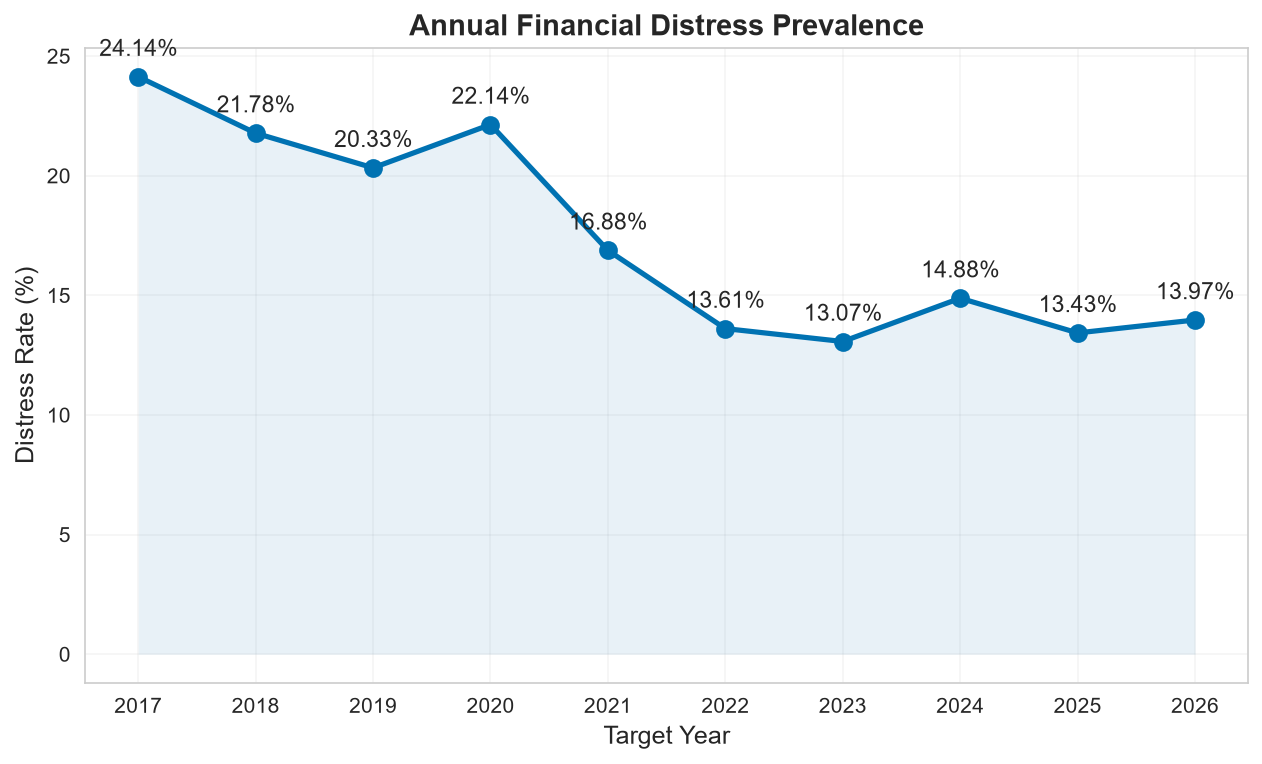

Created: Figure_01_Annual_Distress_Prevalence


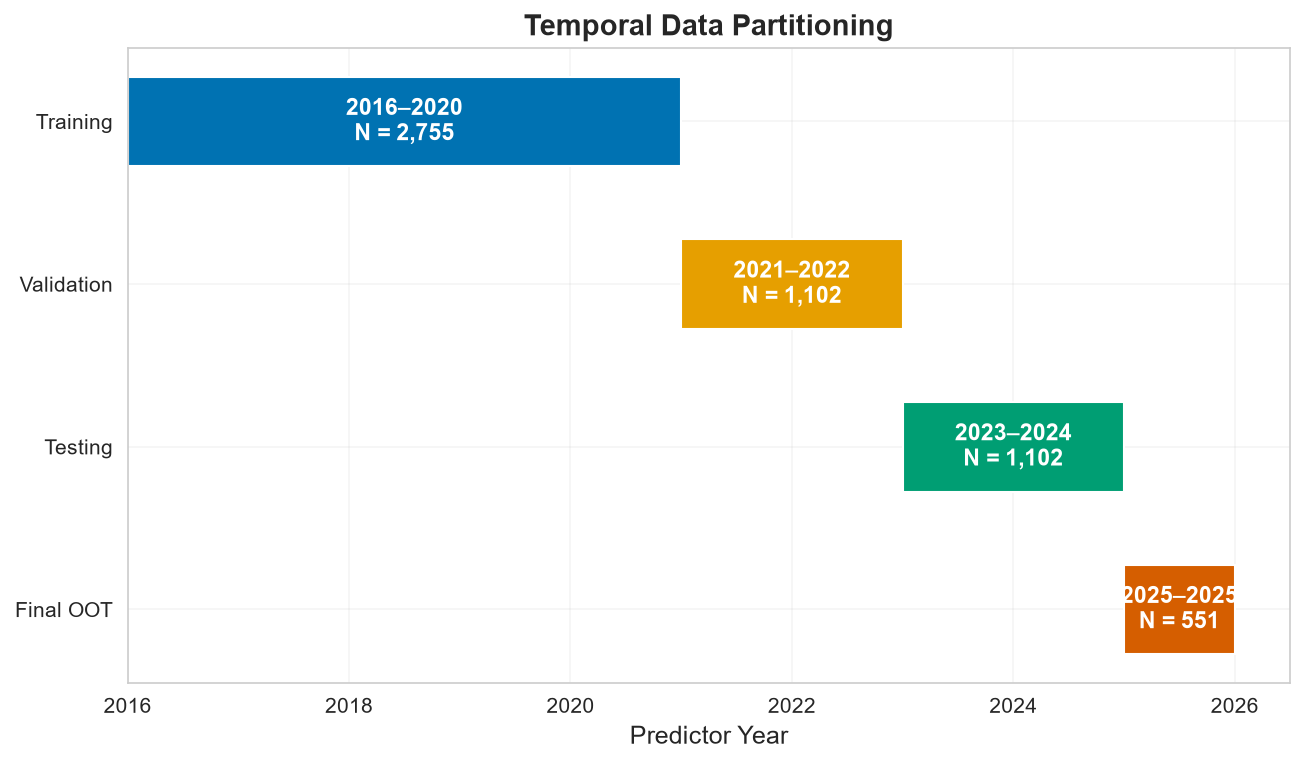

Created: Figure_02_Temporal_Data_Partition
OOT predictions not found. Prediction-based figures skipped.

NEW FIGURE GENERATION COMPLETED
Output folder: C:\Users\iamku\Documents\Financial_Distress_Research\Research_Figures
Figures are saved in PNG and TIFF formats at 300 DPI.


In [12]:
def find_csv(patterns):
    for pattern in patterns:
        files = glob.glob(os.path.join(BASE_DIR, pattern))
        if files:
            return files[0]
    return None


def load_csv(patterns):
    path = find_csv(patterns)
    if path:
        print("Loaded:", os.path.basename(path))
        return pd.read_csv(path)
    return None


# ---------------------------------------------------------
# FIGURE 1: ANNUAL DISTRESS PREVALENCE
# ---------------------------------------------------------

years = np.arange(2017, 2027)

distress_rates = [
    24.14, 21.78, 20.33, 22.14, 16.88,
    13.61, 13.07, 14.88, 13.43, 13.97
]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    years, distress_rates,
    marker="o", markersize=8,
    linewidth=2.5, color=COLORS["FULL"]
)

ax.fill_between(years, distress_rates, alpha=0.10)

for x, y in zip(years, distress_rates):
    ax.annotate(
        f"{y:.2f}%",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Annual Financial Distress Prevalence")
ax.set_xlabel("Target Year")
ax.set_ylabel("Distress Rate (%)")
ax.set_xticks(years)

save_figure(fig, "Figure_01_Annual_Distress_Prevalence")


# ---------------------------------------------------------
# FIGURE 2: TEMPORAL DATA PARTITION
# ---------------------------------------------------------

periods = [
    ("Training", 2016, 2020, 2755),
    ("Validation", 2021, 2022, 1102),
    ("Testing", 2023, 2024, 1102),
    ("Final OOT", 2025, 2025, 551)
]

fig, ax = plt.subplots(figsize=(10, 5.5))

period_colors = [
    COLORS["FULL"],
    COLORS["REDUCED"],
    COLORS["STRICT"],
    COLORS["ALTMAN"]
]

for i, (name, start, end, n) in enumerate(periods):
    width = end - start + 1

    ax.barh(
        i, width,
        left=start,
        height=0.55,
        color=period_colors[i]
    )

    ax.text(
        start + width / 2,
        i,
        f"{start}–{end}\nN = {n:,}",
        ha="center",
        va="center",
        color="white",
        fontweight="bold"
    )

ax.set_yticks(range(len(periods)))
ax.set_yticklabels([p[0] for p in periods])
ax.invert_yaxis()
ax.set_xlabel("Predictor Year")
ax.set_title("Temporal Data Partitioning")

save_figure(fig, "Figure_02_Temporal_Data_Partition")


# ---------------------------------------------------------
# LOAD OOT PREDICTIONS
# ---------------------------------------------------------

oot = load_csv([
    "LIGHTGBM_FINAL_OOT_PREDICTIONS.csv",
    "*FINAL*OOT*PREDICTIONS*.csv"
])

if oot is not None:

    target_candidates = [
        "Target_Distress", "Actual",
        "Actual_Distress", "y_true", "target"
    ]

    target_col = next(
        (c for c in target_candidates if c in oot.columns),
        None
    )

    probability_columns = {}

    for model in ["FULL", "REDUCED", "STRICT", "ALTMAN"]:
        candidates = [
            f"{model}_Probability",
            f"{model}_Prob",
            f"{model}_Predicted_Probability",
            f"{model}_Probability_Distress"
        ]

        probability_columns[model] = next(
            (c for c in candidates if c in oot.columns),
            None
        )

    if target_col is not None:

        y_true = pd.to_numeric(
            oot[target_col], errors="coerce"
        )

        valid_models = {}

        for model, col in probability_columns.items():
            if col is not None:
                probabilities = pd.to_numeric(
                    oot[col], errors="coerce"
                )

                valid = y_true.notna() & probabilities.notna()

                if valid.any():
                    valid_models[model] = (
                        y_true[valid].astype(int),
                        probabilities[valid]
                    )

        print("Available prediction models:", list(valid_models))


        # -------------------------------------------------
        # FIGURE 3: ROC CURVES
        # -------------------------------------------------

        if valid_models:

            fig, ax = plt.subplots(figsize=(8, 7))

            for model, (actual, probability) in valid_models.items():

                fpr, tpr, _ = roc_curve(actual, probability)
                roc_auc = auc(fpr, tpr)

                ax.plot(
                    fpr, tpr,
                    linewidth=2.5,
                    color=COLORS.get(model),
                    label=f"{model}: AUC = {roc_auc:.4f}"
                )

            ax.plot(
                [0, 1], [0, 1],
                linestyle="--",
                color="grey",
                label="Random classifier"
            )

            ax.set_xlabel("False Positive Rate")
            ax.set_ylabel("True Positive Rate")
            ax.set_title("Out-of-Time ROC Curves")
            ax.legend(loc="lower right")

            save_figure(fig, "Figure_03_OOT_ROC_Curves")


        # -------------------------------------------------
        # FIGURE 4: PRECISION-RECALL CURVES
        # -------------------------------------------------

        if valid_models:

            fig, ax = plt.subplots(figsize=(8, 7))

            for model, (actual, probability) in valid_models.items():

                precision, recall, _ = precision_recall_curve(
                    actual, probability
                )

                ap = average_precision_score(
                    actual, probability
                )

                ax.plot(
                    recall, precision,
                    linewidth=2.5,
                    color=COLORS.get(model),
                    label=f"{model}: AP = {ap:.4f}"
                )

            ax.set_xlabel("Recall")
            ax.set_ylabel("Precision")
            ax.set_title("Out-of-Time Precision–Recall Curves")
            ax.legend()

            save_figure(fig, "Figure_04_OOT_Precision_Recall")


        # -------------------------------------------------
        # FIGURE 5: CONFUSION MATRICES
        # -------------------------------------------------

        if valid_models:

            model_names = list(valid_models.keys())

            fig, axes = plt.subplots(
                1, len(model_names),
                figsize=(5 * len(model_names), 4.5)
            )

            if len(model_names) == 1:
                axes = [axes]

            for ax, model in zip(axes, model_names):

                actual, probability = valid_models[model]

                predicted = (probability >= 0.50).astype(int)

                cm = confusion_matrix(
                    actual, predicted, labels=[0, 1]
                )

                sns.heatmap(
                    cm,
                    annot=True,
                    fmt="d",
                    cmap="Blues",
                    cbar=False,
                    square=True,
                    xticklabels=["Non-distress", "Distress"],
                    yticklabels=["Non-distress", "Distress"],
                    ax=ax
                )

                ax.set_title(model)
                ax.set_xlabel("Predicted")
                ax.set_ylabel("Actual")

            fig.suptitle(
                "Out-of-Time Confusion Matrices",
                fontsize=14
            )

            fig.tight_layout()

            save_figure(fig, "Figure_05_Confusion_Matrices")


        # -------------------------------------------------
        # FIGURE 6: CALIBRATION CURVES
        # -------------------------------------------------

        if valid_models:

            fig, ax = plt.subplots(figsize=(8, 7))

            for model, (actual, probability) in valid_models.items():

                observed, predicted = calibration_curve(
                    actual,
                    probability,
                    n_bins=10,
                    strategy="quantile"
                )

                ax.plot(
                    predicted,
                    observed,
                    marker="o",
                    linewidth=2.2,
                    label=model
                )

            ax.plot(
                [0, 1], [0, 1],
                linestyle="--",
                color="black",
                label="Perfect calibration"
            )

            ax.set_xlabel("Mean Predicted Probability")
            ax.set_ylabel("Observed Distress Frequency")
            ax.set_title("Out-of-Time Probability Calibration")
            ax.legend()

            save_figure(fig, "Figure_06_Calibration_Curves")

    else:
        print("Target column not found in OOT prediction file.")

else:
    print("OOT predictions not found. Prediction-based figures skipped.")


# ---------------------------------------------------------
# FIGURE 7: MODEL PERFORMANCE COMPARISON
# ---------------------------------------------------------

performance = load_csv([
    "LIGHTGBM_FINAL_OOT_PERFORMANCE.csv",
    "OOT_ORIGINAL_MODEL_PERFORMANCE.csv",
    "*OOT*PERFORMANCE*.csv"
])

if performance is not None:

    model_col = next(
        (c for c in ["Model", "Specification", "Model_Name"]
         if c in performance.columns),
        None
    )

    metrics = [
        c for c in ["ROC_AUC", "PR_AUC", "F1", "MCC"]
        if c in performance.columns
    ]

    if model_col and metrics:

        plot_df = performance.copy()

        for metric in metrics:
            plot_df[metric] = pd.to_numeric(
                plot_df[metric], errors="coerce"
            )

        ax = plot_df.set_index(model_col)[metrics].plot(
            kind="bar",
            figsize=(10, 6),
            width=0.75
        )

        ax.set_title("Out-of-Time Model Performance Comparison")
        ax.set_ylabel("Performance Score")
        ax.set_xlabel("Model")
        ax.set_ylim(0, 1.05)
        ax.legend(title="Metric")
        plt.xticks(rotation=0)
        plt.tight_layout()

        save_figure(
            plt.gcf(),
            "Figure_07_Model_Performance_Comparison"
        )


# ---------------------------------------------------------
# FIGURE 8: SHAP GLOBAL FEATURE IMPORTANCE
# ---------------------------------------------------------

shap_df = load_csv([
    "*SHAP*IMPORTANCE*.csv",
    "*GLOBAL*SHAP*.csv",
    "*SHAP*GLOBAL*.csv"
])

if shap_df is not None:

    feature_col = next(
        (c for c in ["Feature", "Variable", "Feature_Name"]
         if c in shap_df.columns),
        None
    )

    importance_col = next(
        (c for c in [
            "Mean_Absolute_SHAP",
            "MeanAbsSHAP",
            "Mean_Abs_SHAP"
        ] if c in shap_df.columns),
        None
    )

    if feature_col and importance_col:

        shap_df[importance_col] = pd.to_numeric(
            shap_df[importance_col],
            errors="coerce"
        )

        plot_df = (
            shap_df
            .dropna(subset=[importance_col])
            .nlargest(15, importance_col)
            .sort_values(importance_col)
        )

        fig, ax = plt.subplots(figsize=(9, 7))

        ax.barh(
            plot_df[feature_col],
            plot_df[importance_col],
            color=COLORS["STRICT"]
        )

        ax.set_xlabel("Mean Absolute SHAP Value")
        ax.set_ylabel("Predictor")
        ax.set_title("Global SHAP Feature Importance")

        save_figure(fig, "Figure_08_SHAP_Global_Importance")


print("\n" + "=" * 60)
print("NEW FIGURE GENERATION COMPLETED")
print("=" * 60)
print("Output folder:", OUTPUT_DIR)
print("Figures are saved in PNG and TIFF formats at 300 DPI.")

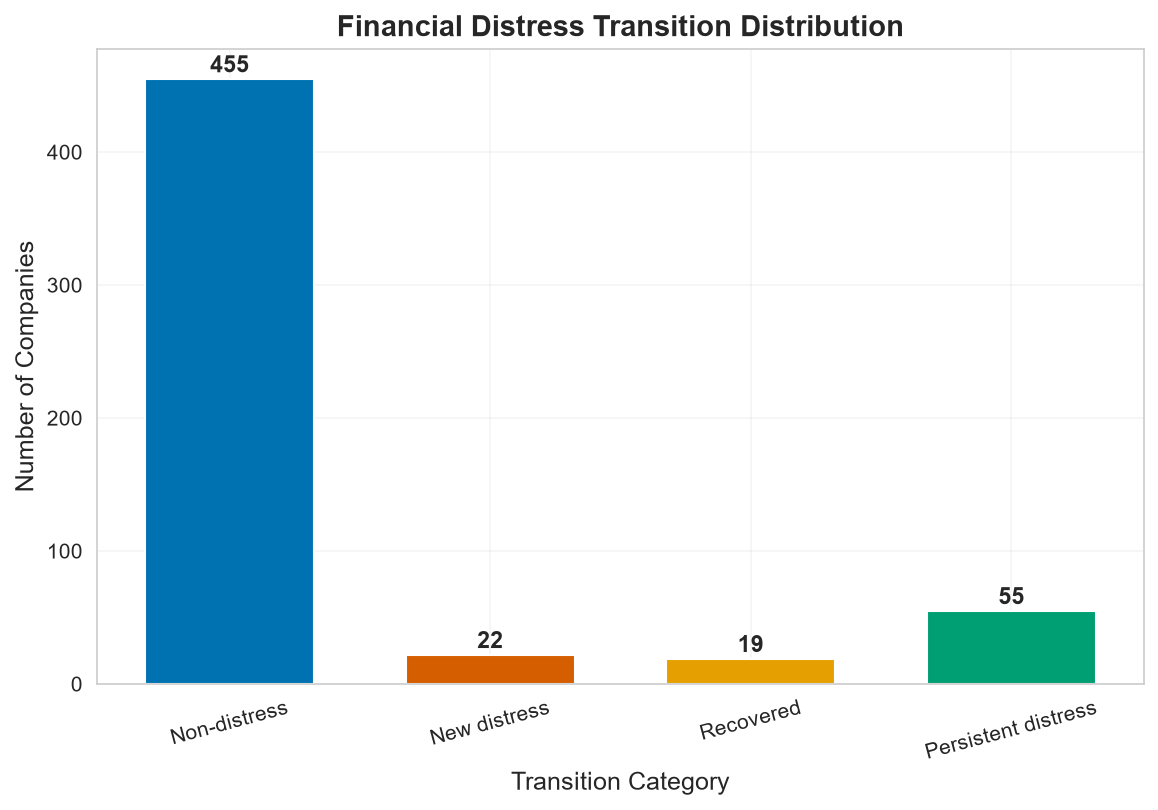

Created: Figure_09_Distress_Transition_Distribution


In [13]:
# ---------------------------------------------------------
# FIGURE 9: DISTRESS TRANSITION DISTRIBUTION
# ---------------------------------------------------------

transition_labels = [
    "Non-distress",
    "New distress",
    "Recovered",
    "Persistent distress"
]

transition_counts = [455, 22, 19, 55]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    transition_labels,
    transition_counts,
    color=[
        COLORS["FULL"],
        COLORS["ALTMAN"],
        COLORS["REDUCED"],
        COLORS["STRICT"]
    ],
    width=0.65
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        f"{int(height)}",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Financial Distress Transition Distribution")
ax.set_xlabel("Transition Category")
ax.set_ylabel("Number of Companies")
ax.tick_params(axis="x", rotation=15)

save_figure(fig, "Figure_09_Distress_Transition_Distribution")

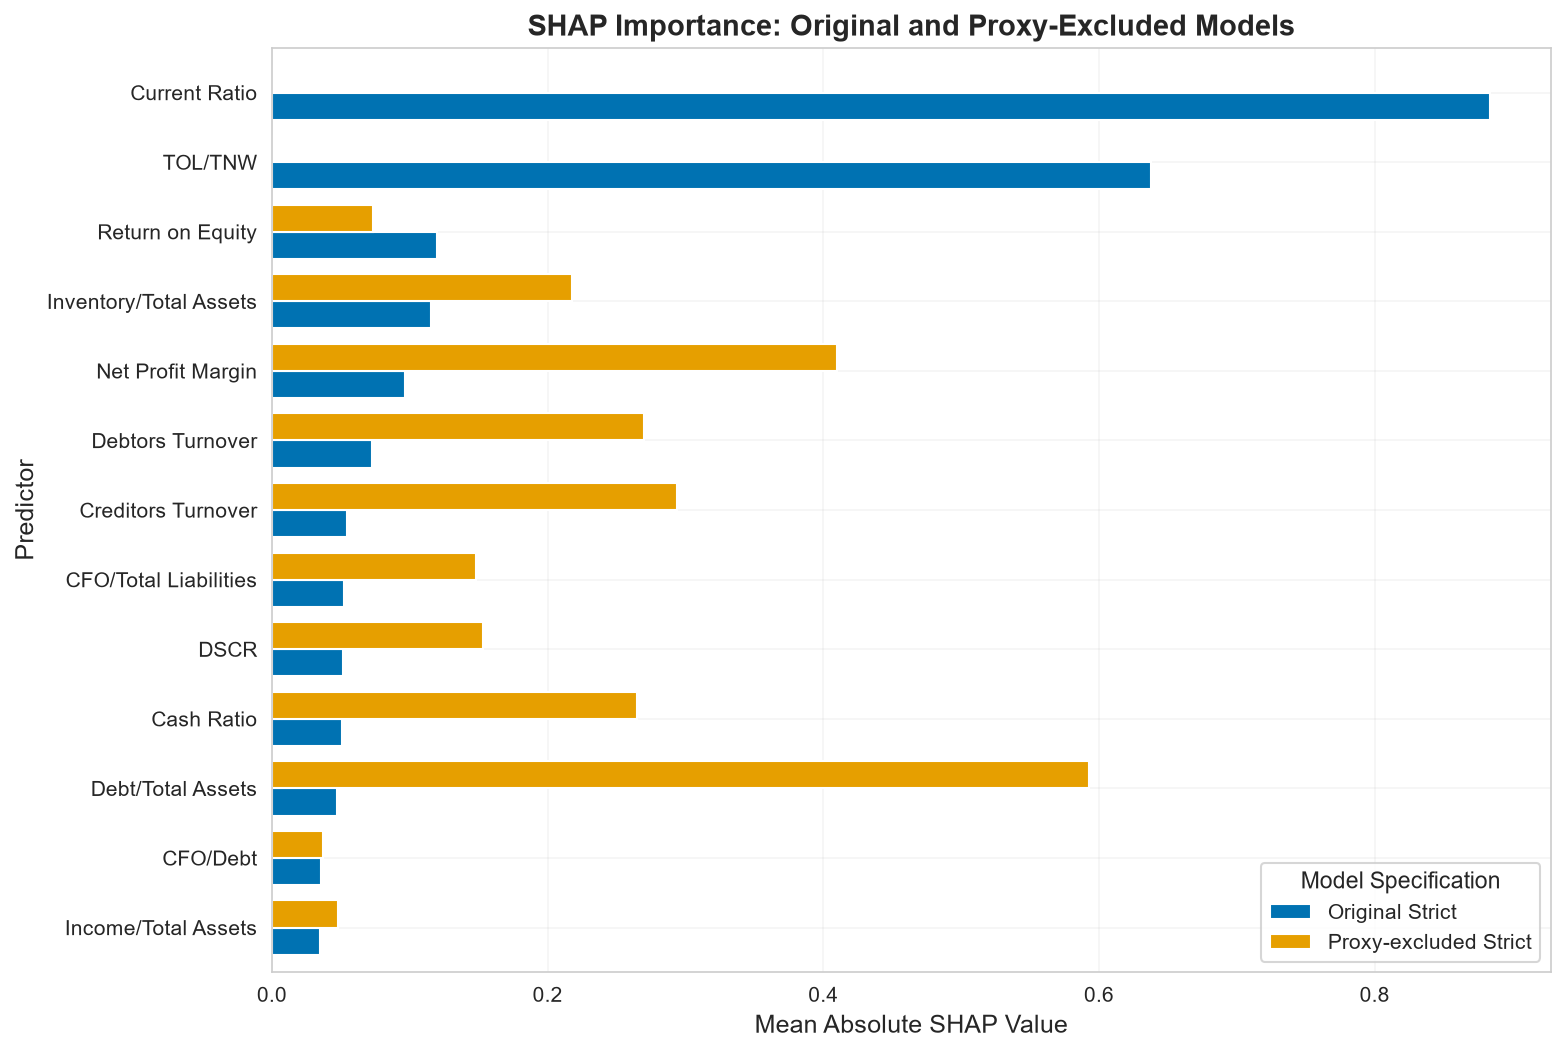

Created: Figure_10_SHAP_Original_vs_Proxy_Excluded


In [14]:
# ---------------------------------------------------------
# FIGURE 10: ORIGINAL VS PROXY-EXCLUDED SHAP
# ---------------------------------------------------------

original_shap = {
    "Current Ratio": 0.883530,
    "TOL/TNW": 0.637906,
    "Return on Equity": 0.119641,
    "Inventory/Total Assets": 0.115738,
    "Net Profit Margin": 0.096656,
    "Debtors Turnover": 0.072875,
    "Creditors Turnover": 0.054253,
    "CFO/Total Liabilities": 0.052182,
    "DSCR": 0.051577,
    "Cash Ratio": 0.050713,
    "Debt/Total Assets": 0.047030,
    "CFO/Debt": 0.035401,
    "Income/Total Assets": 0.034717
}

proxy_free_shap = {
    "Debt/Total Assets": 0.592634,
    "Net Profit Margin": 0.410073,
    "Creditors Turnover": 0.293800,
    "Debtors Turnover": 0.269859,
    "Cash Ratio": 0.264892,
    "Inventory/Total Assets": 0.217804,
    "DSCR": 0.153101,
    "CFO/Total Liabilities": 0.148132,
    "Return on Equity": 0.073131,
    "Income/Total Assets": 0.048180,
    "CFO/Debt": 0.036812
}

comparison_df = pd.DataFrame({
    "Original Strict": pd.Series(original_shap),
    "Proxy-excluded Strict": pd.Series(proxy_free_shap)
}).fillna(0)

comparison_df = comparison_df.sort_values(
    "Original Strict",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 8))

comparison_df.plot(
    kind="barh",
    ax=ax,
    width=0.78,
    color=["#0072B2", "#E69F00"]
)

ax.set_title("SHAP Importance: Original and Proxy-Excluded Models")
ax.set_xlabel("Mean Absolute SHAP Value")
ax.set_ylabel("Predictor")
ax.legend(title="Model Specification")

save_figure(fig, "Figure_10_SHAP_Original_vs_Proxy_Excluded")

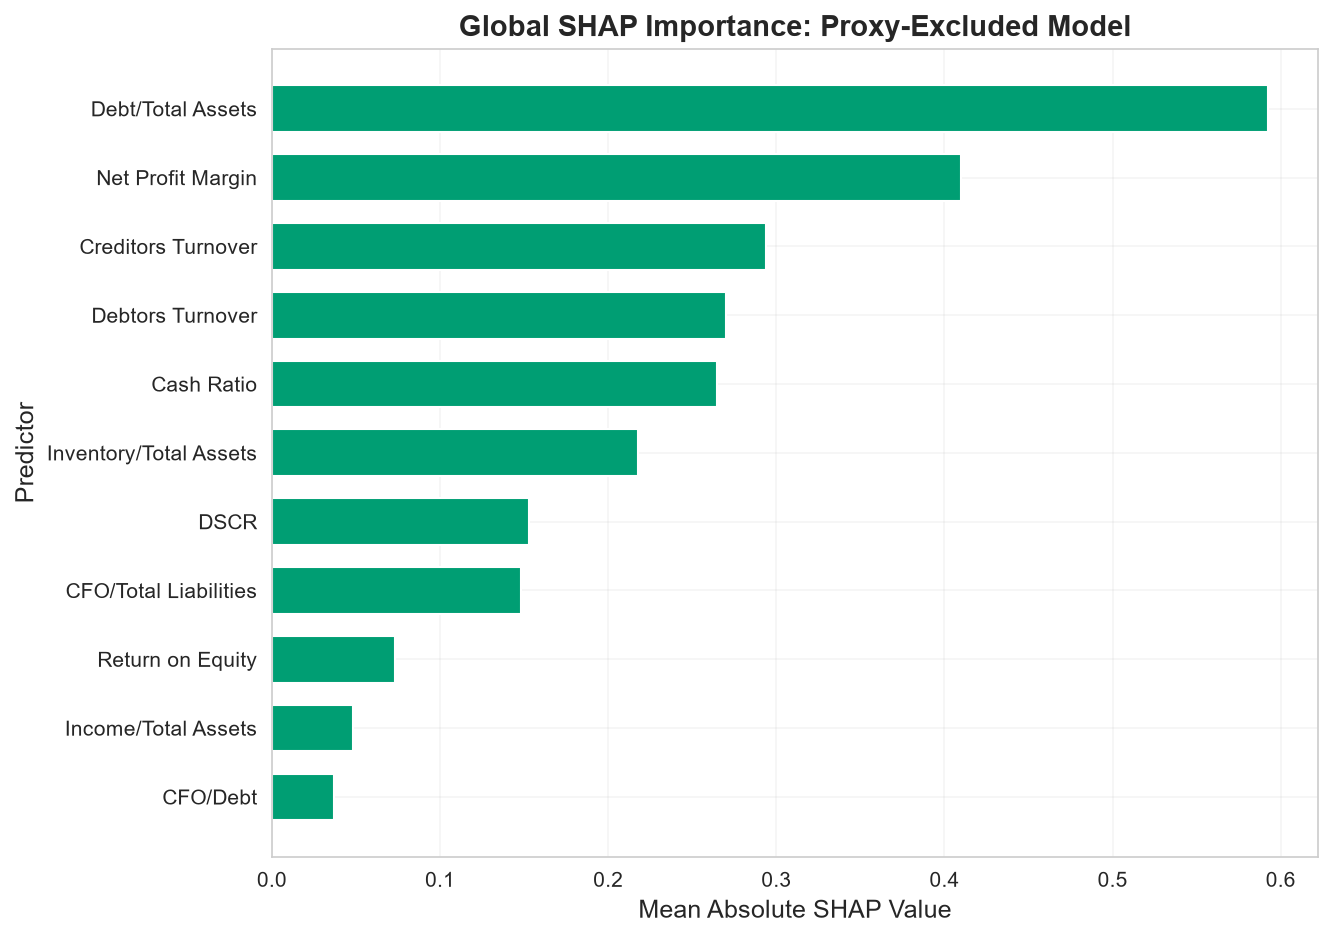

Created: Figure_11_Proxy_Excluded_SHAP_Importance


In [15]:
# ---------------------------------------------------------
# FIGURE 11: PROXY-EXCLUDED SHAP IMPORTANCE
# ---------------------------------------------------------

proxy_df = pd.DataFrame({
    "Feature": list(proxy_free_shap.keys()),
    "Mean_Absolute_SHAP": list(proxy_free_shap.values())
})

proxy_df = proxy_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

fig, ax = plt.subplots(figsize=(9, 7))

ax.barh(
    proxy_df["Feature"],
    proxy_df["Mean_Absolute_SHAP"],
    color=COLORS["STRICT"],
    height=0.68
)

ax.set_title("Global SHAP Importance: Proxy-Excluded Model")
ax.set_xlabel("Mean Absolute SHAP Value")
ax.set_ylabel("Predictor")

save_figure(fig, "Figure_11_Proxy_Excluded_SHAP_Importance")

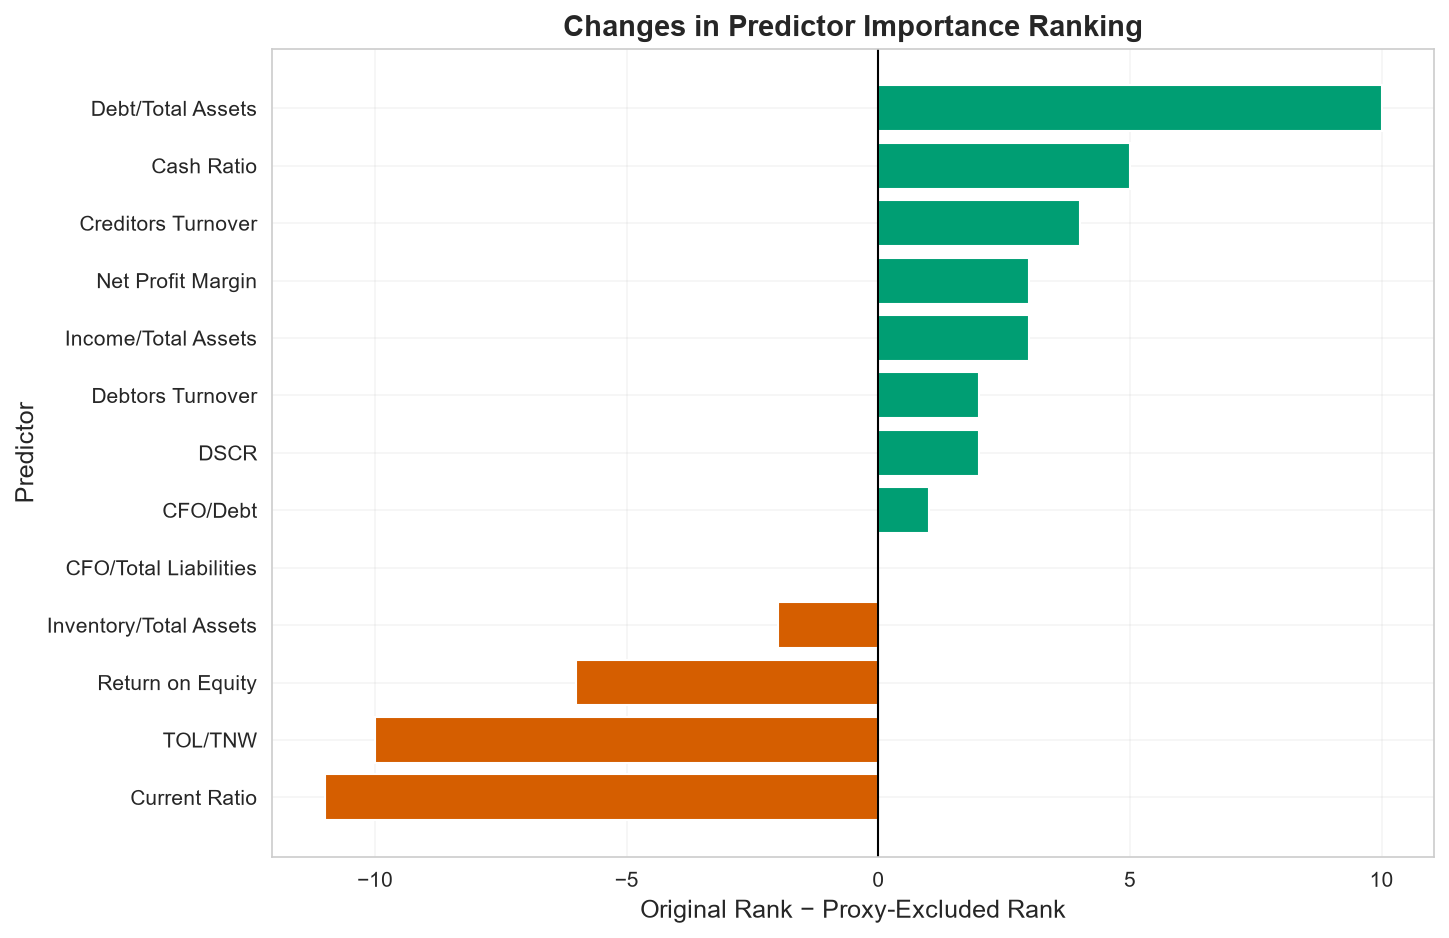

Created: Figure_12_SHAP_Rank_Changes


In [16]:
# ---------------------------------------------------------
# FIGURE 12: SHAP RANK CHANGES
# ---------------------------------------------------------

rank_df = comparison_df.copy()

rank_df["Original Rank"] = (
    rank_df["Original Strict"]
    .rank(ascending=False, method="min")
)

rank_df["Proxy-free Rank"] = (
    rank_df["Proxy-excluded Strict"]
    .rank(ascending=False, method="min")
)

rank_df["Rank Change"] = (
    rank_df["Original Rank"] -
    rank_df["Proxy-free Rank"]
)

rank_df = rank_df.sort_values("Rank Change")

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    rank_df.index,
    rank_df["Rank Change"],
    color=np.where(
        rank_df["Rank Change"] >= 0,
        "#009E73",
        "#D55E00"
    )
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title("Changes in Predictor Importance Ranking")
ax.set_xlabel("Original Rank − Proxy-Excluded Rank")
ax.set_ylabel("Predictor")

save_figure(fig, "Figure_12_SHAP_Rank_Changes")

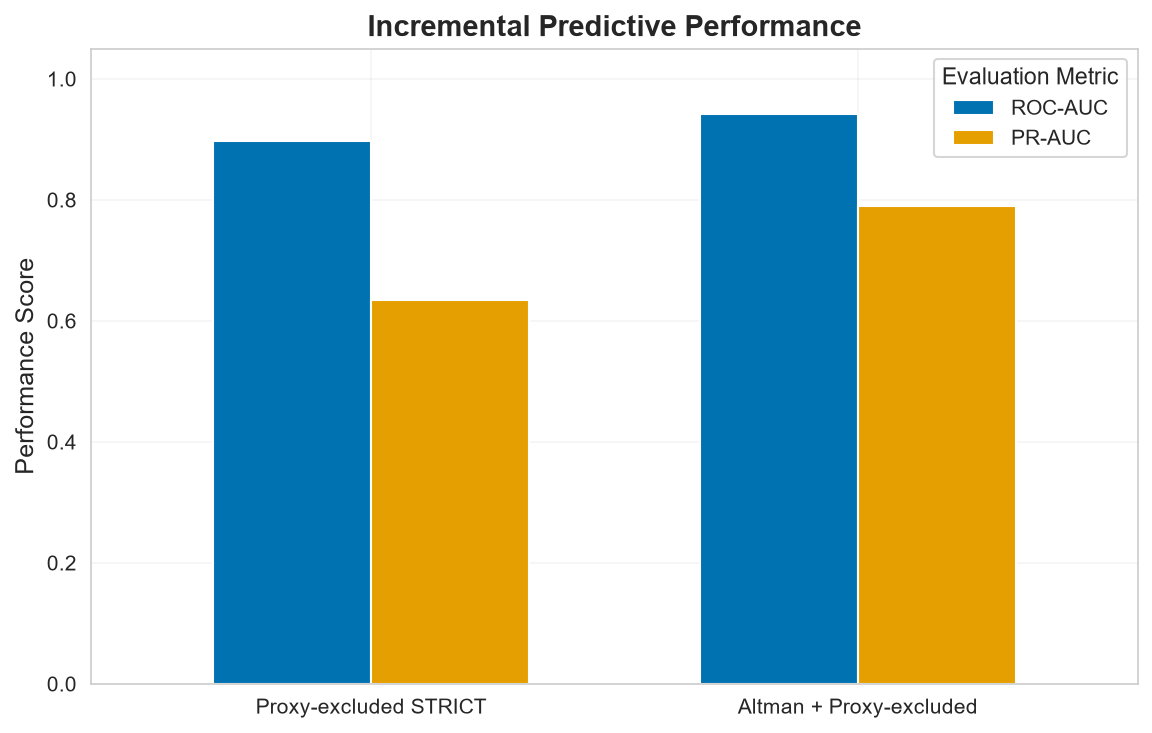

Created: Figure_13_Incremental_Predictive_Performance


In [17]:
# ---------------------------------------------------------
# FIGURE 13: INCREMENTAL PREDICTIVE PERFORMANCE
# ---------------------------------------------------------

incremental_df = pd.DataFrame({
    "Model": [
        "Proxy-excluded STRICT",
        "Altman + Proxy-excluded"
    ],
    "ROC-AUC": [
        0.8971,
        0.9424
    ],
    "PR-AUC": [
        0.6339,
        0.7906
    ]
})

fig, ax = plt.subplots(figsize=(9, 5.5))

incremental_df.set_index("Model").plot(
    kind="bar",
    ax=ax,
    width=0.65,
    color=["#0072B2", "#E69F00"]
)

ax.set_title("Incremental Predictive Performance")
ax.set_ylabel("Performance Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.legend(title="Evaluation Metric")
ax.tick_params(axis="x", rotation=0)

save_figure(fig, "Figure_13_Incremental_Predictive_Performance")

In [19]:
# ---------------------------------------------------------
# FIGURE 15: FIGURE GENERATION SUMMARY
# ---------------------------------------------------------

figure_files = [
    f for f in os.listdir(OUTPUT_DIR)
    if f.lower().endswith((".png", ".tiff"))
]

print("=" * 60)
print("FIGURE GENERATION SUMMARY")
print("=" * 60)

print("Total figure files:", len(figure_files))
print("Output directory:", OUTPUT_DIR)

for filename in sorted(figure_files):
    print(filename)

FIGURE GENERATION SUMMARY
Total figure files: 14
Output directory: C:\Users\iamku\Documents\Financial_Distress_Research\Research_Figures
Figure_01_Annual_Distress_Prevalence.png
Figure_01_Annual_Distress_Prevalence.tiff
Figure_02_Temporal_Data_Partition.png
Figure_02_Temporal_Data_Partition.tiff
Figure_09_Distress_Transition_Distribution.png
Figure_09_Distress_Transition_Distribution.tiff
Figure_10_SHAP_Original_vs_Proxy_Excluded.png
Figure_10_SHAP_Original_vs_Proxy_Excluded.tiff
Figure_11_Proxy_Excluded_SHAP_Importance.png
Figure_11_Proxy_Excluded_SHAP_Importance.tiff
Figure_12_SHAP_Rank_Changes.png
Figure_12_SHAP_Rank_Changes.tiff
Figure_13_Incremental_Predictive_Performance.png
Figure_13_Incremental_Predictive_Performance.tiff
